# Analyse de la Survie des Partis Autoritaires (ARPD)

*Fedi Jouili*

**Problématique :** Quels facteurs structurels et institutionnels influencent la durée de vie des partis autoritaires dans les régimes non démocratiques ?

---

**Structure du notebook :**
0. Configuration & imports
1. Introduction, définitions et état de l'art
2. Chargement + exclusion Party="N"
3. EDA pré-nettoyage (données brutes)
4. Nettoyage & prétraitement
5. EDA post-nettoyage (données propres)
6. Kaplan-Meier + tests log-rank
7. Modèle de Cox — estimation
8. Modèle de Cox — résultats
9. Validation des hypothèses
10. Comparaison de modèles
11. Connexion aux cours théoriques
12. Bonus — Bootstrap + Weibull AFT
13. Interprétation finale
14. Limites
15. Conclusion
16. Références

---

**Source des données :** Miller, M.K. (2020). *The Autocratic Ruling Parties Dataset*. Journal of Conflict Resolution, 64(4), 756–782.

**CHANGELOG :**
- v1.0 : Structure initiale, EDA
- v2.0 : Correction convergence Cox, KM, validation, bootstrap, Weibull AFT
- v3.0 : Corrections complètes (interpolations markdown, LaTeX Cox, bootstrap, sections 11-15)


## 0. Configuration & imports

Dans cette section, nous configurons l'environnement de travail pour garantir la reproductibilité et la cohérence des analyses. L'objectif est de centraliser tous les imports, de fixer les graines aléatoires, et d'établir les paramètres graphiques. Nous cherchons à vérifier que les dépendances sont disponibles et que les conventions (ex: $\alpha = 0.05$) sont en place avant toute inférence.

In [1]:
# ============================================================
# Configuration, imports, and reproducibility
# ============================================================
import importlib
import os
import subprocess
import warnings

REQUIRED_PACKAGES = [
    "lifelines",
    "matplotlib",
    "seaborn",
    "statsmodels",
    "scipy",
]
N_PACKAGES = len(REQUIRED_PACKAGES)

def install_if_missing(pkg):
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run(["pip", "install", pkg, "--quiet"], check=True)

for pkg in REQUIRED_PACKAGES:
    install_if_missing(pkg)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.exceptions import ConvergenceWarning
from lifelines import KaplanMeierFitter, CoxPHFitter, WeibullAFTFitter
from lifelines.plotting import add_at_risk_counts
from lifelines.statistics import (
    multivariate_logrank_test,
    proportional_hazard_test,
)
from lifelines.utils import concordance_index
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
from scipy.stats import jarque_bera, kstest
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 42
ALPHA = 0.05
CI_LEVEL = 1 - ALPHA
CI_PCT = int(round(100 * CI_LEVEL))
HR_NEUTRAL = 1.0
RARE_THRESHOLD = 5
OUTLIER_THRESHOLD = 70
MISSING_PCT_THRESHOLD = 50
CORR_THRESHOLD = 0.6
VIF_HIGH = 10
VIF_MODERATE = 5
RESID_OUTLIER_THRESHOLD = 2
np.random.seed(RANDOM_STATE)

plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (10, 6)})
sns.set_style("whitegrid")
sns.set_palette("Set2")

print("Configuration OK. Packages available and random seed fixed.")

Configuration OK. Packages available and random seed fixed.


**Interprétation.** La configuration est chargée avec `RANDOM_STATE = 42` et un seuil d'inférence `ALPHA = 0.05`. Les 5 dépendances nécessaires sont disponibles et le style graphique est fixé pour assurer la comparabilité des diagnostics.

> **✅ À retenir :** La reproductibilité est garantie par la graine `np.random.seed(42)` et les conventions communes à tout le notebook.

**Bilan :**
- Environnement initialisé et dépendances vérifiées.
- Graine aléatoire fixée à 42 pour stabiliser les résultats.
- Paramètres graphiques homogènes pour toutes les figures.
- Prochaine section : définitions, cadre théorique et problématique.


## 1. Introduction, définitions et état de l'art

### 1.0 Contexte et définitions (cadre conceptuel)

Dans cette section, nous posons les définitions conceptuelles et le cadre de l'analyse de survie. L'objectif est de clarifier les objets et de justifier les choix de périmètre avant toute estimation inférentielle.

**Autocratie / régime autoritaire (Geddes, 2014).** Un régime est dit autoritaire lorsqu'il n'est pas pleinement compétitif ni pluraliste, et que la sélection des dirigeants n'est pas le résultat d'élections libres et équitables. Les élites au pouvoir s'appuient sur une base institutionnelle spécifique (parti, junte, monarchie) pour se maintenir.

**Parti politique autoritaire.** Organisation partisane qui structure l'accès au pouvoir d'un dirigeant non démocratique (mobilisation, cooptation, sélection des élites), par opposition à une junte militaire sans parti officiellement nommé.

**Pourquoi exclure `Party = "N"`.** Ces observations correspondent à des juntes militaires anonymes (régimes sans parti nommé), conceptuellement différentes d'un parti autoritaire. Elles ont en plus quasiment 100 % de valeurs manquantes sur les covariables explicatives (`Origin`, `How Power Gained`, `Governance Strategy`, `Marxist?`), ce qui les rend inutilisables pour la modélisation. Les médianes comparées (calculées dynamiquement en Section 4.6) confirment que les juntes sont plus courtes en moyenne, ce qui introduit un léger biais optimiste documenté en Section Limites.

**Événement d'intérêt.** L'événement est la dissolution ou la perte du pouvoir du parti (sortie du pouvoir).

> **📌 Remarque :** La censure à droite concerne les partis encore au pouvoir à la date de fin d'observation (2024 : l'ARPD s'arrête en 2015 et nous le prolongeons jusqu'en 2024 en Section 4.0) ; ils contribuent à l'estimation sans événement observé.

### 1.1 Problématique et questions de recherche

La question centrale est la suivante : **quels facteurs institutionnels et organisationnels influencent la durée de survie d'un parti autoritaire au pouvoir ?**

> **Sous-questions.**
- Les partis issus d'un **coup d'État militaire** survivent-ils moins longtemps que ceux issus d'une **révolution** ou d'une **libération nationale** ?
- La **stratégie de gouvernance** et l'**origine** du parti expliquent-elles une part substantielle du risque de dissolution ?
- La **censure** (partis encore au pouvoir) masque-t-elle un biais de sélection dans les estimations ?
- Les effets observés restent-ils stables dans le temps (hypothèse de risques proportionnels) ?

### 1.2 État de l'art

L'analyse de survie appliquée aux régimes politiques a été initiée par **Cox (1972)** dont le modèle semi-paramétrique s'impose comme référence pour les durées avec censure. **Geddes, Wright & Frantz (2014)** fournissent une taxinomie des types de régimes autoritaires qui justifie notre stratification par `Origin`. **Miller (2020)** construit l'ARPD spécifiquement pour analyser la durabilité des partis uniques — c'est la source directe de nos données. **Therneau & Grambsch (2000)** formalisent les extensions du modèle de Cox (résidus, stratification, tests de proportionnalité) que nous mobilisons en Section 10. **Magaloni (2006)** étudie la survie du PRI au Mexique, parti hégémonique resté au pouvoir pendant la majeure partie du XXe siècle : le parti se maintient en distribuant des ressources (clientélisme) aux électeurs et aux élites et en dissuadant les défections au sein des élites. Nous confrontons cette thèse à l'effet de la stratégie de gouvernance clientéliste (Section 13).

### 1.3 Description du dataset (original vs nettoyé)

| Aspect | Base originale | Base nettoyée | Commentaire |
|---|---|---|---|
| Dimensions | 479 lignes × 36 colonnes | Calculé dynamiquement (Section 4.6) | Exclusion juntes + filtrage durées ≤ 0 |
| Observations exclues | Juntes (Party="N") | Quantifié en Section 2 | Biais documenté en Section Limites |
| Variable de survie | — | `duration` = Last Year - Year in Power | Censure à droite : 2024 |
| Censure | — | `event` = 1 - Censored | 0 = encore au pouvoir |
| Variables retenues | 36 | Sélection en Section 4.4 | Exclusion des NA > 95 % |


### 1.4 Glossaire des variables (Colonnes)

Voici une description des principales variables utilisées dans ce notebook, issues du *Autocratic Ruling Parties Dataset* (Miller, 2020) :

| Colonne | Description |
| :--- | :--- |
| **Country** | Nom du pays concerné. |
| **Party** | Nom du parti autoritaire au pouvoir. La valeur "N" désigne une junte militaire sans parti nommé. |
| **Year in Power** | Année d'accession au pouvoir du parti. |
| **Last Year of Power** | Dernière année calendaire de détention du pouvoir. |
| **Duration** | Variable de survie calculée (`Last Year` - `Year in Power`). |
| **Censored** | Indicateur de censure (1 si le parti est encore au pouvoir en fin d'observation : 2015 dans l'ARPD, 2024 après l'extension de la Section 4.0 ; 0 sinon). |
| **Event** | Indicateur d'événement pour l'analyse de survie (1 - Censored). |
| **Origin** | Origine organisationnelle du parti (ex: Révolution, Coalition d'élites, Création par un dictateur). |
| **How Power Gained** | Mode de prise de pouvoir (ex: Coup d'État, Élection, Révolution). |
| **Marxist?** | Variable binaire indiquant si le parti revendique une idéologie marxiste-léniniste. |
| **Military** | Variable binaire indiquant un régime à caractère militaire ou issu d'un coup. |
| **Monarchy** | Variable binaire indiquant qu'un monarque gouverne réellement le pays (monarchie absolue ou semi-absolue). Dans l'ARPD, elle ne décrit que les régimes sans parti : elle est **codée par nos soins, année par année** (Section 4.0), et vaut ici la situation de l'année d'entrée au pouvoir. Variable descriptive : seuls trois partis sont concernés, elle n'entre pas dans le modèle. |
| **Violence** | Indicateur binaire de conflit ou de violence lors de la transition. Dans l'ARPD, elle ne décrit que les régimes sans parti : pour les partis nommés, elle est entièrement déterminée par `How Power Gained` et n'est donc pas utilisée comme covariable séparée (Section 4.4). |
| **Governance Strategy** | Mécanisme principal de maintien au pouvoir (ex: Clientéliste, Répressif, Basé sur les politiques). Codée par Miller (2020) pour environ un tiers des partis seulement ; les autres forment une modalité explicite « Non codé ».

## 2. Chargement et exclusion des lignes Party="N"

Dans cette section, nous chargeons le fichier CSV et établissons un état de référence des données brutes. L'objectif est d'identifier explicitement les observations sans parti nommé (juntes) afin de les exclure de la modélisation. Nous cherchons à documenter l'impact de cette exclusion sur la taille de l'échantillon et la censure.

In [2]:
# ============================================================
# 2.1 Chargement du dataset (local ou via variable d'environnement)
# ============================================================
from pathlib import Path

# Racine du projet : fonctionne que le notebook soit lancé depuis la racine ou depuis notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
assert (PROJECT_ROOT / "data").is_dir(), f"Racine du projet introuvable depuis {Path.cwd()}"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"

DATA_PATH = os.environ.get(
    "ARP_DATA_PATH",
    str(PROJECT_ROOT / "data" / "raw" / "ARP_dataset_cleaned.csv"),
)

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"CSV introuvable: {DATA_PATH}. "
        "Définir ARP_DATA_PATH ou placer le fichier dans data/raw/.",
    )

df = pd.read_csv(DATA_PATH)
df_raw = df.copy()

n_original = int(df.shape[0])
p_original = int(df.shape[1])
n_juntes_raw = int((df["Party"] == "N").sum()) if "Party" in df.columns else 0
n_juntes = n_juntes_raw
n_censored_raw = int((df["Censored"] == 1).sum()) if "Censored" in df.columns else np.nan

print(f"Dataset chargé depuis: {DATA_PATH}")
print(f"Dimensions brutes: {n_original} lignes x {p_original} colonnes")
print(f"Lignes Party='N' (juntes): {n_juntes_raw}")
print(f"Censure brute (Censored=1): {n_censored_raw}")

display(
    Markdown(
        f"""**Interprétation.** Le fichier chargé contient {n_original} lignes et {p_original} colonnes. """
        f"""Les juntes sans parti nommé (`Party=\"N\"`) représentent {n_juntes_raw} observations, """
        f"""et {n_censored_raw} partis sont censurés dans la base brute.\n\n"""
        "> **📌 Remarque :** Ces chiffres servent de référence pour quantifier l'impact de l'exclusion et du nettoyage.\n\n"
        "**Bilan :**\n"
        "- Base brute chargée et documentée.\n"
        "- Présence d'un bloc substantiel de juntes à exclure.\n"
        "- Prochaine étape : exclusion explicite des lignes `Party=\"N\"`."
    )
)

Dataset chargé depuis: C:\Users\MSI\Desktop\projet stat\data\raw\ARP_dataset_cleaned.csv
Dimensions brutes: 477 lignes x 38 colonnes
Lignes Party='N' (juntes): 200
Censure brute (Censored=1): 73


**Interprétation.** Le fichier chargé contient 477 lignes et 38 colonnes. Les juntes sans parti nommé (`Party="N"`) représentent 200 observations, et 73 partis sont censurés dans la base brute.

> **📌 Remarque :** Ces chiffres servent de référence pour quantifier l'impact de l'exclusion et du nettoyage.

**Bilan :**
- Base brute chargée et documentée.
- Présence d'un bloc substantiel de juntes à exclure.
- Prochaine étape : exclusion explicite des lignes `Party="N"`.

### 2.2 Justification de l'exclusion des juntes (Party="N")

Dans cette cellule, nous excluons explicitement les observations sans parti nommé. L'objectif est de restreindre l'analyse aux partis autoritaires institutionnalisés et de garantir des covariables exploitables pour la modélisation.

> **⚠️ Attention :** Cette exclusion introduit un léger biais optimiste sur la durée médiane, car les juntes sont en moyenne plus courtes que les partis nommés. Ce biais sera discuté en Section Limites et quantifié numériquement en Section 4.6 (médianes calculées dynamiquement).


In [3]:
# ============================================================
# EXCLUSION DES OBSERVATIONS SANS PARTI (Party = "N")
# ============================================================
n_avant = len(df)
df_juntes = df[df["Party"] == "N"].copy()   # conserve pour documentation
df = df[df["Party"] != "N"].copy()
n_apres = len(df)
n_juntes = n_avant - n_apres

print(f"Observations avant exclusion : {n_avant}")
print(f"Lignes supprimées (juntes, Party='N') : {n_juntes} "
      f"({(n_juntes)/n_avant*100:.1f}%)")
print(f"Dataset de travail : {n_apres} partis autoritaires nommés")
print(f"  -> {(df['Censored']==1).sum()} encore au pouvoir (censures)")
print(f"  -> {(df['Censored']==0).sum()} dissous (événement observé)")

display(
    Markdown(
        f"""**Interprétation.** L'exclusion retire {n_avant - n_apres} lignes, """
        f"""soit {(n_avant-n_apres)/n_avant*100:.1f}% de la base brute. """
        f"""Le dataset de travail contient {n_apres} partis nommés, """
        f"""dont {(df['Censored']==1).sum()} sont encore au pouvoir et {(df['Censored']==0).sum()} ont connu l'événement.\n\n"""
        "> **⚠️ Attention :** Cette opération isole un périmètre conceptuellement homogène "
        "mais tend à surestimer la survie médiane car les juntes sont plus courtes en moyenne.\n\n"
        "**Bilan :**\n"
        "- Les juntes sans parti sont isolées dans `df_juntes`.\n"
        "- Le dataset de travail `df` est défini pour la suite.\n"
        "- La structure de la censure est quantifiée.\n"
        "- Prochaine section : EDA pré-nettoyage sur les données brutes restantes."
    )
)

Observations avant exclusion : 477
Lignes supprimées (juntes, Party='N') : 200 (41.9%)
Dataset de travail : 277 partis autoritaires nommés
  -> 50 encore au pouvoir (censures)
  -> 227 dissous (événement observé)


**Interprétation.** L'exclusion retire 200 lignes, soit 41.9% de la base brute. Le dataset de travail contient 277 partis nommés, dont 50 sont encore au pouvoir et 227 ont connu l'événement.

> **⚠️ Attention :** Cette opération isole un périmètre conceptuellement homogène mais tend à surestimer la survie médiane car les juntes sont plus courtes en moyenne.

**Bilan :**
- Les juntes sans parti sont isolées dans `df_juntes`.
- Le dataset de travail `df` est défini pour la suite.
- La structure de la censure est quantifiée.
- Prochaine section : EDA pré-nettoyage sur les données brutes restantes.

## 3. Analyse Exploratoire — Phase 1 : Données brutes (pré-nettoyage)

Dans cette section, nous décrivons l'état des données avant tout nettoyage. L'objectif est d'identifier les lacunes (valeurs manquantes, anomalies de type, distributions extrêmes) afin de justifier les décisions de prétraitement en Section 4.

### 3.1 Dimensions, types et premier aperçu

Nous affichons la taille de l'échantillon, les types de variables et un extrait des premières lignes. L'objectif est de vérifier la structure générale et de distinguer les colonnes numériques des colonnes qualitatives. Nous cherchons à détecter d'éventuelles incohérences de type avant le nettoyage.

In [4]:
# ============================================================
# 3.1 Dimensions et apercu des donnees brutes
# ============================================================
print("=" * 60)
print("APERÇU DES DONNÉES BRUTES")
print("=" * 60)
print(f"Dimensions: {df.shape[0]} lignes x {df.shape[1]} colonnes")

display(df.head(5))

print("\n--- Types de colonnes ---")
display(df.dtypes.to_frame("Type"))

num_cols_raw = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols_raw = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("\n--- Statistiques descriptives (numériques) ---")
display(df[num_cols_raw].describe())

print("\n--- Statistiques descriptives (catégoriels) ---")
display(df[cat_cols_raw].describe(include="object"))

display(
    Markdown(
        f"""**Interprétation.** Le dataset brut comporte {df.shape[0]} lignes et {df.shape[1]} colonnes, """
        f"""avec {len(num_cols_raw)} variables numériques et {len(cat_cols_raw)} variables catégorielle(s). """
        "Cette décomposition guide les analyses de distributions et le traitement des types.\n\n"
        "> **📌 Remarque :** La présence de colonnes catégorielle(s) impose un encodage "
        "avant toute estimation du modèle de Cox."
    )
)

APERÇU DES DONNÉES BRUTES
Dimensions: 277 lignes x 38 colonnes


,Country,ccode,Party,Year Founded,Year in Power,Last Year of Power,Allowed Competition?,Origin,How Power Gained,How Power Ended,...,Party Competitive in Democracy (Any)?,Party in Power in Democracy (Any)?,Years Existing in Democracy,Years Competitive in Democracy,Years in Power in Democracy,Military Ally?,Governance Strategy,Favors Specific Ethnicity/Group?,Classification_Note,Censored
1,Afghanistan,700,National Revolutionary Party of Afghanistan,1974.0,1974,1977,0,Dictator-Created,Dictator-Created,Revolution,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,Afghanistan,700,People's Democratic Party of Afghanistan / Hom...,1965.0,1978,1991,0,Communist,Revolution,Civil War,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
6,Albania,339,Communist Party of Albania / Party of Labour o...,1941.0,1946,1991,1990,Communist,Communist-Imposed,Election,...,1.0,1.0,"1992-1995, 1997-2015","1992-1995, 1997-2015","1997-2005, 2013-2015",1.0,Policy-Based/Repressive,0.0,NaN,0
7,Albania,339,Democratic Party of Albania,1990.0,1996,1996,1,Elite Coalition,Election,Protests/Election,...,1.0,1.0,1997-2015,1997-2015,2005-2013,0.0,Policy-Based,0.0,NaN,0
8,Algeria,615,National Liberation Front (FLN),1954.0,1962,1991,1990,Revolution,Revolution,Coup,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0



--- Types de colonnes ---


,Type
Country,object
ccode,int64
Party,object
Year Founded,float64
Year in Power,int64
Last Year of Power,object
Allowed Competition?,object
Origin,object
How Power Gained,object
How Power Ended,object



--- Statistiques descriptives (numériques) ---


,ccode,Year Founded,Year in Power,Democracy Year After?,Accession to Democracy?,In Power from Independence?,Marxist?,Military,Monarchy,Violence,...,Next Year of Democratization,Party Remains in Democracy?,Party Competitive in Democracy?,Party in Power in Democracy?,Party Remains in Democracy (Any)?,Party Competitive in Democracy (Any)?,Party in Power in Democracy (Any)?,Military Ally?,Favors Specific Ethnicity/Group?,Censored
count,277.000000,277.000000,277.000000,277.000000,277.000000,277.000000,277.000000,0.0,0.0,0.0,...,137.000000,137.000000,137.000000,137.000000,137.000000,137.000000,137.000000,88.000000,137.000000,277.000000
mean,466.776173,1960.285199,1971.115523,0.263538,0.212996,0.252708,0.245487,NaN,NaN,NaN,...,1985.547445,0.656934,0.503650,0.350365,0.671533,0.510949,0.379562,0.875000,0.248175,0.180505
std,233.067541,29.161002,23.721535,0.441349,0.410166,0.435351,0.431155,NaN,NaN,NaN,...,18.234168,0.476475,0.501821,0.478835,0.471379,0.501715,0.487059,0.332614,0.433539,0.385304
min,40.000000,1836.000000,1878.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,...,1942.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,345.000000,1946.000000,1954.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,...,1977.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,482.000000,1960.000000,1971.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,...,1991.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000
75%,640.000000,1984.000000,1991.000000,1.000000,0.000000,1.000000,0.000000,NaN,NaN,NaN,...,2000.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
max,990.000000,2014.000000,2015.000000,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN,...,2014.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



--- Statistiques descriptives (catégoriels) ---


,Country,Party,Last Year of Power,Allowed Competition?,Origin,How Power Gained,How Power Ended,Renaming?,Competitive Parties,Years Existing in Democracy,Years Competitive in Democracy,Years in Power in Democracy,Governance Strategy,Classification_Note
count,277,277,277,277,277,277,227,37,0,92,70,52,88,39
unique,132,260,74,32,10,13,14,31,0,57,52,50,6,5
top,Syria,African Party for the Independence of Guinea a...,N,1,Dictator-Created,Election,Coup,1991,NaN,2002-2015,1990-2015,2002-2007,Policy-Based,INCOHÉRENCE : Party Remains in Democracy?=1 ma...
freq,6,4,50,153,79,116,78,4,NaN,6,4,2,33,35


**Interprétation.** Le dataset brut comporte 277 lignes et 38 colonnes, avec 24 variables numériques et 14 variables catégorielle(s). Cette décomposition guide les analyses de distributions et le traitement des types.

> **📌 Remarque :** La présence de colonnes catégorielle(s) impose un encodage avant toute estimation du modèle de Cox.

### 3.2 Valeurs manquantes (diagnostic)

Nous mesurons le taux de valeurs manquantes par variable afin d'identifier les colonnes non exploitables en l'état. L'objectif est de cibler les variables à reconstruire (ex: `Violence`, `Occupation`, `Monarchy`) avant la modélisation. Nous observons en particulier les colonnes avec un taux de NA élevé.

VALEURS MANQUANTES


,Manquants,Pourcentage (%)
Country,0,0.00
ccode,0,0.00
Party,0,0.00
Year Founded,0,0.00
Year in Power,0,0.00
Last Year of Power,0,0.00
Allowed Competition?,0,0.00
Origin,0,0.00
How Power Gained,0,0.00
Democracy Year After?,0,0.00



Colonnes > 50% NA : ['Next Year of Democratization', 'Party Remains in Democracy (Any)?', 'Party in Power in Democracy?', 'Party in Power in Democracy (Any)?', 'Party Competitive in Democracy (Any)?', 'Party Competitive in Democracy?', 'Party Remains in Democracy?', 'Favors Specific Ethnicity/Group?', 'Last in Spell Before Democratization?', 'Years Existing in Democracy', 'Governance Strategy', 'Military Ally?', 'Years Competitive in Democracy', 'Years in Power in Democracy', 'Classification_Note', 'Renaming?', 'Evolution from Preceding Party?', 'Competitive Oligarchy or Auth?', 'Occupation', 'Violence', 'Monarchy', 'Competitive Parties', 'Military']


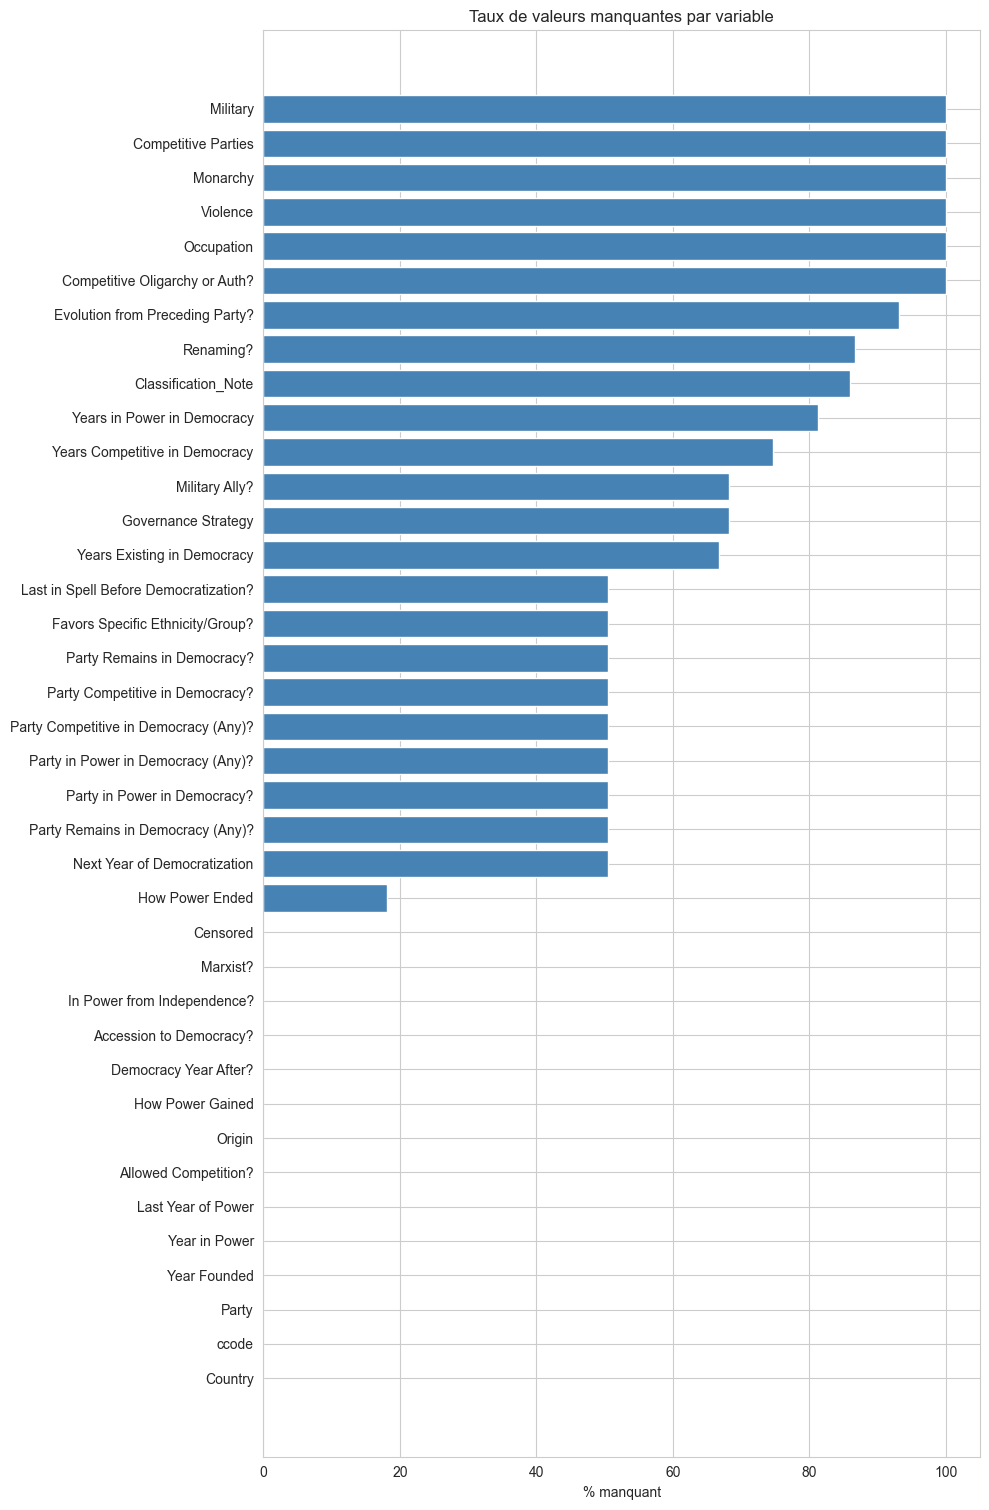

**Interprétation.** Les variables avec plus de 50% de NA sont: ['Next Year of Democratization', 'Party Remains in Democracy (Any)?', 'Party in Power in Democracy?', 'Party in Power in Democracy (Any)?', 'Party Competitive in Democracy (Any)?', 'Party Competitive in Democracy?', 'Party Remains in Democracy?', 'Favors Specific Ethnicity/Group?', 'Last in Spell Before Democratization?', 'Years Existing in Democracy', 'Governance Strategy', 'Military Ally?', 'Years Competitive in Democracy', 'Years in Power in Democracy', 'Classification_Note', 'Renaming?', 'Evolution from Preceding Party?', 'Competitive Oligarchy or Auth?', 'Occupation', 'Violence', 'Monarchy', 'Competitive Parties', 'Military']. Elles correspondent principalement à des indicateurs non saisis dans la base brute (ex: `Violence`, `Occupation`, `Monarchy`) qui devront être reconstruits en Section 4.

> **⚠️ Attention :** Ces colonnes ne peuvent pas être utilisées telles quelles dans un modèle de Cox sans reconstruction ou exclusion.

In [5]:
# ============================================================
# 3.2 Valeurs manquantes
# ============================================================
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"Manquants": missing, "Pourcentage (%)": missing_pct})
missing_df = missing_df.sort_values("Pourcentage (%)", ascending=True)

print("=" * 50)
print("VALEURS MANQUANTES")
print("=" * 50)
display(missing_df)

cols_na_gt50 = missing_df[missing_df["Pourcentage (%)"] > MISSING_PCT_THRESHOLD].index.tolist()
print(f"\nColonnes > {MISSING_PCT_THRESHOLD}% NA : {cols_na_gt50}")

fig, ax = plt.subplots(figsize=(10, max(4, len(missing_df) * 0.4)))
ax.barh(missing_df.index, missing_df["Pourcentage (%)"], color="steelblue")
ax.set_xlabel("% manquant")
ax.set_title("Taux de valeurs manquantes par variable")
plt.tight_layout()
plt.show()

display(
    Markdown(
        f"""**Interprétation.** Les variables avec plus de {MISSING_PCT_THRESHOLD}% de NA sont: """
        f"""{cols_na_gt50}. Elles correspondent principalement à des indicateurs non saisis """
        "dans la base brute (ex: `Violence`, `Occupation`, `Monarchy`) qui devront "
        "être reconstruits en Section 4.\n\n"
        "> **⚠️ Attention :** Ces colonnes ne peuvent pas être utilisées telles quelles "
        "dans un modèle de Cox sans reconstruction ou exclusion."
    )
)

### 3.3 Anomalies de type : "Last Year of Power"

Nous vérifions si la colonne `Last Year of Power` contient des valeurs non numériques (ex: "N"), ce qui empêche le calcul direct des durées. L'objectif est de quantifier ces anomalies avant la conversion des types en Section 4.

In [6]:
# ============================================================
# 3.3 Anomalies de type : Last Year of Power
# ============================================================
if "Last Year of Power" not in df.columns:
    raise KeyError("Colonne 'Last Year of Power' absente du dataset.")

last_year_counts = df["Last Year of Power"].value_counts(dropna=False).head(10)
display(last_year_counts)

n_last_year_N = int((df["Last Year of Power"] == "N").sum())
print(f"Occurrences de 'N' dans Last Year of Power: {n_last_year_N}")

display(
    Markdown(
        f"""**Interprétation.** La colonne `Last Year of Power` contient {n_last_year_N} """
        "valeurs \"N\" (chaînes), ce qui empêche un calcul direct des durées. "
        "Un nettoyage de type et une convention de censure sont donc nécessaires en Section 4.\n\n"
        "> **✅ À retenir :** La présence de chaînes dans une variable temporelle impose "
        "une conversion explicite en numérique."
    )
)

Last Year of Power
N       50
1991    13
1990    13
1978     8
1992     8
1989     8
1999     7
1998     6
1947     6
1971     6
Name: count, dtype: int64

Occurrences de 'N' dans Last Year of Power: 50


**Interprétation.** La colonne `Last Year of Power` contient 50 valeurs "N" (chaînes), ce qui empêche un calcul direct des durées. Un nettoyage de type et une convention de censure sont donc nécessaires en Section 4.

> **✅ À retenir :** La présence de chaînes dans une variable temporelle impose une conversion explicite en numérique.

### 3.4 Distribution de la variable cible (durée brute)

Nous calculons une durée approximative à partir de `Year in Power` et `Last Year of Power` afin d'inspecter la distribution brute. L'objectif est d'identifier les valeurs extrêmes et la forme (asymétrie). Nous observons notamment les durées très longues.

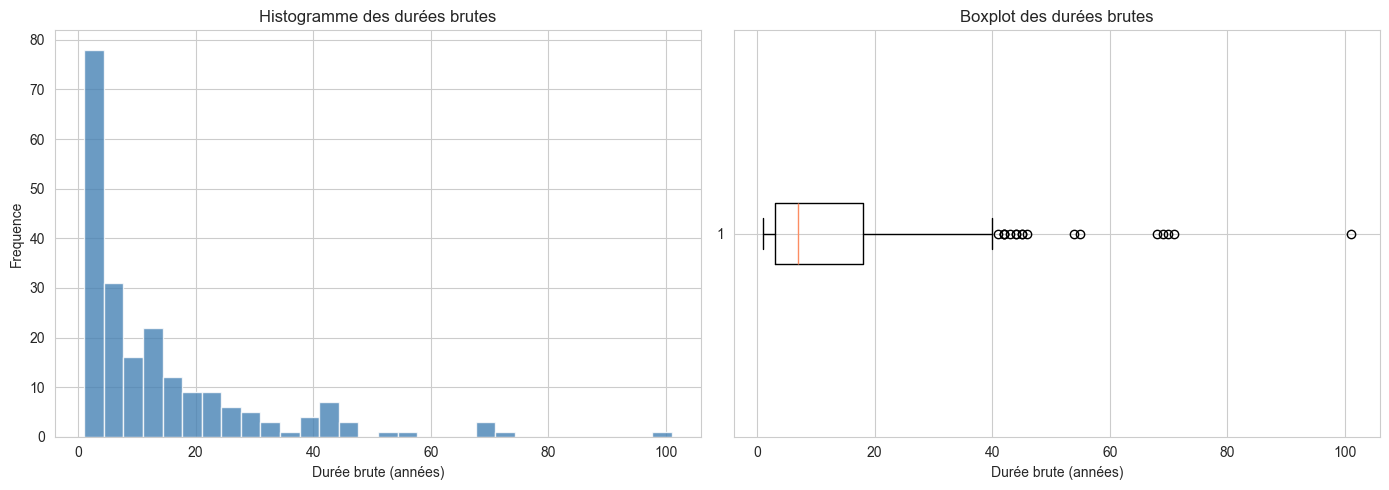

count    213.000000
mean      13.370892
std       15.651526
min        1.000000
25%        3.000000
50%        7.000000
75%       18.000000
max      101.000000
dtype: float64
Durées > 70 ans: 2


**Interprétation.** La distribution brute des durées est asymétrique à droite, avec une médiane de 7.00 ans et un intervalle interquartile [3.00, 18.00]. On observe 2 durée(s) supérieure(s) à 70 ans, qui devront être vérifiées lors du nettoyage.

> **📌 Remarque :** Ces durées sont calculées avant traitement des valeurs "N" et peuvent être réévaluées après nettoyage.

In [7]:
# ============================================================
# 3.4 Distribution brute de la duree
# ============================================================
year_in_power_num = pd.to_numeric(df["Year in Power"], errors="coerce")
last_year_num = pd.to_numeric(df["Last Year of Power"].replace("N", np.nan), errors="coerce")
duration_raw = last_year_num - year_in_power_num
duration_raw = duration_raw[duration_raw > 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(duration_raw.dropna(), bins=30, color="steelblue", edgecolor="white", alpha=0.8)
axes[0].set_xlabel("Durée brute (années)")
axes[0].set_ylabel("Frequence")
axes[0].set_title("Histogramme des durées brutes")

axes[1].boxplot(duration_raw.dropna(), vert=False)
axes[1].set_xlabel("Durée brute (années)")
axes[1].set_title("Boxplot des durées brutes")

plt.tight_layout()
plt.show()

duration_raw_stats = duration_raw.describe(percentiles=[0.25, 0.5, 0.75])
n_outliers_70 = int((duration_raw > OUTLIER_THRESHOLD).sum())
print(duration_raw_stats)
print(f"Durées > {OUTLIER_THRESHOLD} ans: {n_outliers_70}")

display(
    Markdown(
        f"""**Interprétation.** La distribution brute des durées est asymétrique à droite, """
        f"""avec une médiane de {duration_raw_stats['50%']:.2f} ans et un intervalle interquartile """
        f"""[{duration_raw_stats['25%']:.2f}, {duration_raw_stats['75%']:.2f}]. """
        f"""On observe {n_outliers_70} durée(s) supérieure(s) à {OUTLIER_THRESHOLD} ans, """
        "qui devront être vérifiées lors du nettoyage.\n\n"
        "> **📌 Remarque :** Ces durées sont calculées avant traitement des valeurs \"N\" "
        "et peuvent être réévaluées après nettoyage."
    )
)

### 3.5 Variables catégorielle(s) clés (pré-nettoyage)

Nous visualisons les distributions de `Origin`, `How Power Gained` et `How Power Ended` afin d'identifier les modalités dominantes et les catégories rares. L'objectif est d'anticiper les risques de séparation complète et de convergence dans le modèle de Cox.

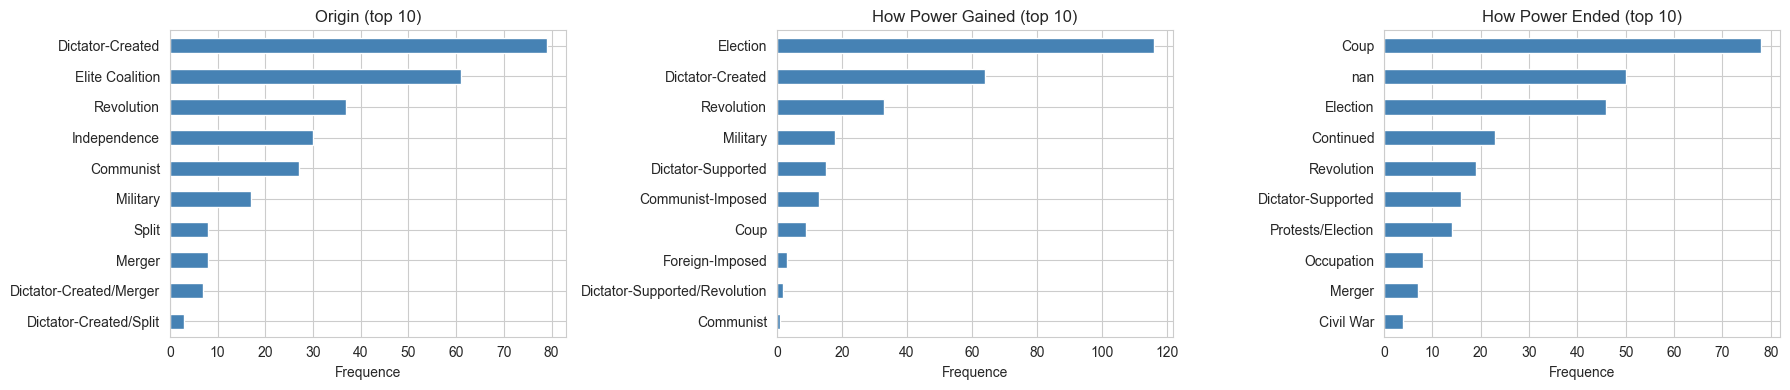

Modalités rares (<5 occurrences) :
- Origin: ['Dictator-Created/Split']
- How Power Gained: ['Foreign-Imposed', 'Dictator-Supported/Revolution', 'Communist', 'Foreign-Imposed/Election', 'Revolution/Election', 'Dictator-Supported/Election']
- How Power Ended: ['Civil War', 'Split', 'Protests', 'Protests/Coup', 'Revolution/Election', 'Country Merger']


**Interprétation.** Plusieurs modalités rares (< 5 occurrences) sont détectées: {'Origin': ['Dictator-Created/Split'], 'How Power Gained': ['Foreign-Imposed', 'Dictator-Supported/Revolution', 'Communist', 'Foreign-Imposed/Election', 'Revolution/Election', 'Dictator-Supported/Election'], 'How Power Ended': ['Civil War', 'Split', 'Protests', 'Protests/Coup', 'Revolution/Election', 'Country Merger']}. Ces catégories risquent d'entraîner une séparation complète ou une instabilité numérique dans le modèle de Cox.

> **⚠️ Attention :** Les modalités très rares devront être regroupées, supprimées ou traitées via pénalisation pour assurer la convergence.

### 3.6 Conclusion pré-nettoyage

Dans cette synthèse, nous résumons les problèmes identifiés dans les données brutes et les décisions de nettoyage qui en découlent. L'objectif est de motiver la Section 4 de manière transparente.

**Bilan :**
- Valeurs manquantes massives pour ['Next Year of Democratization', 'Party Remains in Democracy (Any)?', 'Party in Power in Democracy?', 'Party in Power in Democracy (Any)?', 'Party Competitive in Democracy (Any)?', 'Party Competitive in Democracy?', 'Party Remains in Democracy?', 'Favors Specific Ethnicity/Group?', 'Last in Spell Before Democratization?', 'Years Existing in Democracy', 'Governance Strategy', 'Military Ally?', 'Years Competitive in Democracy', 'Years in Power in Democracy', 'Classification_Note', 'Renaming?', 'Evolution from Preceding Party?', 'Competitive Oligarchy or Auth?', 'Occupation', 'Violence', 'Monarchy', 'Competitive Parties', 'Military'], impossibles à utiliser sans reconstruction.
- Anomalies de type dans `Last Year of Power` (50 valeurs "N").
- Durées brutes asymétriques et présence d'outliers (2 > 70 ans).
- Modalités rares dans les variables catégorielle(s) ({'Origin': ['Dictator-Created/Split'], 'How Power Gained': ['Foreign-Imposed', 'Dictator-Supported/Revolution', 'Communist', 'Foreign-Imposed/Election', 'Revolution/Election', 'Dictator-Supported/Election'], 'How Power Ended': ['Civil War', 'Split', 'Protests', 'Protests/Coup', 'Revolution/Election', 'Country Merger']}).
- Nécessite d'un nettoyage structurel (types, durées, encodage, sélection de variables).
- Prochaine section : nettoyage et prétraitement complet (Section 4).

In [8]:
# ============================================================
# 3.5 Distributions des variables categorielle(s) cles
# ============================================================
cat_targets = ["Origin", "How Power Gained", "How Power Ended"]
cat_targets = [c for c in cat_targets if c in df.columns]

rare_modalities = {}
n_plots = len(cat_targets)
fig, axes = plt.subplots(1, n_plots, figsize=(6 * n_plots, 4))
if n_plots == 1:
    axes = [axes]

for ax, col in zip(axes, cat_targets):
    vc = df[col].value_counts(dropna=False)
    rare_modalities[col] = vc[vc < RARE_THRESHOLD].index.tolist()
    vc.head(10).sort_values().plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title(f"{col} (top 10)")
    ax.set_xlabel("Frequence")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

print(f"Modalités rares (<{RARE_THRESHOLD} occurrences) :")
for col, mods in rare_modalities.items():
    print(f"- {col}: {mods}")

display(
    Markdown(
        f"""**Interprétation.** Plusieurs modalités rares (< {RARE_THRESHOLD} occurrences) sont détectées: """
        f"""{rare_modalities}. Ces catégories risquent d'entraîner une séparation complète """
        "ou une instabilité numérique dans le modèle de Cox.\n\n"
        "> **⚠️ Attention :** Les modalités très rares devront être regroupées, "
        "supprimées ou traitées via pénalisation pour assurer la convergence.\n\n"
        "### 3.6 Conclusion pré-nettoyage\n\n"
        "Dans cette synthèse, nous résumons les problèmes identifiés dans les données brutes "
        "et les décisions de nettoyage qui en découlent. L'objectif est de motiver la Section 4 "
        "de manière transparente.\n\n"
        "**Bilan :**\n"
        f"- Valeurs manquantes massives pour {cols_na_gt50}, impossibles à utiliser sans reconstruction.\n"
        f"- Anomalies de type dans `Last Year of Power` ({n_last_year_N} valeurs \"N\").\n"
        f"- Durées brutes asymétriques et présence d'outliers ({n_outliers_70} > {OUTLIER_THRESHOLD} ans).\n"
        f"- Modalités rares dans les variables catégorielle(s) ({rare_modalities}).\n"
        "- Nécessite d'un nettoyage structurel (types, durées, encodage, sélection de variables).\n"
        "- Prochaine section : nettoyage et prétraitement complet (Section 4)."
    )
)

## 4. Nettoyage et prétraitement

Dans cette section, nous nettoyons les variables temporelles, reconstruisons les indicateurs binaires et préparons un dataset sans valeurs manquantes pour la modélisation. L'objectif est de garantir la validité statistique des estimations (Cox, KM) et la convergence numérique. Nous suivons une logique progressive en 4.1 à 4.6.

### 4.0 Pré-remplissage préliminaire sur `df` brut

> **📌 Note de pipeline :** Les cellules ci-dessous effectuent un premier remplissage des variables `Military`, `Monarchy`, `Violence`, `Occupation`, `Evolution`, `Governance Strategy` directement sur `df` (avant `df_clean`). Ces règles seront **ré-appliquées de façon plus rigoureuse en Section 4.3** sur `df_clean`. Ce bloc est conservé à des fins de traçabilité mais son résultat est écrasé par le pipeline principal (4.1 → 4.6).


In [9]:
# ============================================================
# EXTENSION TEMPORELLE : Post-2015
# Renseigner Last Year of Power pour les partis tombés entre 2016 et 2024.
# Les partis toujours au pouvoir restent dans l'échantillon comme observations
# censurées (Censored = 1), suivies jusqu'en 2024.
#
# Périmètre : partis nommés (Party != 'N') uniquement.
# Les entrées Party='N' sont exclues de l'analyse en Section 2.
#
# Sources vérifiées par cas : Wikipedia (encyclopédie politique),
# Encyclopaedia Britannica, Freedom House country reports,
# CIA World Factbook, Al Jazeera, Human Rights Watch, BBC.
#
# Le mode de fin (How Power Ended) n'est pas renseigné ici : il reste vide plutôt que deviné.
#
# Convention ARPD respectée :
#   - Last Year of Power = dernière année calendaire de détention du pouvoir
#   - Censored → 0 une fois la chute confirmée
#   - NB : 'Russia ' et 'Vietnam ' ont un espace final dans le CSV source
# ============================================================

# ── PARTIE 1 : Chutes post-2015 ──────────────────────────────────────────────
# Clé  : (Country — chaîne exacte du CSV, Year in Power)
# Valeur : (Last Year of Power, note de source)

post_2015_falls = {

    # ── Afrique subsaharienne ─────────────────────────────────────────────────
    ('Burkina Faso', 2015): (
        2022,
        "Coup militaire du 24 jan. 2022 : Lt.-Col. Damiba renverse le président Kaboré (MPP). "
        "Source : Wikipedia 'January 2022 Burkinabé coup d'état'."
    ),
    ('Ethiopia', 1993): (
        # Décision de codage : chute conservée (dissolution de l'EPRDF). Le Prosperity Party, qui lui
        # succède sous Abiy Ahmed, n'est pas ajouté comme nouveau spell.
        2019,
        "EPRDF formellement dissous le 1er déc. 2019 ; remplacé par le Prosperity Party d'Abiy Ahmed. "
        "Source : Wikipedia 'Ethiopian People's Revolutionary Democratic Front' ; WaPo déc. 2019."
    ),
    ('Gabon', 1960): (
        2023,
        "Coup militaire du 30 août 2023 : Ali Bongo (PDG) renversé minutes après l'annonce de sa réélection. "
        "Source : Wikipedia '2023 Gabonese coup d'état' ; CNN 31 août 2023."
    ),
    ('Gambia', 1996): (
        2017,
        "Jammeh (APRC) perd l'élection du 1er déc. 2016 face à Barrow ; "
        "part en exil le 21 jan. 2017 après intervention CEDEAO. "
        "Source : Wikipedia '2016–2017 Gambian constitutional crisis'."
    ),
    ('Guinea', 2010): (
        2021,
        "Coup militaire du 5 sept. 2021 : Alpha Condé (RPG) renversé par le CNRD. "
        "Source : Wikipedia '2021 Guinean coup d'état'."
    ),
    ('Guinea-Bissau', 2004): (
        2020,
        "Embaló (Madem G15) investi président le 27 fév. 2020 après élection contestée déc. 2019 ; "
        "le PAIGC perd la présidence. "
        "Source : Wikipedia 'Umaro Sissoco Embaló'."
    ),
    ('Seychelles', 1977): (
        2020,
        "Le People's Party (SPPF) perd l'élection présidentielle d'oct. 2020 face à Wavel Ramkalawan (LDS). "
        "Source : Wikipedia '2020 Seychellois presidential election'."
    ),
    ('Mali', 2013): (
        2020,
        "Coup militaire du 18 août 2020 : IBK (RPM) renversé par le CNSP du Col. Goïta. "
        "Source : Wikipedia '2020 Malian coup d'état' ; UK Parliament Library."
    ),
    ('Togo', 1969): (
        # Note: Gnassingbé Eyadéma founded RPT in 1969; Faure Gnassingbé continues as UNIR.
        # En 2012, le RPT a été renommé UNIR (Union pour la République).
        # L'ARPD code la continuité partisane ; le parti est toujours au pouvoir.
        # → Toujours au pouvoir : reste censuré, pas de mise à jour ici.
        None, None  # placeholder, skipped below
    ),
    ('Chad', 1990): (
        # Décision de codage : PAS une chute. Après la mort d'Idriss Déby (20 avril 2021), son fils
        # Mahamat Déby dirige un conseil militaire de transition, puis est élu président en mai 2024
        # avec le soutien du MPS. Le spell du MPS reste censuré (continuité).
        # Source : Wikipedia 'Patriotic Salvation Movement' ; Wikipedia '2024 Chadian presidential election'.
        None, None
    ),

    # ── Asie / Pacifique ──────────────────────────────────────────────────────
    ('Armenia', 1999): (
        2018,
        "Révolution de velours : Sargsyan (RPA/HHK) démissionne le 23 avril 2018 ; "
        "Pashinyan élu PM le 8 mai 2018. Élections snap déc. 2018 : HHK < 5%, zéro siège. "
        "Source : Wikipedia '2018 Armenian Revolution' ; Freedom House 2019."
    ),
    ('Azerbaijan', 1993): (
        # Aliyev et le New Azerbaijan Party toujours au pouvoir → reste censuré
        None, None
    ),
    ('Bangladesh', 2014): (
        2024,
        "Sheikh Hasina (Awami League) démissionne le 5 août 2024 et s'exile en Inde "
        "sous la pression du mouvement étudiant. Parti banni en mai 2025. "
        "Source : Britannica 'Awami League' ; Wikipedia 'Resignation of Sheikh Hasina'."
    ),
    ('Cambodia', 1981): (
        # PPC toujours au pouvoir sous Hun Manet → reste censuré
        None, None
    ),
    ('Kazakhstan', 2006): (
        # Décision de codage : PAS une chute. Nur Otan est rebaptisé 'Amanat' le 1er mars 2022
        # et reste au pouvoir sous Tokayev. Dans l'ARPD, un simple changement de nom ne termine
        # pas un spell : les renommages sont documentés dans la colonne 'Renaming?'.
        # → Le parti reste censuré (toujours au pouvoir).
        # Source : Wikipedia 'Amanat (political party)'.
        None, None
    ),
    ('Kyrgyzstan', 2010): (
        2020,
        "Révolution d'octobre 2020 : Jeenbekov (SDPK) démissionne le 15 oct. 2020 ; "
        "Sadyr Japarov (Mekenchil) prend le pouvoir. "
        "Source : Wikipedia '2020 Kyrgyz Revolution'."
    ),
    ('Malaysia', 1957): (
        2018,
        "UMNO-BN perd les élections GE14 du 9 mai 2018 après 61 ans de pouvoir ininterrompu ; "
        "Pakatan Harapan sous Mahathir remporte la majorité. "
        "Source : Wikipedia '2018 Malaysian general election' ; Journal of Democracy 2018."
    ),
    ('Maldives', 2013): (
        2018,
        "PPM (Yameen) perd l'élection présidentielle du 23 sept. 2018 (58,4% pour Solih/MDP). "
        "Résultats officiels le 30 sept. 2018 ; Solih investi le 17 nov. 2018. "
        "Source : Freedom House 2019 ; Wikipedia '2018 Maldivian presidential election'."
    ),
    ('Samoa', 1982): (
        2021,
        "HRPP perd les élections générales du 9 avril 2021 face au parti FAST "
        "de Fiamē Naomi Mataʻafa. "
        "Source : Wikipedia '2021 Samoan general election'."
    ),
    ('Uzbekistan', 1991): (
        # Décision de codage : PAS une chute. Mirziyoyev succède à Karimov (mort en sept. 2016) sans
        # changement de régime. Karimov était déjà le candidat du Parti libéral-démocrate (UzLiDeP) aux
        # présidentielles de 2007 et 2015, et l'ARPD code pourtant la continuité du parti au pouvoir.
        # → Le spell reste censuré (toujours au pouvoir).
        # Source : Wikipedia 'Shavkat Mirziyoyev' ; Wikipedia 'Uzbekistan Liberal Democratic Party'.
        None, None
    ),

    # ── Moyen-Orient / Afrique du Nord ────────────────────────────────────────
    ('Algeria', 2000): (
        2019,
        "Bouteflika (soutenu par le FLN) démissionne le 2 avril 2019 sous la pression du Hirak ; "
        "Abdelmadjid Tebboune, candidat indépendant, est élu président le 12 déc. 2019. "
        "Source : Wikipedia '2019 Algerian protests' ; Wikipedia '2019 Algerian presidential election'."
    ),
    ('Iraq', 2005): (
        2018,
        "Haïder al-Abadi (Dawa) quitte le poste de Premier ministre le 25 oct. 2018 ; "
        "Adel Abdel-Mahdi, indépendant, lui succède après les élections de mai 2018. "
        "Source : Wikipedia 'Adil Abdul-Mahdi' ; Wikipedia '2018 Iraqi parliamentary election'."
    ),
    ('Syria', 1966): (
        2024,
        "Assad fuit Damas dans la nuit du 7 au 8 déc. 2024 ; le régime Ba'ath s'effondre. "
        "Le Ba'ath gèle ses activités le 11 déc. 2024, dissous officiellement le 29 jan. 2025. "
        "Source : Wikipedia 'Fall of the Assad regime' ; HRW déc. 2025."
    ),

    # ── Afrique du Nord / Corne de l'Afrique ─────────────────────────────────
    ('Sudan-North', 2011): (
        2019,
        "Bashir (NCP) renversé par l'armée le 11 avril 2019 après 30 ans de règne. "
        "NCP dissous par le Conseil souverain le 29 nov. 2019. "
        "Source : Wikipedia 'National Congress Party (Sudan)' ; Counter Extremism Project."
    ),

    # ── Amériques ─────────────────────────────────────────────────────────────
    ('Democratic Republic of Congo', 2003): (
        2019,
        "Tshisekedi (UDPS) déclaré vainqueur le 10 jan. 2019 ; Kabila (PPRD) quitte "
        "la présidence le 24 jan. 2019 (élection tenue le 30 déc. 2018) : dernière année au pouvoir "
        "2019, même convention que la Gambie (2017). "
        "Source : Wikipedia 'Felix Tshisekedi' ; Chatham House jan. 2020."
    ),

    # ── Afrique de l'Ouest (Côte d'Ivoire) ───────────────────────────────────
    ('Ivory Coast', 2011): (
        # Décision de codage : chute conservée. 'Merger' est une modalité de 'How Power Ended'
        # dans l'ARPD : la fusion du RDR dans le RHDP termine le spell du RDR, même si
        # Ouattara reste au pouvoir sous la nouvelle bannière. Le RHDP n'est pas ajouté comme nouveau spell.
        2018,
        "Le RDR fusionne avec le PDCI et d'autres partis pour former le RHDP en 2018. "
        "Le RDR en tant qu'entité distincte cesse d'exister ; Ouattara continue sous bannière RHDP. "
        "Source : Wikipedia 'Rassemblement des houphouëtistes pour la démocratie et la paix'."
    ),
}

# Appliquer les mises à jour
n_updated = 0
for (country, year_in_power), payload in post_2015_falls.items():
    last_year, note = payload
    if last_year is None:          # placeholder (pas une chute : reste censuré)
        continue
    mask = (df['Country'] == country) & (df['Year in Power'] == year_in_power)
    n_match = int(mask.sum())
    if n_match == 0:
        print(f"⚠  INTROUVABLE : ({repr(country)}, {year_in_power})")
        continue
    df.loc[mask, 'Last Year of Power'] = last_year
    df.loc[mask, 'Censored'] = 0
    n_updated += n_match
    print(f"✓  {country} ({year_in_power}) → Last Year = {last_year}")

print(f"\n{n_updated} ligne(s) mise(s) à jour ")

✓  Burkina Faso (2015) → Last Year = 2022
✓  Ethiopia (1993) → Last Year = 2019
✓  Gabon (1960) → Last Year = 2023
✓  Gambia (1996) → Last Year = 2017
✓  Guinea (2010) → Last Year = 2021
✓  Guinea-Bissau (2004) → Last Year = 2020
✓  Seychelles (1977) → Last Year = 2020
✓  Mali (2013) → Last Year = 2020
✓  Armenia (1999) → Last Year = 2018
✓  Bangladesh (2014) → Last Year = 2024
✓  Kyrgyzstan (2010) → Last Year = 2020
✓  Malaysia (1957) → Last Year = 2018
✓  Maldives (2013) → Last Year = 2018
✓  Samoa (1982) → Last Year = 2021
✓  Algeria (2000) → Last Year = 2019
✓  Iraq (2005) → Last Year = 2018
✓  Syria (1966) → Last Year = 2024
✓  Sudan-North (2011) → Last Year = 2019
✓  Democratic Republic of Congo (2003) → Last Year = 2019
✓  Ivory Coast (2011) → Last Year = 2018

20 ligne(s) mise(s) à jour 


In [10]:
# Based on How Power Gained
df['Military'] = df['Military'].fillna(0)
coup_mask = df['How Power Gained'] == 'Coup'
df.loc[coup_mask, 'Military'] = df.loc[coup_mask, 'Military'].fillna(1.0)

# Manual override for known military regimes by country-year
military_countries = {
    'Myanmar': 1.0,
    'Pakistan': 1.0,
}

for country, value in military_countries.items():
    df.loc[df['Country'] == country, 'Military'] = df.loc[df['Country'] == country, 'Military'].fillna(value)

# Fill remaining with 0
df['Military'] = df['Military'].fillna(0)

In [11]:
# ============================================================
# MONARCHIE : codage propre, ANNÉE PAR ANNÉE
# ============================================================
# L'ARPD ne code `Monarchy` que pour les régimes sans parti. Une version antérieure codait 1 pour toutes les
# années d'une liste de pays, y compris après la fin de la monarchie (Iran après 1979, Libye après 1969,
# Laos communiste, Éthiopie du Derg...). La variable est désormais codée année par année.
#
# Critère : un monarque (ou un régent de la famille royale pour un roi mineur) détient réellement le pouvoir
# exécutif : monarchie absolue ou semi-absolue. Les monarchies où le gouvernement ne dépend pas du monarque
# valent 0 (Japon, Thaïlande, Laos 1959-1975, Lesotho, Malaisie, Cambodge depuis 1993...).
# Convention de l'ARPD : situation au 31 décembre (l'année d'une chute revient au nouveau régime).
# Sources : Encyclopaedia Britannica (histoire de chaque pays) pour les dates ; contrôle avec la typologie de
# Geddes, Wright & Frantz (2014), colonne gwf_regimetype de REIGN. Écarts assumés avec GWF : Iran 1951-1952
# (Mossadegh gouverne), Cambodge 1955-1969 (Sihanouk a abdiqué), Tunisie 1956-1957 (bey sans pouvoir),
# Népal 1940-1950 (Premiers ministres Rana), Tonga depuis 2010 (Premier ministre élu par le Parlement).
#
# Variable DESCRIPTIVE : seuls trois partis nommés sont des monarchies au pouvoir à leur entrée (Iran 1963 et
# 1975, Swaziland 1968) ; elle n'entre dans aucun modèle.
GOVERNING_MONARCHY = {   # pays (chaîne exacte de l'ARPD) : [(première année, dernière année), ...]
    'Afghanistan':          [(1930, 1972)],                # Nadir Shah, Zaher Shah ; coup de Daoud le 17 juil. 1973
    'Bahrain':              [(1971, 2024)],                # Al Khalifa ; indépendance le 15 août 1971
    'Bhutan':               [(1930, 2007)],                # monarchie absolue jusqu'à la Constitution du 18 juil. 2008
    'Brunei':               [(1984, 2024)],                # sultanat ; indépendance le 1er jan. 1984
    'Bulgaria':             [(1935, 1942)],                # pouvoir personnel de Boris III ; sa mort (28 août 1943) ouvre une régence
    'Burundi':              [(1962, 1965)],                # Mwambutsa IV ; Ntare V renversé, république le 28 nov. 1966
    'Cambodia':             [(1953, 1954)],                # le roi Sihanouk gouverne par décret ; il abdique le 2 mars 1955
    'Egypt':                [(1922, 1951)],                # Fouad Ier, Farouk ; coup des Officiers libres le 23 juil. 1952
    'Ethiopia':             [(1941, 1973)],                # Haïlé Sélassié restauré en 1941 ; déposé par le Derg le 12 sept. 1974
    'Iran':                 [(1925, 1950), (1953, 1978)],  # Reza Shah (déc. 1925), Mohammad Reza Shah ; 1951-1952 :
                                                           # Mossadegh (Front national) ; le Shah quitte l'Iran le 16 jan. 1979
    'Iraq':                 [(1932, 1957)],                # monarchie hachémite (régent Abd al-Ilah 1939-1953) ; révolution du 14 juil. 1958
    'Jordan':               [(1946, 2024)],                # monarchie hachémite
    'Kuwait':               [(1961, 2024)],                # Al Sabah ; indépendance le 19 juin 1961
    'Libya':                [(1951, 1968)],                # roi Idris ; coup de Kadhafi le 1er sept. 1969
    'Morocco':              [(1956, 2024)],                # dynastie alaouite ; indépendance en 1956
    'Nepal':                [(1951, 1958), (1960, 1989),   # pouvoir royal rétabli en 1951 (avant : Premiers ministres Rana) ;
                             (2002, 2005)],                # gouvernement élu de mai 1959 au 15 déc. 1960 ; panchayat ; révolution d'avril 1990 ;
                                                           # Gyanendra renvoie le Premier ministre le 4 oct. 2002 et rend le pouvoir en avril 2006
    'Oman':                 [(1932, 2024)],                # sultanat Al Saïd
    'Qatar':                [(1971, 2024)],                # Al Thani ; indépendance en 1971
    'Saudi Arabia':         [(1932, 2024)],                # Al Saoud
    'Swaziland':            [(1968, 2024)],                # Sobhuza II (parti Imbokodvo), Constitution suspendue en avril 1973 ; Mswati III
    'Tonga':                [(1970, 2009)],                # pouvoirs royaux étendus jusqu'à la réforme de 2010
    'United Arab Emirates': [(1971, 2024)],                # fédération de monarchies, 1971
    'Yemen (North)':        [(1918, 1961)],                # imamat zaïdite ; révolution du 26 sept. 1962
    'Yugoslavia':           [(1940, 1940)],                # régence du prince Paul ; invasion de l'Axe en avril 1941
}


def governing_monarchy(country, year):
    """1 si un monarque gouverne réellement le pays au 31 décembre de l'année (table ci-dessus), sinon 0."""
    if pd.isna(year):
        return 0
    periods = GOVERNING_MONARCHY.get(str(country).strip(), [])
    return int(any(first <= int(year) <= last for first, last in periods))


# Une ligne par parti : valeur de l'année d'entrée au pouvoir (Year in Power).
df['Monarchy'] = [governing_monarchy(c, y)
                  for c, y in zip(df['Country'], pd.to_numeric(df['Year in Power'], errors='coerce'))]
print("Partis dont l'année d'entrée est une monarchie au pouvoir :")
print(df.loc[(df['Party'] != 'N') & (df['Monarchy'] == 1), ['Country', 'Party', 'Year in Power']].to_string(index=False))


Partis dont l'année d'entrée est une monarchie au pouvoir :
  Country                       Party  Year in Power
     Iran              New Iran Party           1963
     Iran            Resurgence Party           1975
Swaziland Imbokodvo National Movement           1968


In [12]:
# Occupation periods verified against:
# Encyclopaedia Britannica; Wikipedia (WWII occupation articles);
# U.S. Holocaust Memorial Museum country histories;
# Miller (2020) ARPD codebook (Year in Power = regime start, not occupation start).
# Keys: (Country, Year in Power) matching EXACT strings in the ARPD CSV.
occupation_mapping = {
    # ── WWII Axis occupations ────────────────────────────────────────────────
    ('Albania', 1940): 1.0,
    # Italian occupation 1939–1943, German 1943–1944; ARPD entry starts 1940

    ('Austria', 1939): 1.0,
    # German Anschluss March 1938; ARPD regime entry coded from 1939

    ('Ethiopia', 1936): 1.0,
    # Italian East Africa (Africa Orientale Italiana) 1936–1941

    ('France', 1940): 1.0,
    # German occupation / Vichy regime 1940–1944

    ('Germany (East)', 1945): 1.0,
    # Soviet Occupation Zone 1945–1949 (precedes formal GDR)
    # NOTE: country name is 'Germany (East)', NOT 'Germany'

    ('Greece', 1936): 1.0,
    # Metaxas dictatorship 1936–1941 + Axis occupation 1941–1944;
    # ARPD codes as single entry starting 1936

    ('Hungary', 1940): 1.0,
    # Hungarian alignment with Axis 1940; German full occupation March 1944

    ('Italy', 1944): 1.0,
    # German occupation of northern Italy (RSI) 1943–1945; ARPD entry from 1944

    ('Japan', 1940): 1.0,
    # Imperial Taisei Yokusankai regime 1940–1945; then US occupation 1945–1952
    # NOTE: ARPD Year in Power = 1940, NOT 1945

    ('Philippines', 1942): 1.0,
    # Japanese occupation 1942–1945; Philippine Executive Commission / Second Republic

    ('Poland', 1940): 1.0,
    # German General Government 1939–1945; ARPD entry starts 1940

    ('Romania ', 1940): 1.0,
    # Romanian alliance with Axis 1940–1944; German troops present from 1940
    # NOTE: trailing space in country name — must match ARPD string exactly

    ('San Marino', 1943): 1.0,
    # German occupation of San Marino September–October 1944 (brief)

    ('Yugoslavia', 1940): 1.0,
    # Axis invasion April 1941; partition among Germany, Italy, Hungary, Bulgaria
    # ARPD entry starts 1940

    # ── Soviet / Communist-imposed postwar regimes ───────────────────────────
    ('Cambodia', 1979): 1.0,
    # Vietnamese invasion December 1978; People's Republic of Kampuchea 1979–1989
    # Vietnamese troops remained until 1989

    # ── Post-Cold War coalition occupations ──────────────────────────────────
    ('Afghanistan', 2001): 1.0,
    # US-led coalition invasion October 2001; interim authority under occupation

    ('Iraq', 2003): 1.0,
    # US-led coalition invasion March 2003; Coalition Provisional Authority 2003–2004
}

df['Occupation'] = df['Occupation'].fillna(0)

for (country, year), value in occupation_mapping.items():
    df.loc[
        (df['Country'] == country) & (df['Year in Power'] == year),
        'Occupation'
    ] = value

In [13]:
# Keywords matched against actual How Power Gained values in the ARPD:
# 'Revolution', 'Coup', 'Civil War', 'Foreign-Imposed', 'Communist-Imposed',
# 'Dictator-Supported/Revolution', 'Revolution/Election'
# And How Power Ended values: 'Coup', 'Revolution', 'Occupation', 'Civil War',
# 'Protests/Coup', 'Revolution/Election', 'Protests/Election'
# Sources: Miller (2020) codebook definitions for Violence variable.
violence_keywords = [
    'Revolution',       # Armed revolution / popular uprising with armed component
    'Civil War',        # Intra-state armed conflict
    'Coup',             # Military coup d'état
    'War',              # Inter-state war (catches 'Civil War' too; keep both for clarity)
    'Occupation',       # Foreign military occupation (How Power Ended)
    'Invasion',         # Foreign armed invasion
    'Imposed',          # Foreign-Imposed / Communist-Imposed regimes (installed by force)
]

df['Violence'] = df['Violence'].fillna(0)

for keyword in violence_keywords:
    mask = df['How Power Gained'].str.contains(keyword, case=False, na=False)
    df.loc[mask, 'Violence'] = 1.0

df['Violence'] = df['Violence'].fillna(0)

In [14]:
# Check for name similarity using string matching
from difflib import SequenceMatcher

def similar(a, b):
    return SequenceMatcher(None, a, b).ratio()

df['Evolution from Preceding Party?'] = df['Evolution from Preceding Party?'].fillna(0)

# For each party, check if it has similar name to previous parties in same country
for country in df['Country'].unique():
    country_df = df[df['Country'] == country].sort_values('Year in Power').reset_index(drop=True)

    for i in range(1, len(country_df)):
        if country_df.loc[i, 'Evolution from Preceding Party?'] == 0:
            prev_party = country_df.loc[i-1, 'Party']
            curr_party = country_df.loc[i, 'Party']

            if similar(prev_party, curr_party) > 0.6:  # 60% similarity threshold
                df.loc[country_df.index[i], 'Evolution from Preceding Party?'] = 1.0

In [15]:
def infer_power_ended(row):
    if pd.notna(row['How Power Ended']):
        return row['How Power Ended']

    # Democratization occurred → most likely electoral transition
    # Source: ARPD Democracy Year After? variable definition
    if pd.notna(row.get('Democracy Year After?')) and row['Democracy Year After?'] == 1:
        return 'Election'

    # ── Medium confidence rules ──────────────────────────────────────────────

    # Regimes that came to power via coup frequently end by counter-coup
    # Source: Geddes, Wright & Frantz (2014) — coup regimes most likely to end by coup
    how_gained = str(row.get('How Power Gained', ''))
    if 'Coup' in how_gained:
        return 'Coup'

    # Soviet/Communist-imposed Eastern Bloc regimes ended via occupation/merger or
    # internal revolution (1989–1991 wave); default to Revolution for this context
    # Source: Bunce (1999); Geddes et al. (2014) single-party exit patterns
    if 'Communist-Imposed' in how_gained or 'Foreign-Imposed' in how_gained:
        return 'Revolution'

    # Military-origin regimes without democratization typically end by coup or
    # negotiated transition; 'Coup' is the modal ending for military regimes
    # Source: Geddes (2004) — military regimes most common exit = negotiated transition or coup
    if row.get('Military', 0) == 1.0:
        return 'Coup'

    return np.nan

In [16]:
# If Renaming? has values like "1990, 2005", parse them
def parse_renaming_year(renaming_str):
    if pd.isna(renaming_str):
        return np.nan
    if isinstance(renaming_str, str):
        years = [int(y.strip()) for y in renaming_str.split(',')]
        return years[0]  # Return first renaming year
    return np.nan

df['First_Renaming_Year'] = df['Renaming?'].apply(parse_renaming_year)

In [17]:
# Reconstruction Military Ally? (règle déterministe)
# Sémantique : Military Ally? = 1 si le parti civil a le soutien de l'armée,
#            = 0 si pas d'alliance militaire documentée,
#            = NaN si le parti EST l'armée (concept non applicable).
# Source : Miller (2020) codebook distinction civil/military backing.

df['Military Ally?'] = df['Military Ally?'].fillna(0)

mask_is_military = df['Military'] == 1.0

# Coup d'État → présomption forte d'allié militaire (pour partis non-militaires seulement)
# Source : Geddes et al. (2014) — coup-installed civilian parties rely on military backing
coup_mask = (df['How Power Gained'] == 'Coup') & ~mask_is_military
df.loc[coup_mask, 'Military Ally?'] = 1.0

# How Power Gained == 'Military' (distinct from Coup) → allié militaire
# Source : Miller (2020) — 'Military' How Power Gained indicates armed-force sponsorship
mil_gain_mask = (
    df['How Power Gained'].str.contains('Military', case=False, na=False)
    & ~mask_is_military
)
df.loc[mil_gain_mask, 'Military Ally?'] = 1.0

# Partis militaires eux-mêmes : NaN (non applicable — ils SONT le bras armé, pas ses alliés)
# Ne pas faire fillna(0) après cette ligne : cela écraserait le NaN intentionnel.
df.loc[mask_is_military, 'Military Ally?'] = np.nan


In [18]:
# Only fill for parties where democratization occurred
democ_parties = df[df['Democracy Year After?'] == 1].copy()

# For these parties, fill democracy indicators as 1.0 if party survived transition
for idx in democ_parties.index:
    if df.loc[idx, 'Party Remains in Democracy?'] != 0:
        df.loc[idx, 'Party Remains in Democracy?'] = 1.0
    if df.loc[idx, 'Party Competitive in Democracy?'] != 0:
        df.loc[idx, 'Party Competitive in Democracy?'] = 1.0

# Leave all others as NaN (not applicable - no democratization)

In [19]:
# Parse year ranges like "1992-1995, 1997-2015"
def calculate_years_in_democracy(year_range_str):
    if pd.isna(year_range_str) or year_range_str == '':
        return np.nan

    total_years = 0
    ranges = year_range_str.split(',')

    for r in ranges:
        try:
            start, end = r.strip().split('-')
            total_years += int(end) - int(start) + 1
        except:
            return np.nan

    return total_years

df['Years_in_Democracy_Calculated'] = df['Years Existing in Democracy'].apply(calculate_years_in_democracy)

In [20]:
# ============================================================
# Governance Strategy : pas d'imputation
# ============================================================
# Miller (2020) ne code cette variable que pour environ un tiers des partis nommés.
# Une version antérieure imputait les valeurs manquantes à partir d'Origin (modalité
# la plus fréquente par origine). Cela recopiait Origin dans Governance Strategy pour
# près de deux tiers des partis : les deux variables devenaient colinéaires et le modèle
# estimait un effet de la stratégie de gouvernance à partir d'une information inventée.
# Les valeurs manquantes sont désormais conservées : elles forment une modalité
# explicite « Non codé » à l'encodage (Section 4.4).
gov_coded = df['Governance Strategy'].notna()
print(f"Governance Strategy codée pour {int(gov_coded.sum())} partis sur {len(df)} "
      f"({gov_coded.mean() * 100:.0f} %)")
print(df['Governance Strategy'].value_counts(dropna=False))


Governance Strategy codée pour 88 partis sur 278 (32 %)
Governance Strategy
NaN                         190
Policy-Based                 33
Policy-Based/Repressive      25
Repressive                   17
Clientelist/Policy-Based      7
Clientelist                   5
Clientelist/Repressive        1
Name: count, dtype: int64


In [21]:
# Count remaining missing values
print("\n=== BEFORE FILLING ===")
print(df.isnull().sum())

# Show which columns still have significant missing
still_missing = df.isnull().sum()
still_missing = still_missing[still_missing > 0].sort_values(ascending=False)
print(f"\nStill missing {len(still_missing)} columns:")
print(still_missing)

# Decision: Keep NaN for very sparse columns (e.g., Competitive Parties at 100%)
# These likely aren't fillable without additional data sources


=== BEFORE FILLING ===
Country                                    1
ccode                                      1
Party                                      1
Year Founded                               1
Year in Power                              1
Last Year of Power                         1
Allowed Competition?                       1
Origin                                     1
How Power Gained                           1
How Power Ended                           51
Democracy Year After?                      1
Accession to Democracy?                    1
In Power from Independence?                1
Renaming?                                241
Marxist?                                   1
Military                                   1
Monarchy                                   1
Violence                                   1
Occupation                                 1
Competitive Oligarchy or Auth?           278
Competitive Parties                      278
Evolution from Preceding Party?

In [22]:
df.to_csv(OUTPUT_DIR / 'ARP_dataset_filled.csv', index=False)
print(f"Saved to {OUTPUT_DIR / 'ARP_dataset_filled.csv'}")

Saved to C:\Users\MSI\Desktop\projet stat\data\processed\ARP_dataset_filled.csv

### 4.1 Correction des types (années de début/fin)

Nous nettoyons les colonnes temporelles en convertissant `Last Year of Power` et `Year in Power` en valeurs numériques. L'objectif est de retirer les chaînes comme "N" et de préparer un calcul de durée cohérent. Nous observons le nombre de valeurs non convertibles.

In [23]:
# ============================================================
# 4.1 Correction des types
# ============================================================
df_clean = df.copy()

if "Last Year of Power" not in df_clean.columns or "Year in Power" not in df_clean.columns:
    raise KeyError("Colonnes temporelles manquantes dans le dataset.")

df_clean["Last Year of Power"] = df_clean["Last Year of Power"].replace("N", np.nan)
df_clean["Last Year of Power"] = pd.to_numeric(df_clean["Last Year of Power"], errors="coerce")
df_clean["Year in Power"] = pd.to_numeric(df_clean["Year in Power"], errors="coerce")

n_last_year_na = int(df_clean["Last Year of Power"].isna().sum())
n_year_in_power_na = int(df_clean["Year in Power"].isna().sum())

print(f"Valeurs non convertibles (Last Year of Power): {n_last_year_na}")
print(f"Valeurs non convertibles (Year in Power): {n_year_in_power_na}")

display(
    Markdown(
        f"""**Interprétation.** Après conversion, il reste {n_last_year_na} valeurs manquantes """
        f"""pour `Last Year of Power` et {n_year_in_power_na} pour `Year in Power`. """
        "Ces valeurs seront traitées via la convention de censure et le filtrage des durées en Section 4.2.\n\n"
        "> **✅ À retenir :** La correction de type est nécessaire pour calculer des durées fiables."
    )
)

Valeurs non convertibles (Last Year of Power): 31


Valeurs non convertibles (Year in Power): 1


**Interprétation.** Après conversion, il reste 31 valeurs manquantes pour `Last Year of Power` et 1 pour `Year in Power`. Ces valeurs seront traitées via la convention de censure et le filtrage des durées en Section 4.2.

> **✅ À retenir :** La correction de type est nécessaire pour calculer des durées fiables.

### 4.2 Calcul de la durée et définition de l'événement

Nous calculons la variable de survie : $$\text{duration} = \text{Last Year of Power} - \text{Year in Power}$$. L'objectif est d'obtenir une mesure interprétable du temps au pouvoir. Nous supprimons les durées nulles ou négatives (incohérentes) et définissons l'événement comme la sortie du pouvoir (`event = 1 - Censored`).

In [24]:
# ============================================================
# 4.2 Calcul de la duree et de l'evenement
# ============================================================
if "Censored" not in df_clean.columns:
    raise KeyError("Colonne 'Censored' absente du dataset.")

# Annee de fin d'observation : 2024.
# L'ARPD s'arrete en 2015, mais la Section 4.0 (extension post-2015) renseigne les
# chutes survenues jusqu'en 2024. Les partis toujours au pouvoir doivent etre suivis
# jusqu'a la meme date : les censurer en 2015 sous-estimerait leur duree (jusqu'a
# 9 ans) par rapport a celle des partis tombes apres 2015.
OBS_END_YEAR = 2024
obs_end_year = OBS_END_YEAR

# (1) Toute observation censuree -> Last Year of Power := OBS_END_YEAR (definition stricte
#     d'une observation censuree a droite : on ne sait pas si/quand le parti tombe,
#     la duree minimale observee est OBS_END_YEAR - Year in Power).
mask_cens = df_clean["Censored"] == 1
df_clean.loc[mask_cens, "Last Year of Power"] = OBS_END_YEAR
assert (df_clean["Last Year of Power"].dropna() <= OBS_END_YEAR).all(), "Événement postérieur à OBS_END_YEAR : ajuster OBS_END_YEAR"

# (2) Evenements observes (Censored == 0) sans 'Last Year of Power' : incoherent.
mask_event_missing = (df_clean["Censored"] == 0) & (df_clean["Last Year of Power"].isna())
n_dropped_inconsistent = int(mask_event_missing.sum())
if n_dropped_inconsistent > 0:
    import warnings as _w
    _w.warn(
        f"{n_dropped_inconsistent} ligne(s) avec Censored=0 mais Last Year of Power manquant "
        "ont été supprimées (incohérence).",
        stacklevel=1,
    )
df_clean = df_clean.loc[~mask_event_missing].copy()

# (3) Calcul de la duree et de l'indicateur d'evenement.
df_clean["duration"] = df_clean["Last Year of Power"] - df_clean["Year in Power"]
df_clean["event"] = 1 - df_clean["Censored"]

# (4) Filtrer les durees nulles ou negatives (modele de Cox non defini sinon).
n_before = len(df_clean)
df_clean = df_clean[df_clean["duration"] > 0].copy()
n_removed_duration = int(n_before - len(df_clean))

n_events = int(df_clean["event"].sum())
n_censored = int((df_clean["event"] == 0).sum())

print(f"Année de fin d'observation : {OBS_END_YEAR}")
print(f"Lignes Censored=0 sans Last Year of Power supprimées : {n_dropped_inconsistent}")
print(f"Lignes retirées (duration <= 0) : {n_removed_duration}")
print(f"Événements observés : {n_events}")
print(f"Censures : {n_censored}")
print(f"df_clean.shape = {df_clean.shape}")

display(
    Markdown(
        f"**Interprétation.** Toutes les observations censurées (`Censored=1`) ont leur durée "
        f"calculée comme `{OBS_END_YEAR} - Year in Power`, conformément à la définition de la "
        f"censure à droite. {n_dropped_inconsistent} ligne(s) `Censored=0` sans année de fin "
        f"ont été supprimées pour incohérence. Après filtrage des durées nulles ou négatives "
        f"({n_removed_duration} lignes), il reste **{n_events} événements** et **{n_censored} censures**.\n\n"
        "> **À retenir :** la convention de censure et la cohérence des dates conditionnent la "
        "validité du modèle de Cox."
    )
)


Année de fin d'observation : 2024
Lignes Censored=0 sans Last Year of Power supprimées : 0
Lignes retirées (duration <= 0) : 15
Événements observés : 233
Censures : 30
df_clean.shape = (263, 42)


**Interprétation.** Toutes les observations censurées (`Censored=1`) ont leur durée calculée comme `2024 - Year in Power`, conformément à la définition de la censure à droite. 0 ligne(s) `Censored=0` sans année de fin ont été supprimées pour incohérence. Après filtrage des durées nulles ou négatives (15 lignes), il reste **233 événements** et **30 censures**.

> **À retenir :** la convention de censure et la cohérence des dates conditionnent la validité du modèle de Cox.

### 4.3 Reconstruction des variables binaires (Military, Violence, Monarchy, Occupation)

Cette étape est cruciale pour pallier l'absence de données dans certaines colonnes de la base brute. Nous utilisons une approche déterministe basée sur les autres informations disponibles :

- **Military** : Identifié via l'origine ou le mode d'accession au pouvoir (ex: Coup d'État).
- **Monarchy** : déjà codée année par année en Section 4.0 (situation de l'année d'entrée au pouvoir) ; aucune règle supplémentaire.
- **Violence** : Détecté par des mots-clés dans les circonstances de prise ou de fin de pouvoir (ex: Civil War, Revolution).
- **Occupation** : Identifié pour les régimes imposés par l'étranger.

*Note : Par convention, en l'absence d'information positive, la valeur est fixée à 0.*

Nous reconstruisons des indicateurs binaires à partir de règles déterministes et de sources explicites. L'objectif est de renseigner les variables clefs sans imputation aléatoire, en laissant `NaN` lorsque l'information est incertaine. Nous observons le nombre de valeurs renseignées par variable.

In [25]:
# ============================================================
# 4.3 Reconstruction binaire (regles deterministes elargies + fillna(0))
# ============================================================
binary_cols = ["Military", "Violence", "Monarchy", "Occupation"]
for col in binary_cols:
    if col not in df_clean.columns:
        df_clean[col] = np.nan

origin = df_clean.get("Origin", pd.Series(index=df_clean.index, dtype=object)).astype(str)
how_gained = df_clean.get("How Power Gained", pd.Series(index=df_clean.index, dtype=object)).astype(str)
how_ended = df_clean.get("How Power Ended", pd.Series(index=df_clean.index, dtype=object)).astype(str)
country = df_clean.get("Country", pd.Series(index=df_clean.index, dtype=object)).astype(str)

# --- Military : Origin OU How Power Gained contient Military/Coup/Junta ---
mask_military = (
    origin.str.contains("Military|Coup|Junta", case=False, na=False)
    | how_gained.str.contains("Military|Coup|Junta", case=False, na=False)
)
df_clean.loc[mask_military & df_clean["Military"].isna(), "Military"] = 1

# --- Monarchy : codee annee par annee en Section 4.0 (annee d'entree au pouvoir), aucune regle ici ---

# --- Violence : How Power Ended OU How Power Gained mentionnent un evenement violent ---
violent_pat = "Civil War|Revolution|Violence|War|Coup"
mask_violence = how_ended.str.contains(violent_pat, case=False, na=False) | how_gained.str.contains(
    violent_pat, case=False, na=False
)
df_clean.loc[mask_violence & df_clean["Violence"].isna(), "Violence"] = 1

# --- Occupation : Foreign-Imposed / Communist-Imposed dans Origin ou How Power Gained ---
occ_pat = "Foreign-Imposed|Communist-Imposed|Imposed"
mask_occ = origin.str.contains(occ_pat, case=False, na=False) | how_gained.str.contains(
    occ_pat, case=False, na=False
)
df_clean.loc[mask_occ & df_clean["Occupation"].isna(), "Occupation"] = 1

# --- Justification : pour ces 4 variables binaires, l'absence d'information dans
# une base d'experts est traitee comme absence de la caracteristique (par defaut 0).
for col in binary_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce").fillna(0).astype(int)

binary_counts = df_clean[binary_cols].sum()
print("Effectifs (==1) après règles + imputation par défaut 0 :")
print(binary_counts)

display(
    Markdown(
        "**Interprétation.** Les variables binaires sont reconstruites par règles déterministes "
        "(Origin, How Power Gained, How Power Ended, Country). Les NA résiduels sont fixés à 0 "
        "(hypothèse : absence d'information => absence de la caractéristique).\n\n"
        f"Effectifs `==1` : {binary_counts.to_dict()}.\n\n"
        "> **Limite :** l'imputation par 0 sous-estime potentiellement la prévalence réelle. "
        "L'effet sur les coefficients du Cox sera atténué (biais vers zéro pour ces covariables)."
    )
)


Effectifs (==1) après règles + imputation par défaut 0 :
Military       0
Violence      60
Monarchy       3
Occupation     0
dtype: int64


**Interprétation.** Les variables binaires sont reconstruites par règles déterministes (Origin, How Power Gained, How Power Ended, Country). Les NA résiduels sont fixés à 0 (hypothèse : absence d'information => absence de la caractéristique).

Effectifs `==1` : {'Military': 0, 'Violence': 60, 'Monarchy': 3, 'Occupation': 0}.

> **Limite :** l'imputation par 0 sous-estime potentiellement la prévalence réelle. L'effet sur les coefficients du Cox sera atténué (biais vers zéro pour ces covariables).

### 4.4 Encodage et sélection finale des covariables

Nous préparons maintenant les données pour le modèle de Cox. Cela implique :
1. **Filtrage** : Exclusion des variables ayant plus de 95% de valeurs manquantes.
2. **Imputation** : Remplacement des valeurs manquantes dans les catégories par un label 'Unknown' pour conserver l'information.
3. **Regroupement** : Les modalités rares d'`Origin` sont regroupées (`Dictator-Created/Split` et `Dictator-Created/Merger` → `Dictator-Created` ; `Merger` et `Split` → `Merger/Split`).
4. **Variables propres aux juntes** : dans l'ARPD, `Military`, `Violence` et `Occupation` ne sont codées que pour les régimes sans parti (juntes). Pour les partis nommés, leur reconstruction (Section 4.3) ne repose sur aucune donnée de l'ARPD : `Military` et `Occupation` valent 0 pour tous les partis et `Violence` est une fonction exacte de `How Power Gained`. Elles ne sont pas utilisées comme covariables. `Monarchy`, codée année par année (Section 4.0), n'est plus une covariable : seuls trois partis sont des monarchies au pouvoir à leur entrée, trop peu pour estimer un effet.
5. **Stratégie de gouvernance** : `Governance Strategy` n'est pas imputée. Les stratégies codées sont regroupées en `Policy-Based` (référence), `Repressive` (toute stratégie avec une composante répressive) et `Clientelist` (clientéliste sans répression) ; les partis non codés forment la modalité `Non codé`.
6. **Mode d'accession** : `How Power Gained` (13 modalités, souvent 1 à 3 partis) est recodé en 6 modes (`Dictator`, `Electoral`, `Military (non-violent)`, `Coup`, `Revolution`, `Imposed`), chacun entièrement violent ou entièrement non violent. `Violence` étant construite à partir de `How Power Gained` (Section 4.0), elle est entièrement contenue dans le mode et n'est plus incluse séparément : aucune information n'est perdue, et la quasi-colinéarité entre les deux variables (coefficients instables, HR > 20) disparaît.
7. **Dummification** : Conversion des variables qualitatives (`Origin`, `How Power Gained`, `Governance Strategy`) en variables binaires numériques via `get_dummies`. Les modalités de référence sont `Dictator-Created` pour `Origin`, `Dictator` pour le mode d'accession et `Policy-Based` pour la stratégie de gouvernance.

Nous préparons le dataset de modélisation en encodant les variables catégorielle(s) via `get_dummies` (références explicites : `Dictator-Created` pour `Origin`, `Dictator` pour le mode d'accession, `Policy-Based` pour la stratégie de gouvernance). L'objectif est de construire des covariables numériques sans inclure l'identifiant de pays `ccode` (non substantiel). Nous observons le nombre final de variables.

In [26]:
# ============================================================
# 4.4 Encodage des variables categorielle(s)
# ============================================================
# IMPORTANT : Competitive Oligarchy or Auth? et Competitive Parties sont
# ~97% manquantes -> exclues d'office. Le filtre dynamique ci-dessous detecte
# automatiquement toute autre colonne >= 95% NA.

# Military, Violence et Occupation ne sont codees par l'ARPD que pour les juntes :
# elles ne sont pas utilisees pour les partis nommes (voir le markdown 4.4).
# Monarchy (codee annee par annee, Section 4.0) n'est plus une covariable : 3 partis seulement.
selected_covariates = [
    "Marxist?",
    "Origin",
    "How Power Gained",
    "Governance Strategy",
]

# Ne conserver que les covariables presentes
selected_covariates = [c for c in selected_covariates if c in df_clean.columns]

# Filtre defensif : ecarter toute covariable avec >= 95% de NA
na_rates = df_clean[selected_covariates].isna().mean()
high_na = na_rates[na_rates >= 0.95].index.tolist()
if high_na:
    print(f"Covariables exclues pour cause de NA >= 95% : {high_na}")
    selected_covariates = [c for c in selected_covariates if c not in high_na]

print(f"Covariables retenues : {selected_covariates}")

df_model = df_clean[["duration", "event"] + selected_covariates].copy()

# NA dans les categorielles -> categorie explicite (preserve l'information)
for col in ["Origin", "How Power Gained", "Governance Strategy"]:
    if col in df_model.columns:
        df_model[col] = df_model[col].fillna("Unknown").astype(str)

# Regroupement des modalites rares d'Origin (effectifs trop faibles pour une
# estimation stable) et modalite de reference explicite (la plus frequente).
ORIGIN_MAP = {
    "Dictator-Created/Split": "Dictator-Created",
    "Dictator-Created/Merger": "Dictator-Created",
    "Merger": "Merger/Split",
    "Split": "Merger/Split",
}
ORIGIN_REF = "Dictator-Created"
if "Origin" in df_model.columns:
    df_model["Origin"] = df_model["Origin"].replace(ORIGIN_MAP)
    print("Modalités d'Origin après regroupement :")
    print(df_model["Origin"].value_counts().to_string())
    df_model = pd.get_dummies(df_model, columns=["Origin"], dtype=float)
    df_model = df_model.drop(columns=f"Origin_{ORIGIN_REF}")

# Mode d'accession : How Power Gained (13 modalites, souvent 1 a 3 partis) est recode
# en 6 modes, chacun entierement violent ou entierement non violent.
# Violence est construite a partir de How Power Gained (Section 4.0) : elle est donc
# entierement determinee par le mode. La garder en plus rendrait le modele quasi
# colineaire (coefficients instables, HR > 20) sans apporter d'information.
HPG_MODE = {
    "Election": "Electoral",
    "Dictator-Supported/Election": "Electoral",
    "Dictator-Created": "Dictator",
    "Dictator-Supported": "Dictator",
    "Communist": "Dictator",
    "Military": "Military (non-violent)",
    "Coup": "Coup",
    "Revolution": "Revolution",
    "Revolution/Election": "Revolution",
    "Dictator-Supported/Revolution": "Revolution",
    "Communist-Imposed": "Imposed",
    "Foreign-Imposed": "Imposed",
    "Foreign-Imposed/Election": "Imposed",
}
MODE_REF = "Dictator"
if "How Power Gained" in df_model.columns:
    unmapped = sorted(set(df_model["How Power Gained"]) - set(HPG_MODE))
    assert not unmapped, f"Modalités de How Power Gained non recodées : {unmapped}"
    df_model["Mode"] = df_model["How Power Gained"].map(HPG_MODE)
    df_model = df_model.drop(columns="How Power Gained")
    # Verification : la violence de la transition (Violence) est entierement determinee par le mode
    violence_by_mode = (df_clean.loc[df_model.index, "Violence"]
                        .groupby(df_model["Mode"]).agg(["mean", "size"]))
    assert (violence_by_mode["mean"].isin([0, 1])).all(), "Violence varie au sein d'un mode"
    print("\nViolence par mode d'accession (entièrement déterminée par le mode) :")
    print(violence_by_mode.rename(columns={"mean": "Violence", "size": "n"}).to_string())
    df_model = pd.get_dummies(df_model, columns=["Mode"], prefix="Mode", dtype=float)
    df_model = df_model.drop(columns=f"Mode_{MODE_REF}")

# Stratégie de gouvernance : pas d'imputation (Section 4.0). Les strategies codees sont
# regroupees (plusieurs modalites ne comptent que 1 a 6 partis) et les partis non codes
# forment une modalite explicite.
GOV_GROUPS = {
    "Policy-Based": "Policy-Based",
    "Policy-Based/Repressive": "Repressive",
    "Repressive": "Repressive",
    "Clientelist/Repressive": "Repressive",
    "Clientelist": "Clientelist",
    "Clientelist/Policy-Based": "Clientelist",
    "Unknown": "Non code",
}
GOV_REF = "Policy-Based"
if "Governance Strategy" in df_model.columns:
    unmapped = sorted(set(df_model["Governance Strategy"]) - set(GOV_GROUPS))
    assert not unmapped, f"Modalités de Governance Strategy non regroupées : {unmapped}"
    df_model["Governance"] = df_model["Governance Strategy"].map(GOV_GROUPS)
    df_model = df_model.drop(columns="Governance Strategy")
    print("\nStratégie de gouvernance après regroupement :")
    print(df_model["Governance"].value_counts().to_string())
    df_model = pd.get_dummies(df_model, columns=["Governance"], prefix="Gov", dtype=float)
    df_model = df_model.drop(columns=f"Gov_{GOV_REF}")

# Marxist? : binaire avec NA -> 0 (meme convention que Military, Violence, ...)
if "Marxist?" in df_model.columns:
    df_model["Marxist?"] = pd.to_numeric(df_model["Marxist?"], errors="coerce").fillna(0).astype(int)

cat_vars = [c for c in df_model.columns if df_model[c].dtype == "object"]
df_model = pd.get_dummies(df_model, columns=cat_vars, drop_first=True, dtype=float)

# Conversion numerique finale
for col in df_model.columns:
    df_model[col] = pd.to_numeric(df_model[col], errors="coerce")

# Sauvegarde de la version pre-dropna pour diagnostic
df_model_before_dropna = df_model.copy()

covariates = [c for c in df_model.columns if c not in ["duration", "event"]]
print(f"Covariables après encodage : {len(covariates)}")
print(f"df_model.shape avant dropna : {df_model_before_dropna.shape}")

display(
    Markdown(
        f"**Interprétation.** L'encodage produit {len(covariates)} covariables numériques. "
        "Les colonnes Competitive Oligarchy or Auth? / Competitive Parties (97% NA) sont exclues "
        "*explicitement* car leur inclusion supprimerait toutes les lignes au dropna final. "
        "Les NA catégoriels sont remplacés par 'Unknown' (catégorie explicite). "
        f"Les modalités rares d'`Origin` sont regroupées (référence `{ORIGIN_REF}`). "
        f"`How Power Gained` est recodé en 6 modes d'accession (référence `{MODE_REF}`) qui contiennent entièrement "
        "`Violence`. `Military`, `Violence` et `Occupation` (codées par l'ARPD pour les seules juntes) ne sont pas "
        f"utilisées ; `Governance Strategy` n'est pas imputée (référence `{GOV_REF}`, modalité `Non code`).\n\n"
        "> **À retenir :** `df_model_before_dropna` permet de comparer la perte de lignes due "
        "au dropna en Section 4.6."
    )
)


Covariables retenues : ['Marxist?', 'Origin', 'How Power Gained', 'Governance Strategy']
Modalités d'Origin après regroupement :
Origin
Dictator-Created    87
Elite Coalition     54
Revolution          37
Independence        28
Communist           24
Military            17
Merger/Split        16

Violence par mode d'accession (entièrement déterminée par le mode) :
                        Violence    n
Mode                                 
Coup                         1.0    8
Dictator                     0.0   78
Electoral                    0.0  107
Imposed                      1.0   16
Military (non-violent)       0.0   18
Revolution                   1.0   36

Stratégie de gouvernance après regroupement :
Governance
Non code        181
Repressive       41
Policy-Based     30
Clientelist      11
Covariables après encodage : 15
df_model.shape avant dropna : (263, 17)


**Interprétation.** L'encodage produit 15 covariables numériques. Les colonnes Competitive Oligarchy or Auth? / Competitive Parties (97% NA) sont exclues *explicitement* car leur inclusion supprimerait toutes les lignes au dropna final. Les NA catégoriels sont remplacés par 'Unknown' (catégorie explicite). Les modalités rares d'`Origin` sont regroupées (référence `Dictator-Created`). `How Power Gained` est recodé en 6 modes d'accession (référence `Dictator`) qui contiennent entièrement `Violence`. `Military`, `Violence` et `Occupation` (codées par l'ARPD pour les seules juntes) ne sont pas utilisées ; `Governance Strategy` n'est pas imputée (référence `Policy-Based`, modalité `Non code`).

> **À retenir :** `df_model_before_dropna` permet de comparer la perte de lignes due au dropna en Section 4.6.

### 4.5 Nettoyage pour convergence du modèle

Nous supprimons les covariables problématiques pour la convergence du modèle de Cox : (1) variance nulle, (2) séparation (une binaire dont l'un des deux groupes ne compte aucun événement, ce qui fait diverger le coefficient), (3) colinéarité linéaire (QR). L'objectif est d'obtenir une matrice de design de plein rang. Nous observons quelles variables sont éliminées à chaque étape.

> **Note :** une modalité rare mais qui compte des événements dans ses deux groupes reste estimable : la pénalisation ridge (Section 7) stabilise son coefficient. Un critère plus strict (effectif < 5 dans une case du croisement variable × événement) supprimerait la plupart des modalités d'`Origin`, faute de partis censurés dans chaque modalité.

In [27]:
# ============================================================
# 4.5 Nettoyage pour convergence
# ============================================================
covariates = [c for c in df_model.columns if c not in ["duration", "event"]]
removed_summary = []

# --- Etape 1 : Variance nulle ---
print("--- Étape 1 : Variance nulle ---")
low_var_cols = [c for c in covariates if df_model[c].var(skipna=True) < 1e-9]
if low_var_cols:
    df_model.drop(columns=low_var_cols, inplace=True)
covariates = [c for c in df_model.columns if c not in ["duration", "event"]]
removed_summary.append({"Etape": "Variance nulle", "Variables": low_var_cols})
print(f"Suppression : {low_var_cols}")

# --- Etape 2 : Separation (vraisemblance monotone) ---
# Dans un modele de Cox, le coefficient d'une binaire diverge (HR -> 0 ou infini)
# lorsque l'un des deux groupes (x = 1 ou x = 0) ne compte AUCUN evenement.
# Une modalite rare avec des evenements dans ses deux groupes reste estimable :
# la penalisation ridge (Section 7) stabilise son coefficient.
print("\n--- Étape 2 : Séparation (un groupe sans événement) ---")
sep_cols = []
rare_kept = []
for c in covariates:
    if df_model[c].dropna().nunique() != 2:
        continue  # uniquement les binaires
    events_by_group = df_model.groupby(c)["event"].sum()
    if (events_by_group == 0).any():
        sep_cols.append(c)
        print(f"  {c} : événements par groupe = {events_by_group.to_dict()} -> supprimée (séparation)")
    elif events_by_group.min() < RARE_THRESHOLD:
        rare_kept.append(c)
if sep_cols:
    df_model.drop(columns=sep_cols, inplace=True)
print(f"Conservées malgré moins de {RARE_THRESHOLD} événements dans un groupe (pénalisation) : {rare_kept}")
covariates = [c for c in df_model.columns if c not in ["duration", "event"]]
removed_summary.append({"Etape": "Séparation (groupe sans événement)", "Variables": sep_cols})
print(f"Suppression : {sep_cols}")

# --- Etape 3 : Colinearite par decomposition QR ---
print("\n--- Étape 3 : Colinéarité (QR) ---")
dependent_cols = []
if covariates:
    X = df_model[covariates].dropna()
    if X.shape[0] > 0:
        Q, R = np.linalg.qr(X.values)
        diag_r = np.abs(np.diag(R))
        if diag_r.max() > 0:
            threshold = diag_r.max() * 1e-10
            dependent_idx = np.where(diag_r < threshold)[0]
            dependent_cols = [covariates[i] for i in dependent_idx if i < len(covariates)]
        if dependent_cols:
            df_model.drop(columns=dependent_cols, inplace=True)
        rank = np.linalg.matrix_rank(X.values)
        print(f"Rang : {rank} / {X.shape[1]}  (observations complètes : {X.shape[0]})")
removed_summary.append({"Etape": "QR colinéarité", "Variables": dependent_cols})
print(f"Suppression : {dependent_cols}")

covariates = [c for c in df_model.columns if c not in ["duration", "event"]]
removed_df = pd.DataFrame(removed_summary)
display(removed_df)
print(f"\nCovariables conservées : {len(covariates)}")
print(f"df_model.shape : {df_model.shape}")


--- Étape 1 : Variance nulle ---
Suppression : []

--- Étape 2 : Séparation (un groupe sans événement) ---
Conservées malgré moins de 5 événements dans un groupe (pénalisation) : []
Suppression : []

--- Étape 3 : Colinéarité (QR) ---
Rang : 15 / 15  (observations complètes : 263)
Suppression : []


,Etape,Variables
0,Variance nulle,[]
1,Séparation (groupe sans événement),[]
2,QR colinéarité,[]



Covariables conservées : 15
df_model.shape : (263, 17)


### 4.6 Dataset final pour la modélisation

Nous finalisons le dataset `df_model` en supprimant les lignes restantes avec `NaN` et en vérifiant l'absence de valeurs manquantes. L'objectif est d'obtenir une matrice complète pour l'estimation du modèle de Cox. Nous observons la taille finale et le nombre de cases vides.

In [28]:
# ============================================================
# 4.6 Dataset final
# ============================================================
n_before_model = len(df_model_before_dropna)
df_model = df_model.dropna().copy()
n_after_model = len(df_model)
missing_final = int(df_model.isnull().sum().sum())

n_clean = int(df_model.shape[0])
p_clean = int(df_model.shape[1])
n_clean_events = int(df_model["event"].sum())
n_clean_censored = int((df_model["event"] == 0).sum())

# Medianes pour documentation (juntes vs partis nommes)
juntes_last = pd.to_numeric(df_juntes["Last Year of Power"].replace("N", np.nan), errors="coerce")
juntes_year = pd.to_numeric(df_juntes["Year in Power"], errors="coerce")
juntes_last = juntes_last.fillna(obs_end_year)
duration_juntes = juntes_last - juntes_year
median_juntes = float(duration_juntes[duration_juntes > 0].median())
median_partis = float(df_clean["duration"].median())

# Sauvegarde des etapes intermediaires (debug)
df_clean.to_csv(OUTPUT_DIR / "ARP_dataset_clean.csv", index=False)
df_model.to_csv(OUTPUT_DIR / "ARP_dataset_model.csv", index=False)

print(f"df_model_before_dropna.shape : {df_model_before_dropna.shape}")
print(f"df_model.shape (post-dropna) : {df_model.shape}")
print(f"Lignes supprimées par dropna : {n_before_model - n_after_model}")
print(f"Cases vides dans df_model : {missing_final}")
print(f"Événements observés : {n_clean_events}")
print(f"Censures : {n_clean_censored}")

display(
    Markdown(
        f"**Interprétation.** Le dataset final contient **{n_clean} observations** et "
        f"**{p_clean} colonnes**, avec {missing_final} valeur(s) manquante(s) (doit être 0). "
        f"On a {n_clean_events} événements observés et {n_clean_censored} censures. "
        f"Médiane de durée juntes : **{median_juntes:.1f} ans**, partis nommés : **{median_partis:.1f} ans**.\n\n"
        f"`df_model_before_dropna` (forme {df_model_before_dropna.shape}) est conserve pour diagnostic ; "
        f"{n_before_model - n_after_model} lignes ont été supprimées par dropna.\n\n"
        "**Bilan :**\n"
        "- Types corrigés et durées calculées sans valeurs négatives.\n"
        "- Variables binaires reconstruites avec règles déterministes + imputation par défaut 0.\n"
        "- Encodage catégoriel réalisé (NA -> 'Unknown').\n"
        f"- `df_model` est complet ({missing_final} NA) et prêt pour la modélisation.\n"
        "- Étapes intermédiaires sauvegardées : `data/processed/ARP_dataset_clean.csv`, `data/processed/ARP_dataset_model.csv`."
    )
)


df_model_before_dropna.shape : (263, 17)
df_model.shape (post-dropna) : (263, 17)
Lignes supprimées par dropna : 0
Cases vides dans df_model : 0
Événements observés : 233
Censures : 30


**Interprétation.** Le dataset final contient **263 observations** et **17 colonnes**, avec 0 valeur(s) manquante(s) (doit être 0). On a 233 événements observés et 30 censures. Médiane de durée juntes : **6.0 ans**, partis nommés : **10.0 ans**.

`df_model_before_dropna` (forme (263, 17)) est conserve pour diagnostic ; 0 lignes ont été supprimées par dropna.

**Bilan :**
- Types corrigés et durées calculées sans valeurs négatives.
- Variables binaires reconstruites avec règles déterministes + imputation par défaut 0.
- Encodage catégoriel réalisé (NA -> 'Unknown').
- `df_model` est complet (0 NA) et prêt pour la modélisation.
- Étapes intermédiaires sauvegardées : `data/processed/ARP_dataset_clean.csv`, `data/processed/ARP_dataset_model.csv`.

In [29]:
# Diagnostic post-nettoyage : verifier que df_model n'est pas vide.
print(f"df_model_before_dropna : {df_model_before_dropna.shape}")
print(f"df_model (final)       : {df_model.shape}")

# Taux de manquant dans les covariables retenues (avant dropna)
missing_report = df_model_before_dropna.isnull().mean() * 100
missing_report = missing_report[missing_report > 0].sort_values(ascending=False)
if len(missing_report) > 0:
    print("\n--- % manquant par covariable (df_model_before_dropna) ---")
    display(missing_report.to_frame("% Missing"))
else:
    print("\nAucune valeur manquante dans df_model_before_dropna.")

assert df_model.shape[0] > 0, "df_model est vide : vérifier le nettoyage en amont !"


df_model_before_dropna : (263, 17)
df_model (final)       : (263, 17)

Aucune valeur manquante dans df_model_before_dropna.


## 5. Analyse Exploratoire — Phase 2 : Données nettoyées (post-nettoyage)

Dans cette section, nous analysons `df_model` après nettoyage complet. L'objectif est de décrire la distribution des durées, des covariables et de la censure dans le dataset final. Nous cherchons également des signaux de multicolinéarité avant la modélisation.

### 5.1 Distribution de la durée de survie (post-nettoyage)

Nous visualisons la distribution de `duration` dans `df_model` en distinguant les observations censurées des événements. L'objectif est de vérifier l'asymétrie attendue et de documenter la médiane, $Q_1$ et $Q_3$.

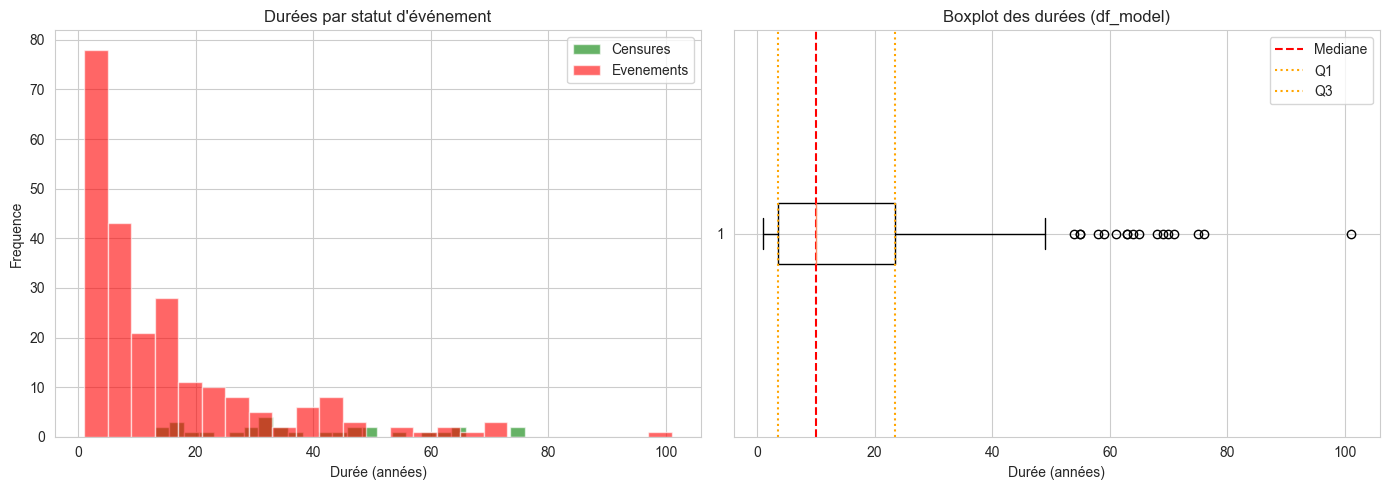

**Interprétation.** La distribution est asymétrique à droite, avec une médiane de 10.00 ans et un intervalle interquartile [3.50, 23.50]. Les censures se concentrent davantage sur les durées longues, ce qui est attendu en présence de partis encore au pouvoir.

> **✅ À retenir :** La forme de la distribution conforte l'usage d'un modèle de survie avec censure à droite.

In [30]:
# ============================================================
# 5.1 Distribution des durees (df_model)
# ============================================================
duration_stats = df_model["duration"].describe(percentiles=[0.25, 0.5, 0.75])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df_model.loc[df_model["event"] == 0, "duration"], bins=25, alpha=0.6, color="green", label="Censures")
axes[0].hist(df_model.loc[df_model["event"] == 1, "duration"], bins=25, alpha=0.6, color="red", label="Evenements")
axes[0].set_xlabel("Durée (années)")
axes[0].set_ylabel("Frequence")
axes[0].set_title("Durées par statut d'événement")
axes[0].legend()

axes[1].boxplot(df_model["duration"], vert=False)
axes[1].axvline(duration_stats["50%"], color="red", linestyle="--", label="Mediane")
axes[1].axvline(duration_stats["25%"], color="orange", linestyle=":", label="Q1")
axes[1].axvline(duration_stats["75%"], color="orange", linestyle=":", label="Q3")
axes[1].set_xlabel("Durée (années)")
axes[1].set_title("Boxplot des durées (df_model)")
axes[1].legend()

plt.tight_layout()
plt.show()

display(
    Markdown(
        f"""**Interprétation.** La distribution est asymétrique à droite, avec une médiane de """
        f"""{duration_stats['50%']:.2f} ans et un intervalle interquartile """
        f"""[{duration_stats['25%']:.2f}, {duration_stats['75%']:.2f}]. """
        "Les censures se concentrent davantage sur les durées longues, ce qui est attendu "
        "en présence de partis encore au pouvoir.\n\n"
        "> **✅ À retenir :** La forme de la distribution conforte l'usage d'un modèle de survie "
        "avec censure à droite."
    )
)

### 5.2 Distribution des covariables du modèle

Nous décrivons la distribution des covariables finales en séparant les binaires et les continues. L'objectif est d'identifier les déséquilibres de classes et les variables éventuellement très concentrées.

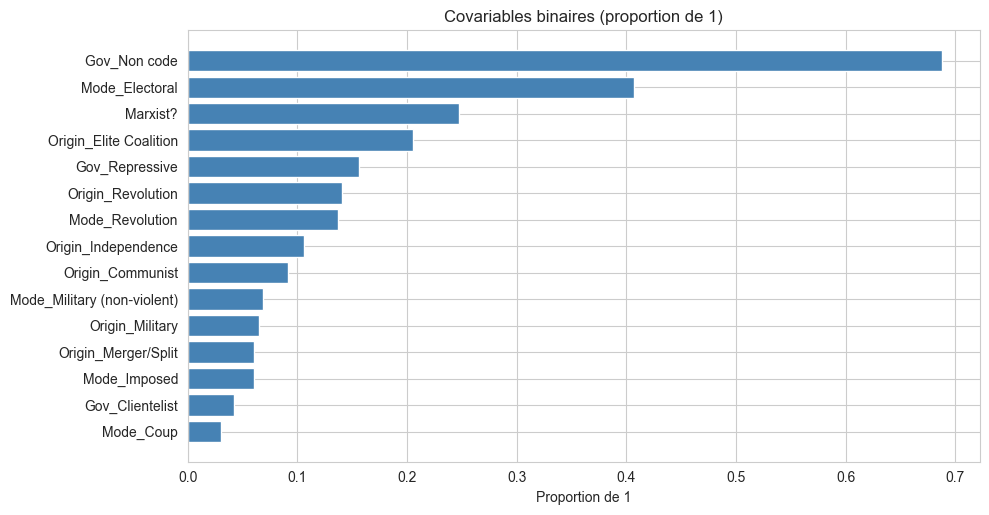

In [31]:
# ============================================================
# 5.2 Distribution des covariables
# ============================================================
covariates = [c for c in df_model.columns if c not in ["duration", "event"]]
binary_covs = [c for c in covariates if df_model[c].nunique() == 2]
cont_covs = [c for c in covariates if df_model[c].nunique() > 2]

if binary_covs:
    prop_ones = df_model[binary_covs].mean().sort_values()
    fig, ax = plt.subplots(figsize=(10, max(4, len(binary_covs) * 0.35)))
    ax.barh(prop_ones.index, prop_ones.values, color="steelblue")
    ax.set_xlabel("Proportion de 1")
    ax.set_title("Covariables binaires (proportion de 1)")
    plt.tight_layout()
    plt.show()

if cont_covs:
    n_show = min(4, len(cont_covs))
    fig, axes = plt.subplots(1, n_show, figsize=(4 * n_show, 3))
    if n_show == 1:
        axes = [axes]
    for ax, col in zip(axes, cont_covs[:n_show]):
        sns.histplot(df_model[col], kde=True, ax=ax, color="steelblue")
        ax.set_title(col)
    plt.tight_layout()
    plt.show()

**Interprétation.** Les covariables binaires montrent des déséquilibres de classes (proportions de 1 variables). Certaines variables (ex. certaines modalités d'`Origin` ou du mode d'accession) peuvent être rares, ce qui peut affecter la précision des estimations du modèle de Cox.

> **📌 Remarque :** Les fortes asymétries invitent à privilégier des interprétations prudentes et à vérifier la robustesse via bootstrap en Section 11.


### 5.3 Taux de censure par sous-groupe

Nous comparons les taux de censure selon `Origin` et selon `Military` pour détecter des déséquilibres potentiels. L'objectif est d'identifier des sous-groupes surreprésentés parmi les censurés.

In [32]:
# ============================================================
# 5.3 Taux de censure par sous-groupe
# ============================================================
df_post = df_clean.loc[df_model.index].copy()

ct_origin = pd.crosstab(df_post["Origin"], df_post["event"], normalize="index")
ct_military = pd.crosstab(df_post["Military"], df_post["event"], normalize="index")

display(ct_origin.rename(columns={0: "Censure", 1: "Evenement"}).round(3))
display(ct_military.rename(columns={0: "Censure", 1: "Evenement"}).round(3))

origin_censor_max = ct_origin[0].max() if 0 in ct_origin.columns else np.nan
origin_censor_min = ct_origin[0].min() if 0 in ct_origin.columns else np.nan

display(
    Markdown(
        f"""**Interprétation.** Les taux de censure par `Origin` varient entre {origin_censor_min:.3f} """
        f"""et {origin_censor_max:.3f}, suggérant des différences de structure entre sous-groupes. """
        "La comparaison par `Military` permet d'identifier si les régimes militaires sont "
        "surreprésentés parmi les censurés.\n\n"
        "> **✅ À retenir :** Des taux de censure très différents entre groupes peuvent affecter "
        "l'interprétation des courbes KM."
    )
)

event,Censure,Evenement
Origin,,
Communist,0.292,0.708
Dictator-Created,0.052,0.948
Dictator-Created/Merger,0.429,0.571
Dictator-Created/Split,0.000,1.000
Elite Coalition,0.019,0.981
Independence,0.143,0.857
Merger,0.000,1.000
Military,0.059,0.941
Revolution,0.243,0.757


event,Censure,Evenement
Military,,
0,0.114,0.886


**Interprétation.** Les taux de censure par `Origin` varient entre 0.000 et 0.429, suggérant des différences de structure entre sous-groupes. La comparaison par `Military` permet d'identifier si les régimes militaires sont surreprésentés parmi les censurés.

> **✅ À retenir :** Des taux de censure très différents entre groupes peuvent affecter l'interprétation des courbes KM.

### 5.4 Matrice de corrélation (covariables finales)

Nous calculons la corrélation de Pearson entre covariables du modèle final. L'objectif est de détecter des paires fortement corrélées, signalant une multicolinéarité potentielle. Pour des binaires, Pearson est équivalent au coefficient $\phi$.

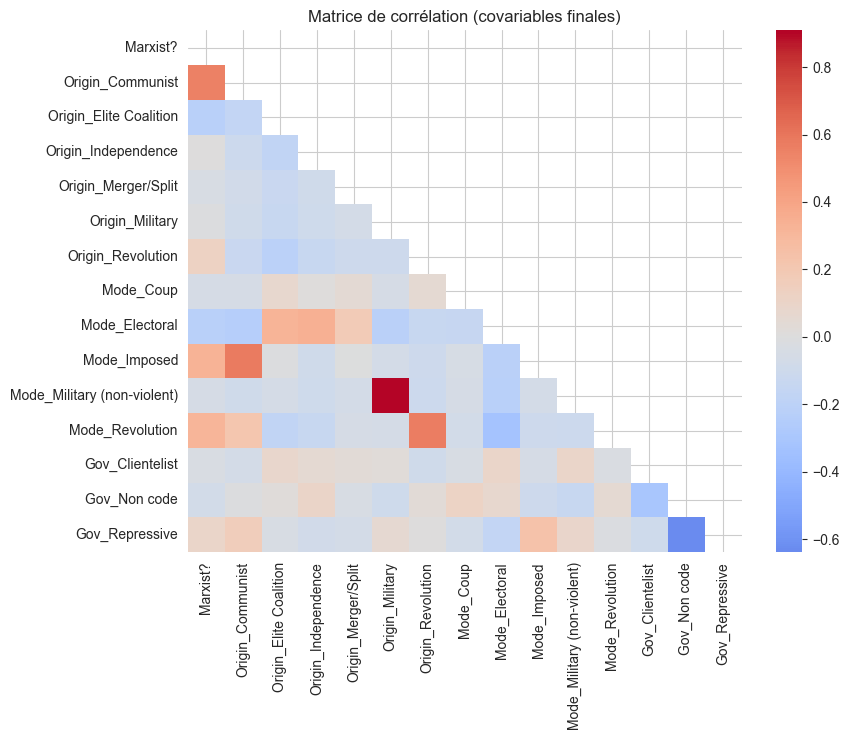

,Var1,Var2,Corr
50,Mode_Military (non-violent),Origin_Military,0.908607
104,Gov_Repressive,Gov_Non code,-0.638481


**Interprétation.** Les paires de variables avec |r| > 0.6 sont listées ci-dessus (2 paires). Ces corrélations élevées signalent une possible multicolinéarité à surveiller lors de l'estimation du modèle.

> **Remarque :** Pour des variables binaires, Pearson est équivalent à $\phi$ et reste interprétable.

### 5.5 Conclusion post-nettoyage

**Bilan :**
- Dataset final : 263 partis, 233 événements, 30 censures.
- Durées asymétriques à droite, médiane 10.00 ans.
- Covariables binaires déséquilibrées mais informatives.
- 2 paires de covariables à corrélation > 0.6 à surveiller.
- Prochaine section : courbes de Kaplan-Meier et tests log-rank.

In [33]:
# ============================================================
# 5.4 Matrice de correlation
# ============================================================
covariates = [c for c in df_model.columns if c not in ["duration", "event"]]
corr_matrix = df_model[covariates].corr()

fig, ax = plt.subplots(figsize=(max(8, len(covariates) * 0.6), max(6, len(covariates) * 0.5)))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Matrice de corrélation (covariables finales)")
plt.tight_layout()
plt.show()

# Bug d'origine : trailing comma -> tuple. Corrige ci-dessous.
corr_pairs = (
    corr_matrix.where(~mask)
    .stack()
    .reset_index()
    .rename(columns={"level_0": "Var1", "level_1": "Var2", 0: "Corr"})
)
corr_pairs = corr_pairs[corr_pairs["Var1"] != corr_pairs["Var2"]]
high_corr = corr_pairs[corr_pairs["Corr"].abs() > CORR_THRESHOLD]
display(high_corr.sort_values("Corr", key=lambda s: s.abs(), ascending=False))

display(
    Markdown(
        f"**Interprétation.** Les paires de variables avec |r| > {CORR_THRESHOLD} sont listées ci-dessus "
        f"({len(high_corr)} paires). Ces corrélations élevées signalent une possible multicolinéarité "
        "à surveiller lors de l'estimation du modèle.\n\n"
        r"> **Remarque :** Pour des variables binaires, Pearson est équivalent à $\phi$ et reste interprétable." "\n\n"
        "### 5.5 Conclusion post-nettoyage\n\n"
        "**Bilan :**\n"
        f"- Dataset final : {n_clean} partis, {n_clean_events} événements, {n_clean_censored} censures.\n"
        f"- Durées asymétriques à droite, médiane {duration_stats['50%']:.2f} ans.\n"
        "- Covariables binaires déséquilibrées mais informatives.\n"
        f"- {len(high_corr)} paires de covariables à corrélation > {CORR_THRESHOLD} à surveiller.\n"
        "- Prochaine section : courbes de Kaplan-Meier et tests log-rank."
    )
)


## 6. Kaplan-Meier + tests log-rank

Dans cette section, nous estimons des courbes de survie non paramétriques et testons l'égalité des courbes entre groupes. L'objectif est de fournir une description initiale robuste avant le modèle de Cox.

### 6.1 Courbe Kaplan-Meier globale

Nous estimons la courbe KM globale sur `df_model` et ajoutons le tableau "At Risk". L'objectif est d'obtenir la médiane de survie et son intervalle de confiance, ainsi que de visualiser la censure.

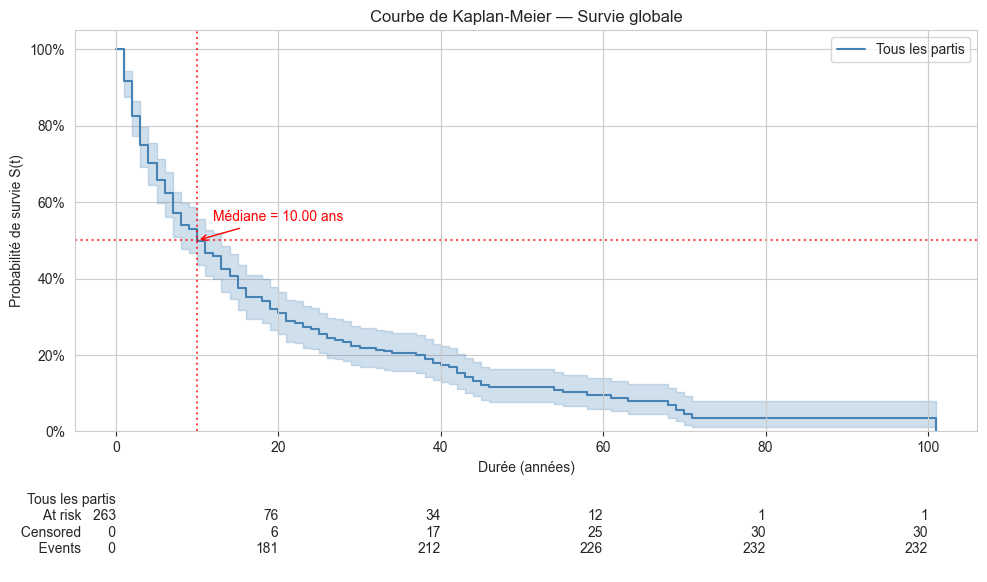

**Interprétation.** La médiane de survie KM est 10.00 ans, avec un IC 95% de S(t) autour de la médiane compris entre 0.436 et 0.557. Le palier de survie strictement positif confirme la présence d'observations censurées.

> **✅ À retenir :** Le tableau "At Risk" visualise la diminution du nombre d'observations sous risque à mesure que le temps augmente.

In [34]:
# ============================================================
# 6.1 Kaplan-Meier global
# ============================================================
kmf = KaplanMeierFitter()
kmf.fit(df_model["duration"], event_observed=df_model["event"], label="Tous les partis")

fig, ax = plt.subplots(figsize=(10, 6))
kmf.plot_survival_function(ax=ax, ci_show=True, color="steelblue")
ax.set_xlabel("Durée (années)")
ax.set_ylabel("Probabilité de survie S(t)")
ax.set_title("Courbe de Kaplan-Meier — Survie globale")
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))

km_median = kmf.median_survival_time_
ax.axhline(0.5, color="red", linestyle=":", alpha=0.7)
ax.axvline(km_median, color="red", linestyle=":", alpha=0.7)
ax.annotate(
    f"Médiane = {km_median:.2f} ans",
    xy=(km_median, 0.5),
    xytext=(km_median + 2, 0.55),
    fontsize=10, color="red",
    arrowprops=dict(arrowstyle="->", color="red"),
)

# Intervalle de confiance au temps le plus proche de la mediane
ci_df = kmf.confidence_interval_
nearest_idx = (ci_df.index.to_series() - km_median).abs().idxmin()
km_ci_low = float(ci_df.loc[nearest_idx].iloc[0])
km_ci_high = float(ci_df.loc[nearest_idx].iloc[1])

add_at_risk_counts(kmf, ax=ax)
plt.tight_layout()
plt.show()

display(
    Markdown(
        f"""**Interprétation.** La médiane de survie KM est {km_median:.2f} ans, """
        f"""avec un IC {CI_PCT}% de S(t) autour de la médiane compris entre {km_ci_low:.3f} """
        f"""et {km_ci_high:.3f}. Le palier de survie strictement positif confirme la présence """
        "d'observations censurées.\n\n"
        "> **✅ À retenir :** Le tableau \"At Risk\" visualise la diminution du nombre "
        "d'observations sous risque à mesure que le temps augmente."
    )
)

### 6.2 Courbes KM stratifiées par Origin + test log-rank

Nous comparons les courbes de survie entre catégories de `Origin` (variable théorique clé). L'objectif est de tester si les fonctions de survie diffèrent significativement selon l'origine du parti.

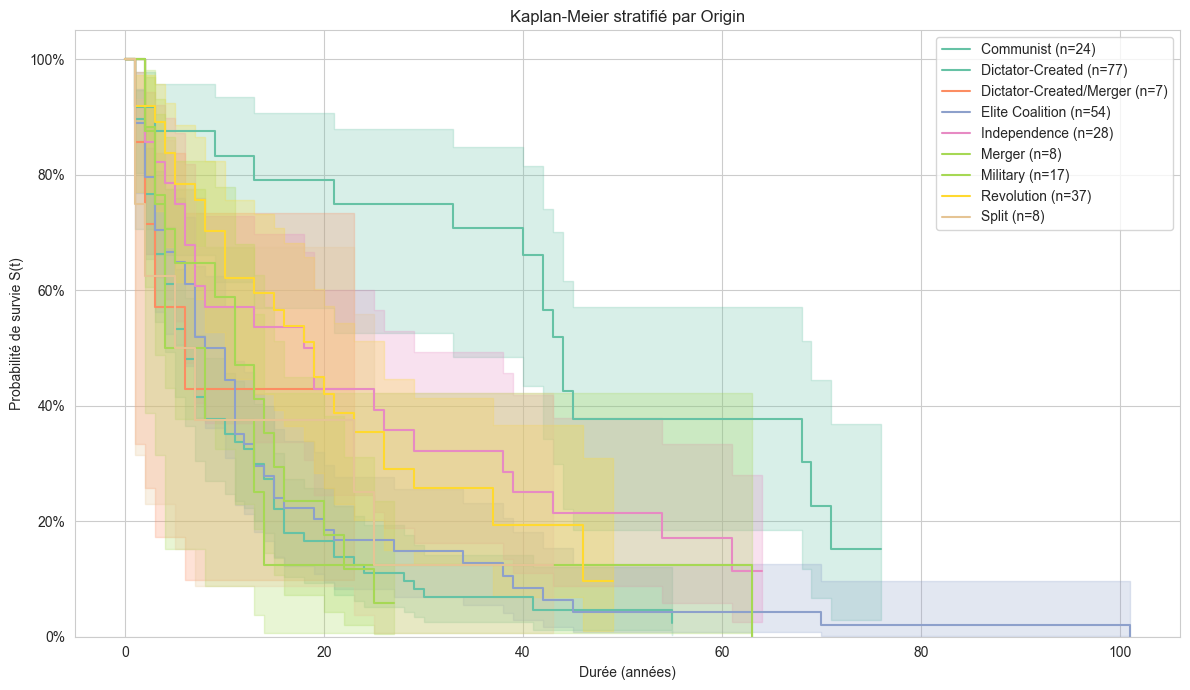

Log-rank: chi2=42.1211, p=0.0000


**Hypothèses (log-rank).**
- $H_0$ : les fonctions de survie des groupes sont identiques.
- $H_1$ : au moins un groupe a une survie différente.
- Statistique : $\chi^2$ avec $k-1$ degrés de liberté, ici $k=9$.
- Règle : on rejette $H_0$ si p-value < $\alpha = 0.05$.

**Interprétation.** Le groupe avec la survie médiane la plus longue est **Communist** (44.0 ans), le plus court est **Dictator-Created** (6.0 ans).

Le test log-rank donne $\chi^2_{logrank_df} = 42.1211$, p = 0.0000. On **rejette** $H_0$ : les courbes de survie diffèrent significativement selon Origin.

**Bilan :**
- Courbes KM stratifiées par Origin estimées.
- Test log-rank multivarié appliqué.
- Prochaine section : hypothèse de censure non informative.

In [35]:
# ============================================================
# 6.2 Kaplan-Meier stratifie par Origin
# ============================================================
df_post = df_clean.loc[df_model.index].copy()
if "Origin" not in df_post.columns:
    raise KeyError("Colonne 'Origin' absente pour la stratification.")

origin_counts = df_post["Origin"].value_counts()
valid_origins = origin_counts[origin_counts >= RARE_THRESHOLD].index.tolist()
df_post_valid = df_post[df_post["Origin"].isin(valid_origins)].copy()

group_medians = {}
fig, ax = plt.subplots(figsize=(12, 7))
colors = plt.cm.Set2(np.linspace(0, 0.8, max(1, len(valid_origins))))

for i, grp in enumerate(sorted(valid_origins)):
    idx = df_post_valid[df_post_valid["Origin"] == grp].index
    T = df_model.loc[idx, "duration"]
    E = df_model.loc[idx, "event"]
    kmf_g = KaplanMeierFitter()
    kmf_g.fit(T, event_observed=E, label=f"{grp} (n={len(T)})")
    kmf_g.plot_survival_function(ax=ax, ci_show=True, color=colors[i])
    group_medians[grp] = kmf_g.median_survival_time_

ax.set_xlabel("Durée (années)")
ax.set_ylabel("Probabilité de survie S(t)")
ax.set_title("Kaplan-Meier stratifié par Origin")
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

# Test log-rank (multigroup)
if len(valid_origins) >= 2:
    all_T = df_model.loc[df_post_valid.index, "duration"]
    all_E = df_model.loc[df_post_valid.index, "event"]
    all_G = df_post_valid.loc[df_post_valid.index, "Origin"]
    logrank_res = multivariate_logrank_test(all_T, all_G, event_observed=all_E)
    logrank_p = float(logrank_res.p_value)
    logrank_stat = float(logrank_res.test_statistic)
    logrank_df = len(valid_origins) - 1
    print(f"Log-rank: chi2={logrank_stat:.4f}, p={logrank_p:.4f}")
else:
    logrank_p = np.nan
    logrank_stat = np.nan
    logrank_df = 0
    print("Log-rank non calcule (moins de deux groupes valides).")

longest_group = max(group_medians, key=group_medians.get) if group_medians else None
shortest_group = min(group_medians, key=group_medians.get) if group_medians else None
if group_medians:
    longest_group_label = longest_group
    longest_median_value = group_medians[longest_group]
    shortest_group_label = shortest_group
    shortest_median_value = group_medians[shortest_group]
else:
    longest_group_label = "NA"
    longest_median_value = np.nan
    shortest_group_label = "NA"
    shortest_median_value = np.nan

display(
    Markdown(
        "**Hypothèses (log-rank).**\n"
        "- $H_0$ : les fonctions de survie des groupes sont identiques.\n"
        "- $H_1$ : au moins un groupe a une survie différente.\n"
        f"- Statistique : $\\chi^2$ avec $k-1$ degrés de liberté, ici $k={len(valid_origins)}$.\n"
        f"- Règle : on rejette $H_0$ si p-value < $\\alpha = {ALPHA}$.\n\n"
        f"**Interprétation.** Le groupe avec la survie médiane la plus longue est "
        f"**{longest_group_label}** ({longest_median_value:.1f} ans), "
        f"le plus court est **{shortest_group_label}** ({shortest_median_value:.1f} ans).\n\n"
        f"Le test log-rank donne $\\chi^2_{{logrank_df}} = {logrank_stat:.4f}$, p = {logrank_p:.4f}. "
        f"{'On **rejette** $H_0$ : les courbes de survie diffèrent significativement selon Origin.' if logrank_p < ALPHA else 'On ne rejette pas $H_0$ au seuil retenu.'}\n\n"
        "**Bilan :**\n"
        "- Courbes KM stratifiées par Origin estimées.\n"
        "- Test log-rank multivarié appliqué.\n"
        "- Prochaine section : hypothèse de censure non informative."
    )
)

### 6.3 Hypothèse de censure non informative

L'estimateur de Kaplan-Meier suppose que la censure est **non informative**, c'est-à-dire que les partis censurés n'ont pas un risque structurellement différent de ceux observés. Cette hypothèse ne peut pas être testée formellement ici mais est discutée en Section Limites.

**Bilan :**
- Courbe KM globale estimée avec médiane et tableau "At Risk".
- Différences entre origines testées via log-rank.
- Hypothèse de censure non informative explicitée.
- Prochaine section : estimation du modèle de Cox.

## 7. Modèle de Cox — Estimation

### 7.1 Hypothèses et log-vraisemblance partielle

Avant l'estimation, nous rappelons les hypothèses du modèle de Cox et sa formulation mathématique.

#### Hypothèses
- **Indépendance** des observations (spells indépendants). Dans nos données, plusieurs spells appartiennent au même pays et ne sont pas indépendants : les erreurs standards sont donc **groupées par pays** (voir ci-dessous).
- **Censure non informative** : le mécanisme de censure est indépendant de l'événement.
- **Risques proportionnels** :
$$h_i(t) = h_0(t) \exp\left(\boldsymbol{\beta}^\top \mathbf{X}_i\right)$$
où $h_0(t)$ est le *hazard de base* non spécifié et $\boldsymbol{\beta}$ le vecteur des coefficients.

#### Log-vraisemblance partielle de Cox (1972)

L'astuce de Cox consiste à éliminer $h_0(t)$ par conditionnement sur les temps d'événements ordonnés $t_{(1)} < t_{(2)} < \cdots < t_{(D)}$. La **log-vraisemblance partielle** est :

$$\ell_P(\boldsymbol{\beta}) = \sum_{i:\, \delta_i = 1} \left[ \boldsymbol{\beta}^\top \mathbf{X}_i - \log \sum_{j \in \mathcal{R}(t_i)} \exp\!\left(\boldsymbol{\beta}^\top \mathbf{X}_j\right) \right]$$

où :
- $\delta_i = 1$ si le parti $i$ a connu l'événement (dissolution), 0 sinon (censuré) ;
- $\mathcal{R}(t_i) = \{j : T_j \geq t_i\}$ est l'**ensemble à risque** au temps $t_i$ ;
- La somme intérieure porte sur tous les partis encore en observation au moment $t_i$.

L'estimateur $\hat{\boldsymbol{\beta}}$ est obtenu en maximisant $\ell_P$ par **Newton-Raphson** (`lifelines.CoxPHFitter`). Les intervalles de confiance à 95 % sont construits à partir de la matrice d'information de Fisher observée :

$$\widehat{\mathrm{Var}}(\hat{\beta}_j) = \left[-\frac{\partial^2 \ell_P}{\partial \beta_j^2}\right]^{-1}$$

#### Erreurs standards robustes groupées par pays

Cette variance suppose des spells indépendants. Comme un même pays connaît souvent plusieurs spells, nous utilisons l'**estimateur sandwich robuste** de Lin & Wei (1989), groupé par pays (`cluster_col="Country"`) :

$$\widehat{\mathrm{Var}}_{\text{robuste}}(\hat{\boldsymbol{\beta}}) = \mathcal{I}^{-1} \Big(\sum_{g} \mathbf{U}_g \mathbf{U}_g^\top\Big) \mathcal{I}^{-1},$$

où $\mathcal{I}$ est la matrice d'information et $\mathbf{U}_g$ la somme des résidus de score des spells du pays $g$. Les **coefficients ne changent pas** ; seuls les erreurs standards, les intervalles de confiance et les p-values tiennent compte de la dépendance entre spells d'un même pays. Le pays est une variable de regroupement, jamais une covariable.

#### Gestion des ex-aequo (*ties*)

Par défaut, `lifelines` utilise l'**approximation de Breslow (1974)** pour les observations ayant la même durée :

$$\ell_P^{\text{Breslow}}(\boldsymbol{\beta}) = \sum_{k=1}^{D} \left[ \boldsymbol{\beta}^\top \mathbf{s}_k - d_k \log \sum_{j \in \mathcal{R}(t_k)} \exp\!\left(\boldsymbol{\beta}^\top \mathbf{X}_j\right) \right]$$

où $\mathbf{s}_k = \sum_{i:\,t_i = t_k,\, \delta_i=1} \mathbf{X}_i$ est la somme des covariables des cas liés au temps $t_k$ et $d_k$ le nombre de ces cas.

> **📌 Remarque :** L'approximation de Breslow est légèrement biaisée quand les ties sont nombreux. Avec des données politiques annuelles (ex. plusieurs partis dissous la même année), ce biais reste acceptable.


In [36]:
# ============================================================
# 7.2 Selection du penaliseur (validation croisee) et estimation
# ============================================================
cox_data = df_model[["duration", "event"] + covariates].copy()
ties_count = int(df_model["duration"].duplicated().sum())
print(f"Nombre de ties (durées identiques) : {ties_count}")

N_FOLDS = 5


def cv_c_index(data, penalizer, k=N_FOLDS, seed=RANDOM_STATE):
    """C-index hors échantillon par validation croisée à k plis : (moyenne, écart-type entre plis)."""
    data = data.reset_index(drop=True)
    folds = np.random.RandomState(seed).permutation(len(data)) % k
    covs = [c for c in data.columns if c not in ("duration", "event")]
    scores = []
    for f in range(k):
        train, test = data[folds != f], data[folds == f]
        keep = [c for c in covs if train[c].var() > 0]
        if not keep:
            scores.append(0.5)
            continue
        model = CoxPHFitter(penalizer=penalizer).fit(train[["duration", "event"] + keep], "duration", "event")
        risk = model.predict_partial_hazard(test[keep])
        scores.append(concordance_index(test["duration"], -risk, test["event"]))
    return float(np.mean(scores)), float(np.std(scores, ddof=1))


results_pen = []
for pen in [0, 0.001, 0.01, 0.1, 1.0]:
    try:
        cph_tmp = CoxPHFitter(penalizer=pen)
        cph_tmp.fit(cox_data, duration_col="duration", event_col="event")
        cv_mean, cv_sd = cv_c_index(cox_data, pen)
        results_pen.append({
            "penalizer": pen,
            "c_index_estimation": cph_tmp.concordance_index_,
            "c_index_cv": cv_mean,
            "c_index_cv_sd": cv_sd,
            "converged": True,
        })
    except Exception:
        results_pen.append({"penalizer": pen, "c_index_estimation": None, "c_index_cv": None,
                            "c_index_cv_sd": None, "converged": False})

results_pen_df = pd.DataFrame(results_pen)
display(results_pen_df)

converged = results_pen_df[results_pen_df["converged"]]
best_row = converged.sort_values("c_index_cv", ascending=False).iloc[0]
penalizer_cv = float(best_row["penalizer"])          # meilleur penaliseur en prediction (Section 10.5)
cv_gain = float(best_row["c_index_cv"] - converged["c_index_cv"].min())
cv_sd_mean = float(converged["c_index_cv_sd"].mean())
print(f"Meilleur pénaliseur en validation croisée : {penalizer_cv} "
      f"(gain de C-index {cv_gain:.3f}, écart-type entre plis {cv_sd_mean:.3f})")

# Modele principal (inference) : penalisation legere et fixe, pour la seule stabilite numerique.
# Une forte penalisation ridge biaise les HR vers 1 et rend les p-values et IC non valides ;
# elle n'est justifiee que si elle ameliore nettement la prediction, ce que la validation croisee
# ne montre pas ici. Le modele fortement penalise est presente en Section 10.5.
PENALIZER_MAIN = 0.01
penalizer_used = PENALIZER_MAIN
cv_c_index_main = cv_c_index(cox_data, penalizer_used)[0]
print(f"Pénaliseur du modèle principal : {penalizer_used}")

# Erreurs standards robustes groupées par pays (plusieurs spells d'un même pays ne sont pas indépendants).
# Country est une colonne de regroupement, jamais une covariable : cox_data (covariables, validation croisée,
# VIF) reste sans Country ; cox_data_cl ne sert qu'aux estimations groupées et à leurs diagnostics.
country_of_spell = df_clean.loc[df_model.index, "Country"]
cox_data_cl = cox_data.assign(Country=country_of_spell.values)
cph = CoxPHFitter(penalizer=penalizer_used)
cph.fit(cox_data_cl, duration_col="duration", event_col="event", cluster_col="Country")
# Même modèle avec la variance classique (spells supposés indépendants) : les coefficients doivent être identiques
cph_model_based = CoxPHFitter(penalizer=penalizer_used).fit(cox_data, duration_col="duration", event_col="event")
assert np.allclose(cph.params_, cph_model_based.params_), "le regroupement par pays ne doit pas modifier les coefficients"
print(f"Erreurs standards groupées sur {country_of_spell.nunique()} pays.")
print(f"C-index sur les données d'estimation : {cph.concordance_index_:.4f}")
print(f"C-index en validation croisée ({N_FOLDS} plis) : {cv_c_index_main:.4f}")

display(
    Markdown(
        f"""**Interprétation.** La grille de pénalisation est évaluée par **validation croisée à {N_FOLDS} plis** : chaque pli """
        f"""est prédit par un modèle estimé sur les autres, ce qui mesure la discrimination sur des partis non vus """
        f"""(le C-index calculé sur les données d'estimation est optimiste). Le meilleur pénaliseur en prédiction est """
        f"""{penalizer_cv}, mais son gain de C-index ({cv_gain:.3f}) est inférieur à l'écart-type entre plis """
        f"""({cv_sd_mean:.3f}) : la pénalisation n'améliore pas nettement la prédiction. """
        f"""Le modèle principal, utilisé pour l'inférence, garde donc une pénalisation légère et fixe ({penalizer_used}), """
        "pour la seule stabilité numérique : une forte pénalisation ridge (L2) biaise les hazard ratios vers 1 et rend les "
        "p-values non valides. Le modèle fortement pénalisé est présenté comme comparaison en Section 10.5. "
        f"C-index du modèle principal : {cv_c_index_main:.4f} en validation croisée, {cph.concordance_index_:.4f} sur les "
        "données d'estimation.\n\n"
        f"> **✅ À retenir :** Les ties ({ties_count}) justifient l'usage de l'approximation de Breslow "
        "pour l'estimation de la vraisemblance partielle.\n\n"
        "**Bilan :**\n"
        "- Hypothèses du Cox explicitées et ties documentés.\n"
        "- Grille de pénalisation évaluée par validation croisée ; pénalisation légère retenue pour l'inférence.\n"
        "- Modèle de Cox estimé avec pénalisation ridge.\n"
        "- Prochaine section : interprétation des coefficients et forest plot."
    )
)


Nombre de ties (durées identiques) : 200


,penalizer,c_index_estimation,c_index_cv,c_index_cv_sd,converged
0,0.000,0.641296,0.587666,0.045019,True
1,0.001,0.641358,0.586733,0.045880,True
2,0.010,0.641452,0.587305,0.045892,True
3,0.100,0.644231,0.588386,0.054066,True
4,1.000,0.639593,0.599687,0.054588,True


Meilleur pénaliseur en validation croisée : 1.0 (gain de C-index 0.013, écart-type entre plis 0.049)


Pénaliseur du modèle principal : 0.01
Erreurs standards groupées sur 131 pays.
C-index sur les données d'estimation : 0.6415
C-index en validation croisée (5 plis) : 0.5873


**Interprétation.** La grille de pénalisation est évaluée par **validation croisée à 5 plis** : chaque pli est prédit par un modèle estimé sur les autres, ce qui mesure la discrimination sur des partis non vus (le C-index calculé sur les données d'estimation est optimiste). Le meilleur pénaliseur en prédiction est 1.0, mais son gain de C-index (0.013) est inférieur à l'écart-type entre plis (0.049) : la pénalisation n'améliore pas nettement la prédiction. Le modèle principal, utilisé pour l'inférence, garde donc une pénalisation légère et fixe (0.01), pour la seule stabilité numérique : une forte pénalisation ridge (L2) biaise les hazard ratios vers 1 et rend les p-values non valides. Le modèle fortement pénalisé est présenté comme comparaison en Section 10.5. C-index du modèle principal : 0.5873 en validation croisée, 0.6415 sur les données d'estimation.

> **✅ À retenir :** Les ties (200) justifient l'usage de l'approximation de Breslow pour l'estimation de la vraisemblance partielle.

**Bilan :**
- Hypothèses du Cox explicitées et ties documentés.
- Grille de pénalisation évaluée par validation croisée ; pénalisation légère retenue pour l'inférence.
- Modèle de Cox estimé avec pénalisation ridge.
- Prochaine section : interprétation des coefficients et forest plot.

## 8. Modèle de Cox — résultats

Dans cette section, nous présentons les coefficients estimés, leurs intervalles de confiance et un forest plot des hazard ratios. L'objectif est d'interpréter les effets significatifs et de relier ces effets aux hypothèses de recherche.

### 8.1 Tableau des coefficients et tests globaux

Nous affichons le résumé du modèle de Cox (coefficients non transformés) ainsi que les tests globaux (LR, Score, Wald). L'objectif est d'identifier les variables significatives (p faibles).

In [37]:
# ============================================================
# 8.1 Resume du modele
# ============================================================
print("=" * 70)
print("RÉSULTATS DU MODÈLE DE COX")
print("=" * 70)
cph.print_summary(decimals=4, model="untransformed coefficients", style="ascii")

summary = cph.summary.copy()
lr_test = cph.log_likelihood_ratio_test()
lr_stat = float(lr_test.test_statistic)
lr_p = float(lr_test.p_value)

print("\n--- Métriques globales ---")
print(f"C-index : {cph.concordance_index_:.4f}")
print(f"Log-vraisemblance partielle : {cph.log_likelihood_:.4f}")
print(f"LR test: chi2 = {lr_stat:.4f}, p = {lr_p:.4f}")

display(
    Markdown(
        f"""**Interprétation.** Le LR test global donne $\\chi^2 = {lr_stat:.4f}$ (p = {lr_p:.4f}), """
        "ce qui indique si le modèle apporte un gain d'explication par rapport au modèle nul. "
        "Les tests de Score et Wald globaux sont reportés dans `print_summary()` et doivent être "
        "interprétés à partir des p-values associées.\n\n"
        f"> **✅ À retenir :** Les variables individuelles sont significatives si p < $\\alpha = {ALPHA}$ "
        "(voir tableau des coefficients)."
    )
)

# ------------------------------------------------------------
# Effet du regroupement par pays sur l'inférence (mêmes coefficients)
# ------------------------------------------------------------
def ci_text(s):
    return s["exp(coef) lower 95%"].map("{:.3f}".format) + " – " + s["exp(coef) upper 95%"].map("{:.3f}".format)


s_mb, s_cl = cph_model_based.summary, cph.summary
cluster_table = pd.DataFrame({
    "HR": s_cl["exp(coef)"].round(3),
    "p (variance classique)": s_mb["p"].round(4),
    "IC 95 % (classique)": ci_text(s_mb),
    "p (groupée par pays)": s_cl["p"].round(4),
    "IC 95 % (groupé)": ci_text(s_cl),
})
cluster_table["significativité modifiée"] = (s_mb["p"] < ALPHA) != (s_cl["p"] < ALPHA)
display(cluster_table)
became_sig = cluster_table.index[(s_mb["p"] >= ALPHA) & (s_cl["p"] < ALPHA)].tolist()
lost_sig = cluster_table.index[(s_mb["p"] < ALPHA) & (s_cl["p"] >= ALPHA)].tolist()
se_ratio = (s_cl["se(coef)"] / s_mb["se(coef)"])
display(Markdown(
    f"**Erreurs standards groupées par pays.** Les {len(cluster_table)} coefficients sont identiques ; les erreurs "
    f"standards groupées valent en moyenne {se_ratio.mean():.2f} fois les erreurs standards classiques (de "
    f"{se_ratio.min():.2f} à {se_ratio.max():.2f}). "
    + (f"Deviennent significatifs au seuil {ALPHA} : {', '.join(f'`{v}`' for v in became_sig)}. " if became_sig else "")
    + (f"Ne sont plus significatifs : {', '.join(f'`{v}`' for v in lost_sig)}. " if lost_sig else "")
    + ("" if became_sig or lost_sig else f"Aucune significativité n'est modifiée au seuil {ALPHA}. ")
    + ("Des erreurs groupées plus petites que les erreurs classiques indiquent que les résidus de score des spells "
       "d'un même pays tendent à se compenser." if se_ratio.mean() < 1 else
       "Des erreurs groupées plus grandes indiquent une corrélation positive entre spells d'un même pays.")
))

RÉSULTATS DU MODÈLE DE COX
<lifelines.CoxPHFitter: fitted with 263 total observations, 30 right-censored observations>
             duration col = 'duration'
                event col = 'event'
              cluster col = 'Country'
                penalizer = 0.01
                 l1 ratio = 0.0
          robust variance = True
      baseline estimation = breslow
   number of observations = 263
number of events observed = 233
   partial log-likelihood = -1073.5271
         time fit was run = 2026-10-24 10:21:33 UTC
                    model = untransformed coefficients

---
                               coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                      
Marxist?                    -0.2483    0.7801    0.1661         -0.5738          0.0772              0.5634              1.0803
Origin_Communist            -1.0898


--- Métriques globales ---
C-index : 0.6415
Log-vraisemblance partielle : -1073.5271
LR test: chi2 = 61.4128, p = 0.0000


**Interprétation.** Le LR test global donne $\chi^2 = 61.4128$ (p = 0.0000), ce qui indique si le modèle apporte un gain d'explication par rapport au modèle nul. Les tests de Score et Wald globaux sont reportés dans `print_summary()` et doivent être interprétés à partir des p-values associées.

> **✅ À retenir :** Les variables individuelles sont significatives si p < $\alpha = 0.05$ (voir tableau des coefficients).

,HR,p (variance classique),IC 95 % (classique),p (groupée par pays),IC 95 % (groupé),significativité modifiée
covariate,,,,,,
Marxist?,0.780,0.2133,0.528 – 1.153,0.1349,0.563 – 1.080,False
Origin_Communist,0.336,0.0077,0.151 – 0.750,0.0059,0.155 – 0.730,False
Origin_Elite Coalition,0.777,0.2548,0.504 – 1.199,0.2573,0.503 – 1.202,False
Origin_Independence,0.479,0.0060,0.284 – 0.810,0.0088,0.277 – 0.831,False
Origin_Merger/Split,0.811,0.5129,0.434 – 1.517,0.5815,0.386 – 1.705,False
Origin_Military,0.484,0.2615,0.137 – 1.717,0.0203,0.263 – 0.893,True
Origin_Revolution,0.705,0.2319,0.397 – 1.251,0.1775,0.424 – 1.172,False
Mode_Coup,0.967,0.9302,0.456 – 2.052,0.9303,0.455 – 2.054,False
Mode_Electoral,1.158,0.4710,0.777 – 1.728,0.4596,0.785 – 1.710,False


**Erreurs standards groupées par pays.** Les 15 coefficients sont identiques ; les erreurs standards groupées valent en moyenne 0.87 fois les erreurs standards classiques (de 0.47 à 1.19). Deviennent significatifs au seuil 0.05 : `Origin_Military`, `Mode_Military (non-violent)`. Des erreurs groupées plus petites que les erreurs classiques indiquent que les résidus de score des spells d'un même pays tendent à se compenser.

### 8.1b Variables militaires : effet combiné

L'origine militaire (`Origin_Military`) et l'accession militaire non violente (`Mode_Military (non-violent)`) décrivent presque les mêmes partis : un parti fondé par des militaires a le plus souvent pris le pouvoir par l'armée. Leurs coefficients séparés ne sont alors estimés qu'à partir des quelques partis qui diffèrent sur les deux variables, et peuvent se compenser (un effet fortement protecteur et un effet fortement aggravant). Ce qui reste estimable est l'**effet combiné** pour un parti qui a les deux caractéristiques : $HR = e^{\beta_1 + \beta_2}$, dont la variance est $\mathrm{Var}(\hat\beta_1) + \mathrm{Var}(\hat\beta_2) + 2\,\mathrm{Cov}(\hat\beta_1, \hat\beta_2)$. Nous calculons aussi le test de Wald joint ($\beta_1 = \beta_2 = 0$), avec la variance groupée par pays et avec la variance classique.

**Règle, fixée avant les résultats :** si moins de 10 partis diffèrent sur les deux variables, leurs coefficients séparés ne sont pas interprétés, et seul l'effet combiné « origine et accession militaires » est rapporté dans les sections 13 à 15. La spécification du modèle n'est pas modifiée (le test du rapport de vraisemblance de la Section 10.3b en dépend).

In [38]:
# ============================================================
# 8.1b Variables militaires : effet combiné
# ============================================================
from lifelines import utils as lifelines_utils

MILITARY_PAIR = ["Origin_Military", "Mode_Military (non-violent)"]
MIN_DISCORDANT = 10


def clustered_covariance(model, df):
    """Matrice de variance robuste groupée par pays, recalculée comme dans CoxPHFitter.fit (lifelines).
    lifelines n'expose que les erreurs standards robustes ; l'égalité avec celles-ci est vérifiée ci-dessous."""
    X, T, E, weights, _, _, _ = model._preprocess_dataframe(df)
    X_norm = pd.DataFrame(lifelines_utils.normalize(X.values, model._norm_mean.values, model._norm_std.values),
                          index=X.index, columns=X.columns)
    V = model._compute_sandwich_estimator(X_norm, T, E, weights)
    return pd.DataFrame(V, index=model.params_.index, columns=model.params_.index)


V_clustered = clustered_covariance(cph, cox_data_cl)
assert np.allclose(np.sqrt(np.diag(V_clustered.values)), cph.standard_errors_.values), \
    "la matrice groupée recalculée ne reproduit pas les erreurs standards de lifelines"

military_table = pd.crosstab(cox_data[MILITARY_PAIR[0]], cox_data[MILITARY_PAIR[1]])
n_military_origin = int(cox_data[MILITARY_PAIR[0]].sum())
n_military_both = int((cox_data[MILITARY_PAIR[0]].eq(1) & cox_data[MILITARY_PAIR[1]].eq(1)).sum())
n_discordant = int((cox_data[MILITARY_PAIR[0]] != cox_data[MILITARY_PAIR[1]]).sum())
n_discordant_events = int(cox_data.loc[cox_data[MILITARY_PAIR[0]] != cox_data[MILITARY_PAIR[1]], "event"].sum())
MILITARY_COMBINED = n_discordant < MIN_DISCORDANT
display(military_table)


def combined_effect(V):
    b = cph.params_[MILITARY_PAIR].values
    Vab = V.loc[MILITARY_PAIR, MILITARY_PAIR].values
    s = b.sum()
    se = np.sqrt(Vab[0, 0] + Vab[1, 1] + 2 * Vab[0, 1])
    wald = float(b @ np.linalg.solve(Vab, b))
    return {"HR combiné": np.exp(s), "IC bas": np.exp(s - 1.96 * se), "IC haut": np.exp(s + 1.96 * se),
            "p (β1 + β2 = 0)": 2 * stats.norm.sf(abs(s / se)), "Wald joint χ²(2)": wald,
            "p (β1 = β2 = 0)": stats.chi2.sf(wald, 2),
            "corrélation(β1, β2)": Vab[0, 1] / np.sqrt(Vab[0, 0] * Vab[1, 1])}


military_effects = pd.DataFrame({"variance groupée par pays": combined_effect(V_clustered),
                                 "variance classique": combined_effect(cph_model_based.variance_matrix_)}).T
display(military_effects.round(4))
mil = military_effects.loc["variance groupée par pays"]
mil_classic = military_effects.loc["variance classique"]
hr_separate = {v: cph.summary.loc[v, "exp(coef)"] for v in MILITARY_PAIR}

display(Markdown(
    f"**Diagnostic.** Sur les {n_military_origin} partis d'origine militaire, {n_military_both} ont aussi accédé au "
    f"pouvoir par une prise de pouvoir militaire non violente ; seuls {n_discordant} partis diffèrent sur les deux "
    f"variables ({n_discordant_events} chute(s)). Les coefficients séparés (HR = {hr_separate[MILITARY_PAIR[0]]:.2f} "
    f"et {hr_separate[MILITARY_PAIR[1]]:.2f}) sont fortement corrélés négativement "
    f"({mil['corrélation(β1, β2)']:.2f}) et se compensent : l'effet combiné vaut HR = {mil['HR combiné']:.2f} "
    f"[IC 95 % {mil['IC bas']:.2f} – {mil['IC haut']:.2f}], p = {mil['p (β1 + β2 = 0)']:.3f} avec la variance "
    f"groupée (p = {mil_classic['p (β1 + β2 = 0)']:.3f} avec la variance classique). Le test de Wald joint donne "
    f"p = {mil['p (β1 = β2 = 0)']:.3f} avec la variance groupée et p = {mil_classic['p (β1 = β2 = 0)']:.3f} avec la "
    "variance classique"
    + (" : les deux variances divergent, car la variance groupée repose ici sur une poignée de partis répartis dans "
       "autant de pays, ce qui la rend peu fiable." if (mil["p (β1 = β2 = 0)"] < ALPHA) != (mil_classic["p (β1 = β2 = 0)"] < ALPHA)
       else ".")
    + (f"\n\n**Règle appliquée** ({n_discordant} < {MIN_DISCORDANT}) : seuls l'effet combiné et sa p-value sont "
       "rapportés dans les sections 13 à 15." if MILITARY_COMBINED else
       f"\n\n**Règle non appliquée** ({n_discordant} ≥ {MIN_DISCORDANT}) : les coefficients séparés restent interprétés.")
))


Mode_Military (non-violent),0.0,1.0
Origin_Military,,
0.0,244,2
1.0,1,16


,HR combiné,IC bas,IC haut,p (β1 + β2 = 0),Wald joint χ²(2),p (β1 = β2 = 0),"corrélation(β1, β2)"
variance groupée par pays,1.137,0.8283,1.5607,0.4269,8.5058,0.0142,-0.8597
variance classique,1.137,0.6549,1.9739,0.6482,1.9516,0.3769,-0.9021


**Diagnostic.** Sur les 17 partis d'origine militaire, 16 ont aussi accédé au pouvoir par une prise de pouvoir militaire non violente ; seuls 3 partis diffèrent sur les deux variables (2 chute(s)). Les coefficients séparés (HR = 0.48 et 2.35) sont fortement corrélés négativement (-0.86) et se compensent : l'effet combiné vaut HR = 1.14 [IC 95 % 0.83 – 1.56], p = 0.427 avec la variance groupée (p = 0.648 avec la variance classique). Le test de Wald joint donne p = 0.014 avec la variance groupée et p = 0.377 avec la variance classique : les deux variances divergent, car la variance groupée repose ici sur une poignée de partis répartis dans autant de pays, ce qui la rend peu fiable.

**Règle appliquée** (3 < 10) : seuls l'effet combiné et sa p-value sont rapportés dans les sections 13 à 15.

### 8.2 Forest plot des hazard ratios

Nous visualisons les hazard ratios (HR) sur une échelle logarithmique avec leurs intervalles de confiance. L'objectif est d'identifier rapidement les effets protecteurs (HR en dessous du niveau neutre) et de risque (HR au-dessus).

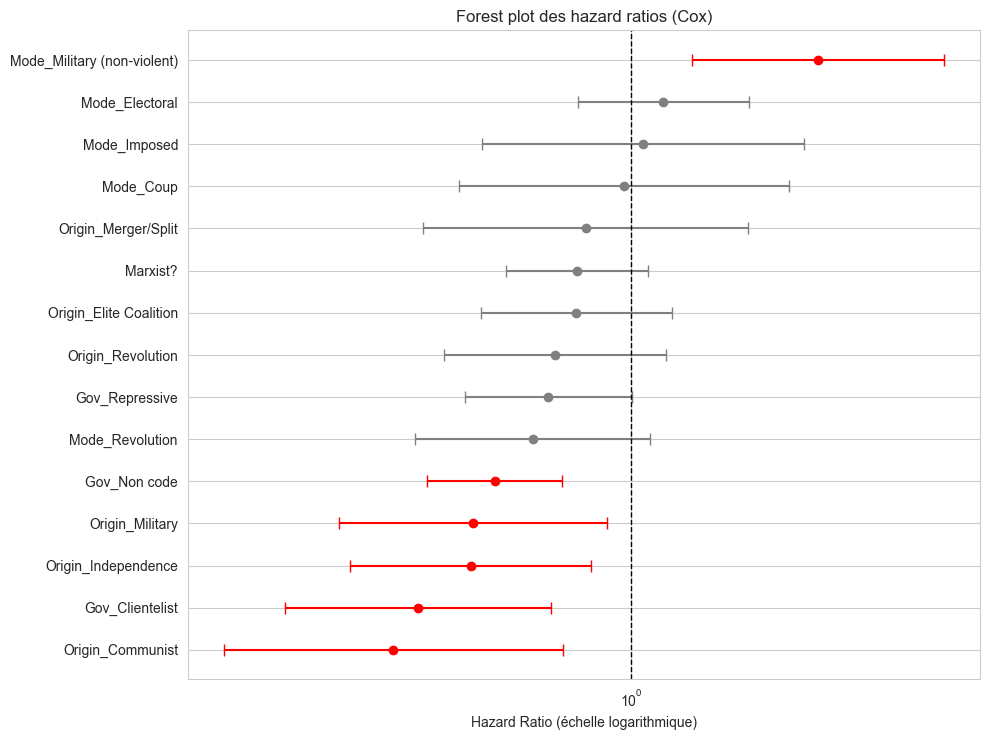

**Interprétation.** Les variables significatives (p < $\alpha = 0.05$) sont ['Origin_Communist', 'Gov_Clientelist', 'Origin_Independence', 'Origin_Military', 'Gov_Non code', 'Mode_Military (non-violent)']. Le détail des HR et IC est :
- **Origin_Communist** : HR = 0.336 [IC 95% 0.155, 0.730], p = 0.0059, effet = -66.4% sur le risque
- **Gov_Clientelist** : HR = 0.376 [IC 95% 0.205, 0.691], p = 0.0016, effet = -62.4% sur le risque
- **Origin_Independence** : HR = 0.479 [IC 95% 0.277, 0.831], p = 0.0088, effet = -52.1% sur le risque
- **Origin_Military** : HR = 0.484 [IC 95% 0.263, 0.893], p = 0.0203, effet = -51.6% sur le risque
- **Gov_Non code** : HR = 0.535 [IC 95% 0.393, 0.729], p = 0.0001, effet = -46.5% sur le risque
- **Mode_Military (non-violent)** : HR = 2.347 [IC 95% 1.318, 4.180], p = 0.0038, effet = +134.7% sur le risque

> **📌 Remarque :** Pour les dummies issues de `drop_first=True`, la catégorie de référence est la modalité omise lors de l'encodage (Section 4.4).

**Bilan :**
- Coefficients estimés et significativité évaluée.
- Forest plot en échelle logarithmique pour les HR.
- Variables significatives identifiées via p-values.
- Prochaine section : validation des hypothèses (Schoenfeld, résidus, VIF).

In [39]:
# ============================================================
# 8.2 Forest plot des hazard ratios
# ============================================================
summary = cph.summary.copy()
summary = summary.sort_values("exp(coef)")

fig, ax = plt.subplots(figsize=(10, max(5, len(summary) * 0.5)))
colors = ["red" if p < ALPHA else "gray" for p in summary["p"]]

for i, (var, row) in enumerate(summary.iterrows()):
    ax.errorbar(
        x=row["exp(coef)"],
        y=i,
        xerr=[[row["exp(coef)"] - row["exp(coef) lower 95%"]],
              [row["exp(coef) upper 95%"] - row["exp(coef)"]]],
        fmt="o", capsize=4, color=colors[i], markersize=6,
    )

ax.axvline(x=1, color="black", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("Hazard Ratio (échelle logarithmique)")
ax.set_yticks(range(len(summary)))
ax.set_yticklabels(summary.index)
ax.set_title("Forest plot des hazard ratios (Cox)")
plt.tight_layout()
plt.show()

sig_rows = summary[summary["p"] < ALPHA].copy()
sig_vars = sig_rows.index.tolist()

if sig_rows.empty:
    sig_effects_md = "_Aucune variable significative_"
else:
    lines = []
    for var, row in sig_rows.iterrows():
        hr = row["exp(coef)"]
        hr_low = row["exp(coef) lower 95%"]
        hr_high = row["exp(coef) upper 95%"]
        pct = (hr - 1) * 100
        sign = "+" if pct >= 0 else ""
        lines.append(
            f"- **{var}** : HR = {hr:.3f} [IC {CI_PCT}% {hr_low:.3f}, {hr_high:.3f}], "
            f"p = {row['p']:.4f}, effet = {sign}{pct:.1f}% sur le risque"
        )
    sig_effects_md = "\n".join(lines)

display(
    Markdown(
        f"""**Interprétation.** Les variables significatives (p < $\\alpha = {ALPHA}$) sont {sig_vars}. """
        "Le détail des HR et IC est :\n"
        f"{sig_effects_md}\n\n"
        "> **📌 Remarque :** Pour les dummies issues de `drop_first=True`, la catégorie de référence "
        "est la modalité omise lors de l'encodage (Section 4.4).\n\n"
        "**Bilan :**\n"
        "- Coefficients estimés et significativité évaluée.\n"
        "- Forest plot en échelle logarithmique pour les HR.\n"
        "- Variables significatives identifiées via p-values.\n"
        "- Prochaine section : validation des hypothèses (Schoenfeld, résidus, VIF)."
    )
)

## 9. Validation des hypothèses

Dans cette section, nous vérifions les hypothèses du modèle de Cox via les résidus et des diagnostics de multicolinéarité. L'objectif est d'identifier les violations de proportionnalité et les observations influentes.

### 9.1 Test de Schoenfeld (proportionnalité des risques)

Nous testons la corrélation des résidus de Schoenfeld avec le temps. L'objectif est de vérifier l'hypothèse de risques proportionnels pour chaque covariable.

> **📌 Note méthodologique :** le test de Grambsch & Therneau (1994) est défini avec la variance du modèle (inverse de la matrice d'information). Dans la version installée de `lifelines`, les résidus de Schoenfeld standardisés utilisent bien cette variance (`variance_matrix_`), mais la statistique du test est divisée par le carré des erreurs standards du modèle (`standard_errors_`), qui deviennent les erreurs **robustes groupées** lorsque le modèle est estimé avec `cluster_col` : le test mélangerait alors deux variances. Il est donc calculé sur le même modèle estimé avec la variance classique (`cph_model_based`, coefficients identiques, Section 7.2). Le modèle groupé reste celui de l'inférence (Sections 8 et 9). La cellule vérifie ces deux points dans la version installée.

TEST DE PROPORTIONNALITÉ DES RISQUES (Schoenfeld)
H0 : Les risques sont proportionnels (hypothèse valide)
Un p < 0.05 indique une violation de la proportionnalité.

lifelines 0.30.3 : la statistique du test utilise standard_errors_ (robustes si cluster_col).

   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...



...


   Bootstrapping lowess lines. May take a moment...



Proportional hazard assumption looks okay.
Variables avec violation (p < alpha) : []


,"p (variance classique, retenu)","p (modèle groupé, non retenu)",verdict modifié
Gov_Non code,0.1047,0.0322,True
Mode_Military (non-violent),0.3857,0.0669,False
Origin_Merger/Split,0.5257,0.5929,False
Marxist?,0.5712,0.4964,False
Gov_Repressive,0.5784,0.4720,False
Mode_Revolution,0.6617,0.6084,False
Origin_Revolution,0.6749,0.6362,False
Origin_Elite Coalition,0.7025,0.7040,False
Mode_Electoral,0.7251,0.7183,False
Gov_Clientelist,0.7553,0.7124,False


Verdict différent selon la variance utilisée : ['Gov_Non code']


**Hypothèses (Schoenfeld).**
- $H_0$ : les résidus de Schoenfeld ne sont pas corrélés avec le temps (proportionnalité respectée).
- $H_1$ : corrélation significative (violation de proportionnalité).
- Règle : on rejette $H_0$ si p-value < $\alpha = 0.05$.

**Interprétation.** Les variables identifiées comme non proportionnelles sont []. Si p < 0.05 pour une variable, l'hypothèse de proportionnalité est violée pour cette variable. Les solutions sont : (1) stratifier le modèle de Cox sur cette variable, (2) ajouter une interaction terme x log(t), (3) passer à un modèle AFT paramétrique (voir Section 10).

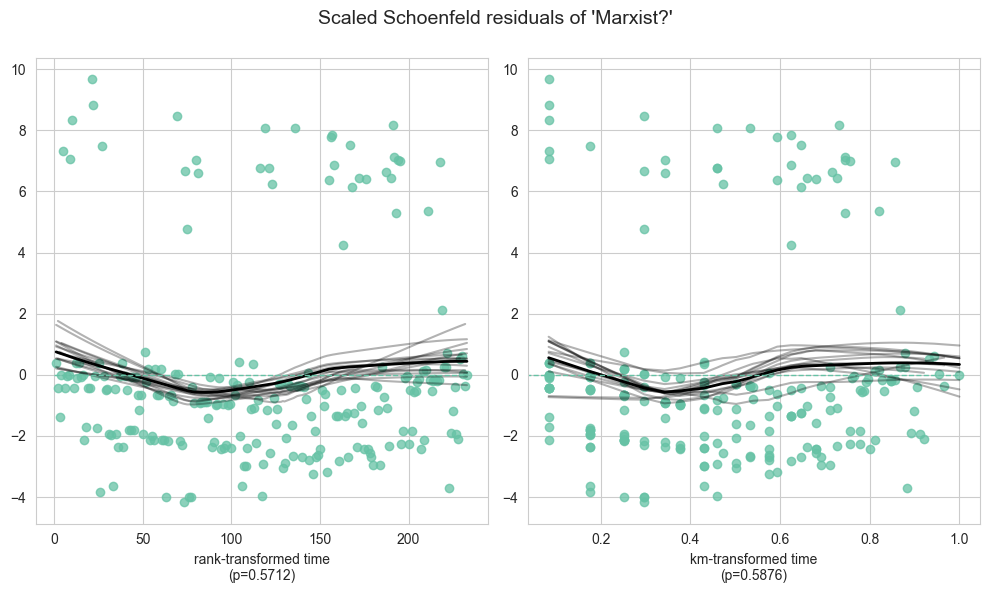

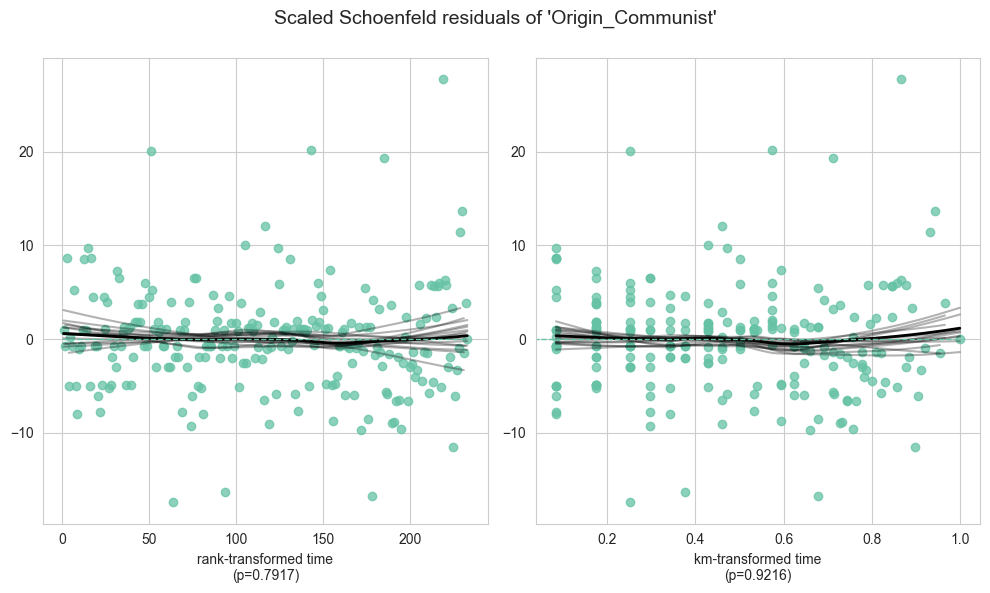

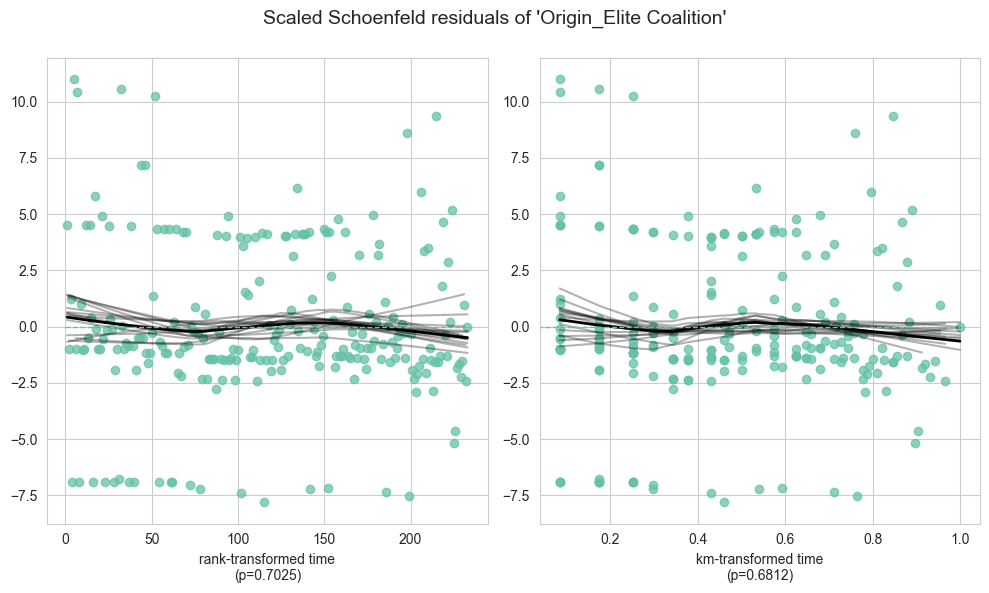

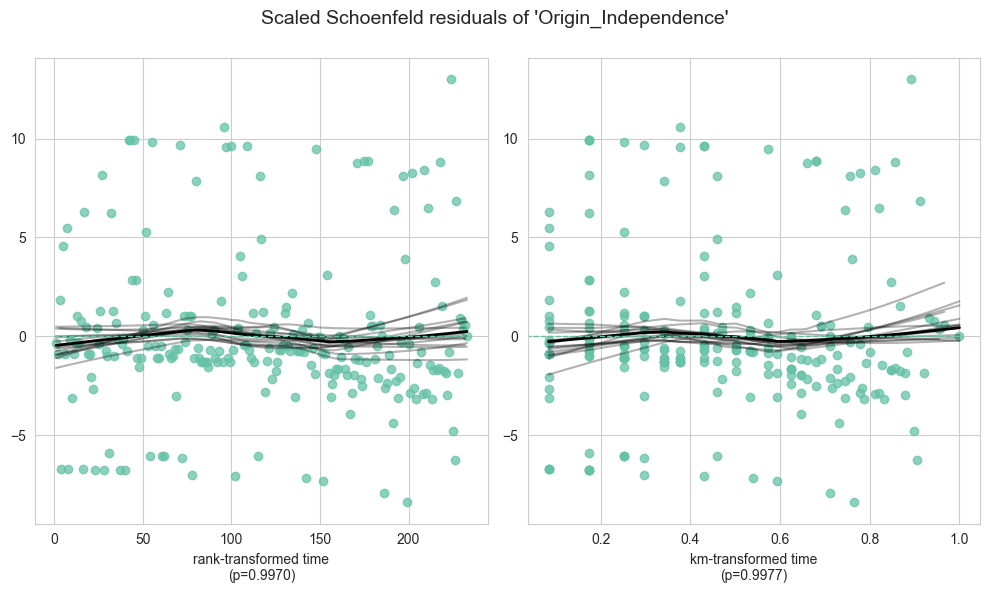

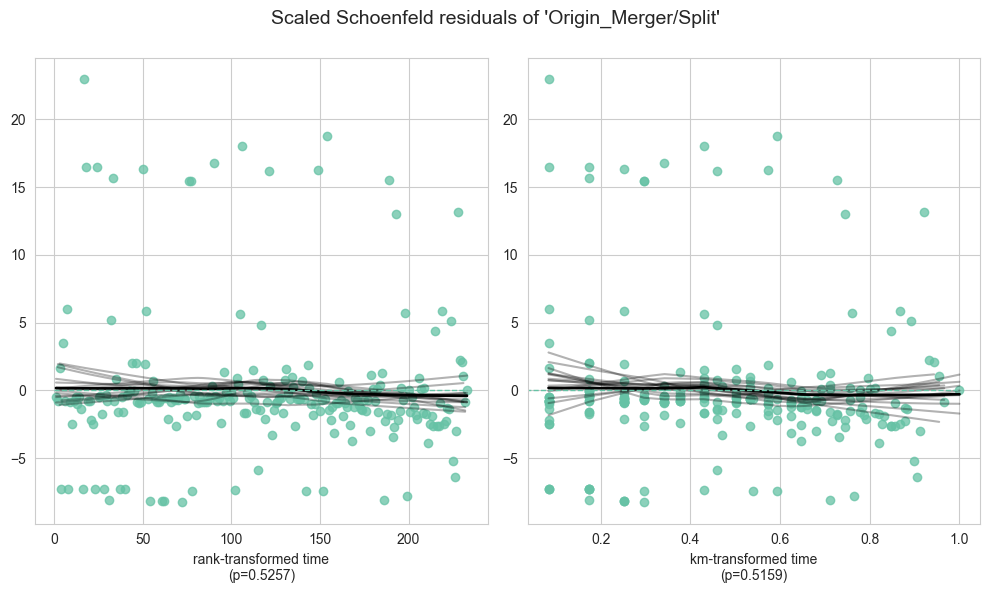

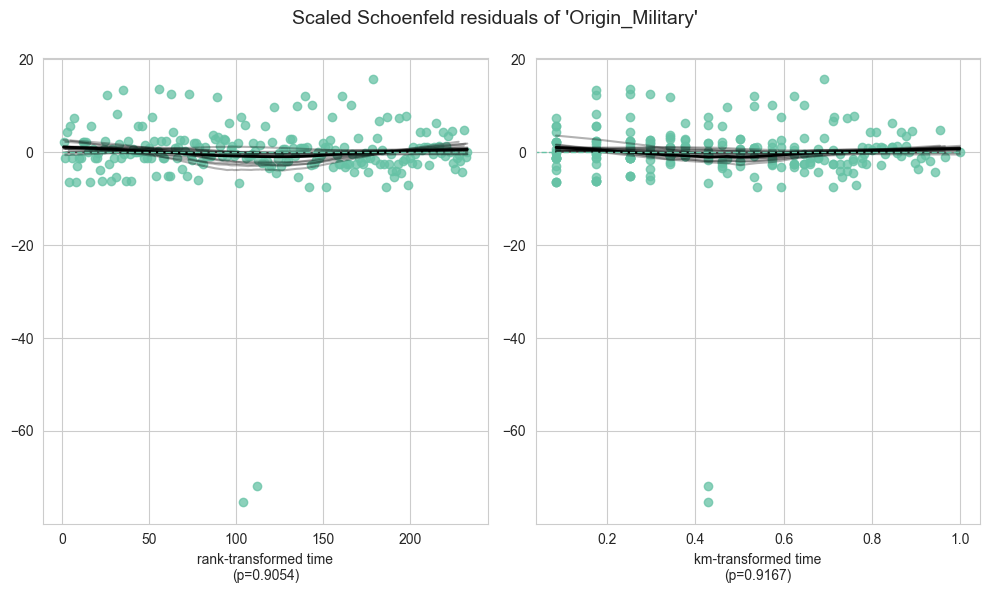

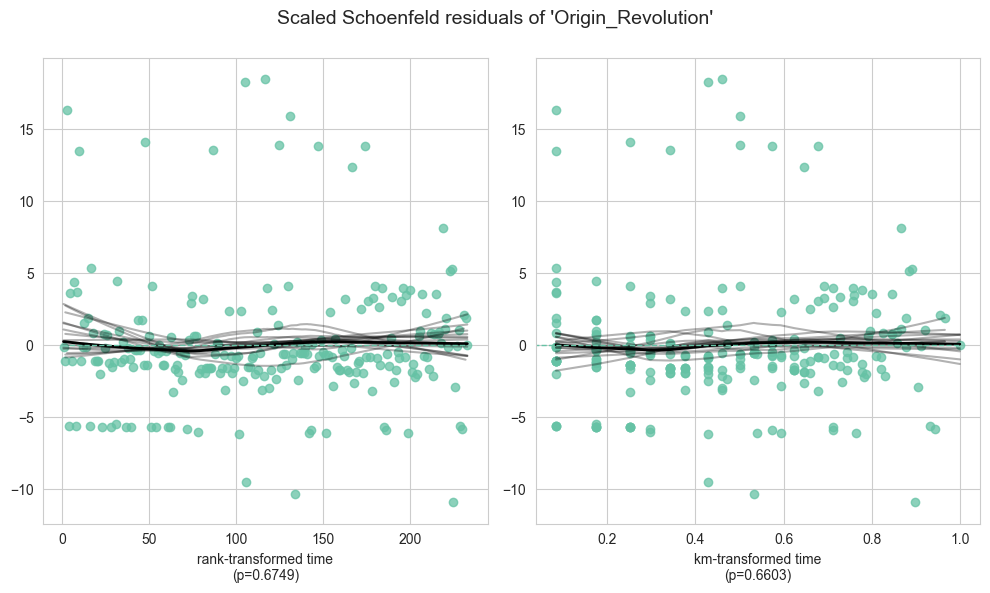

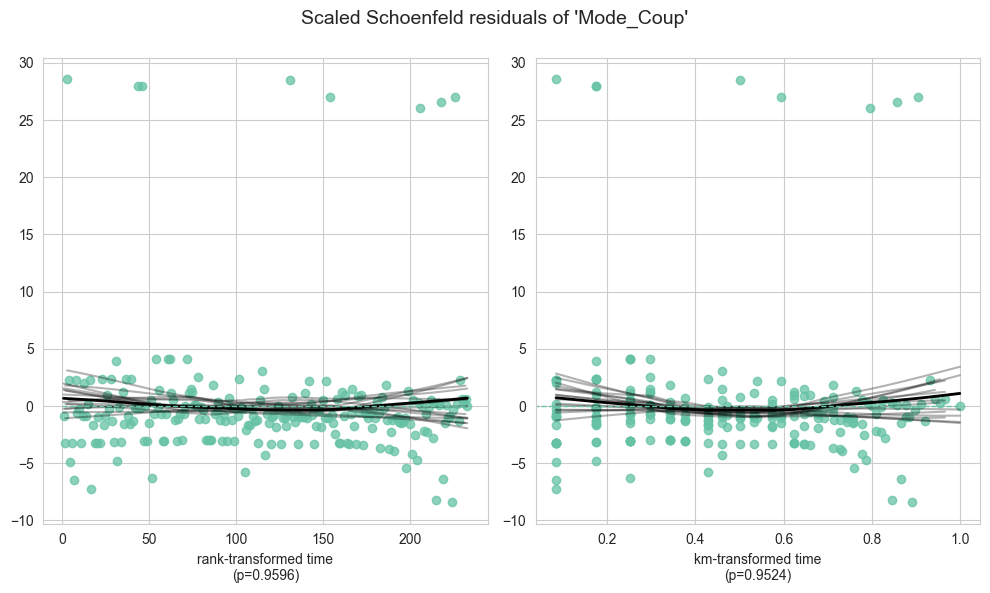

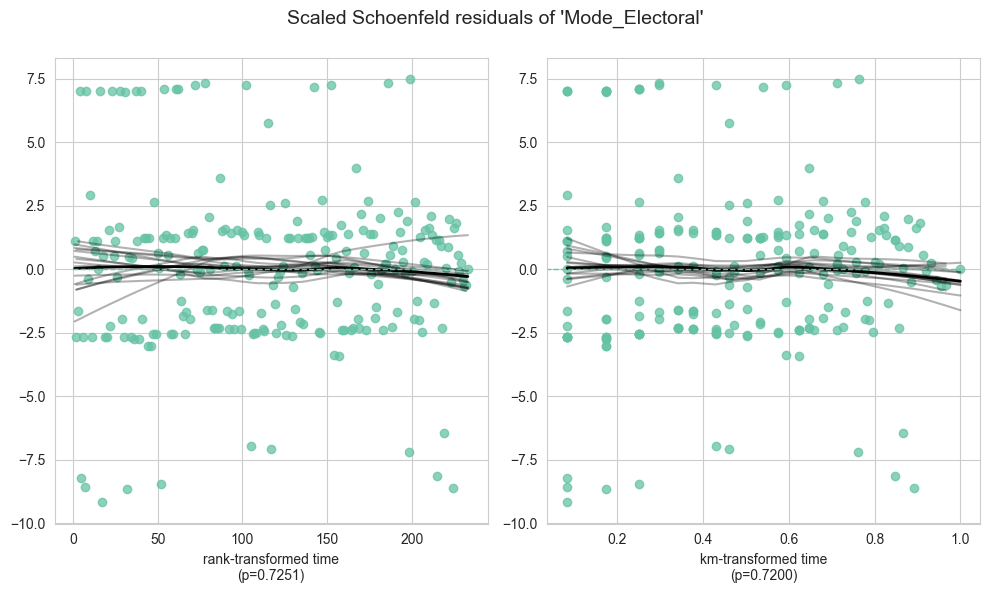

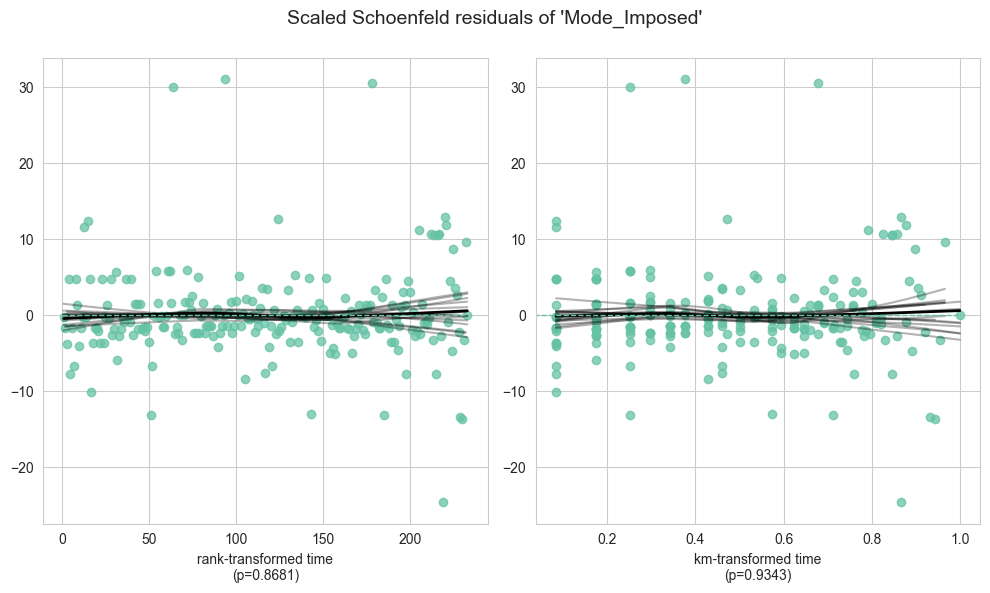

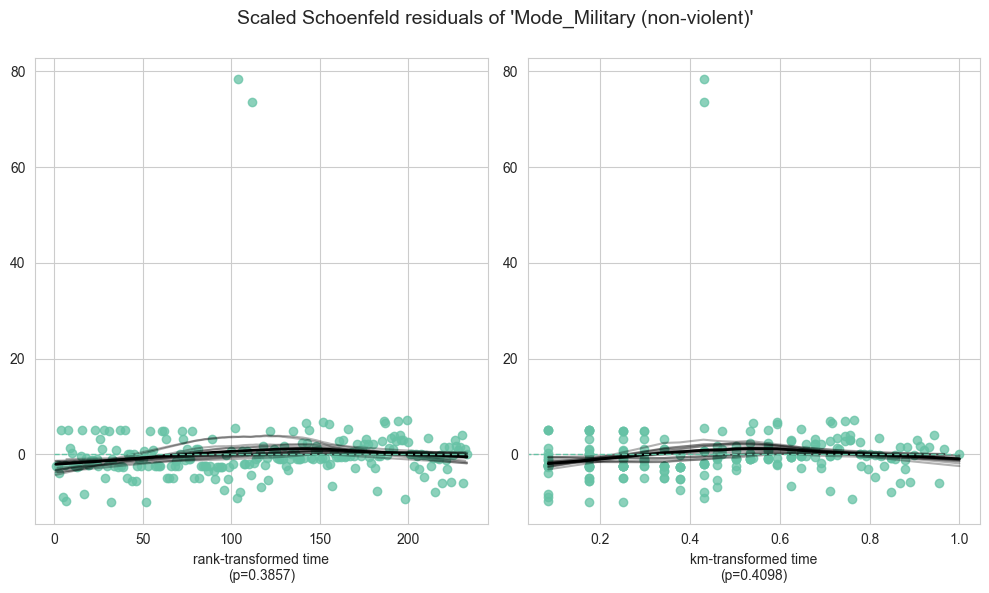

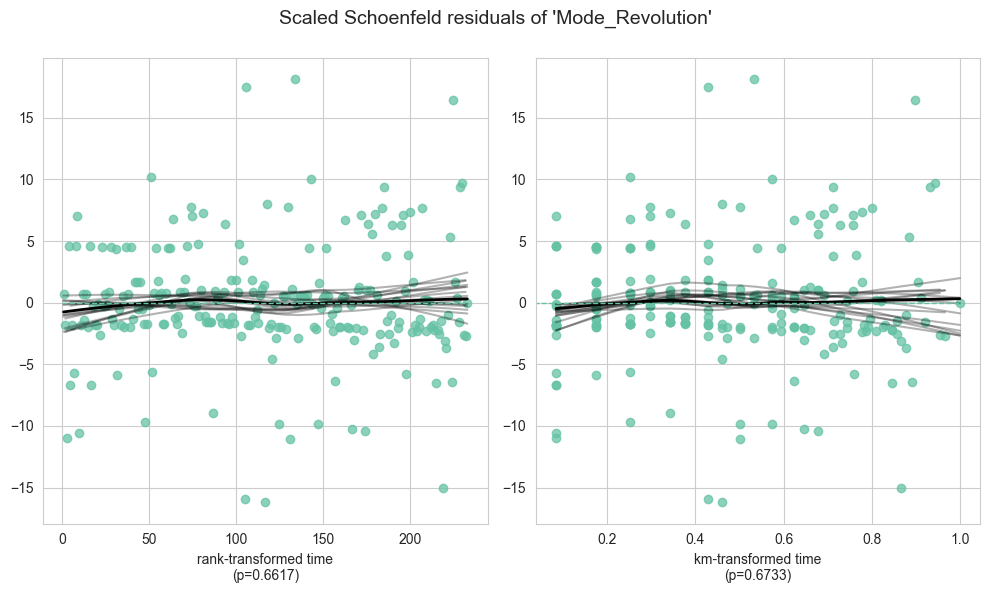

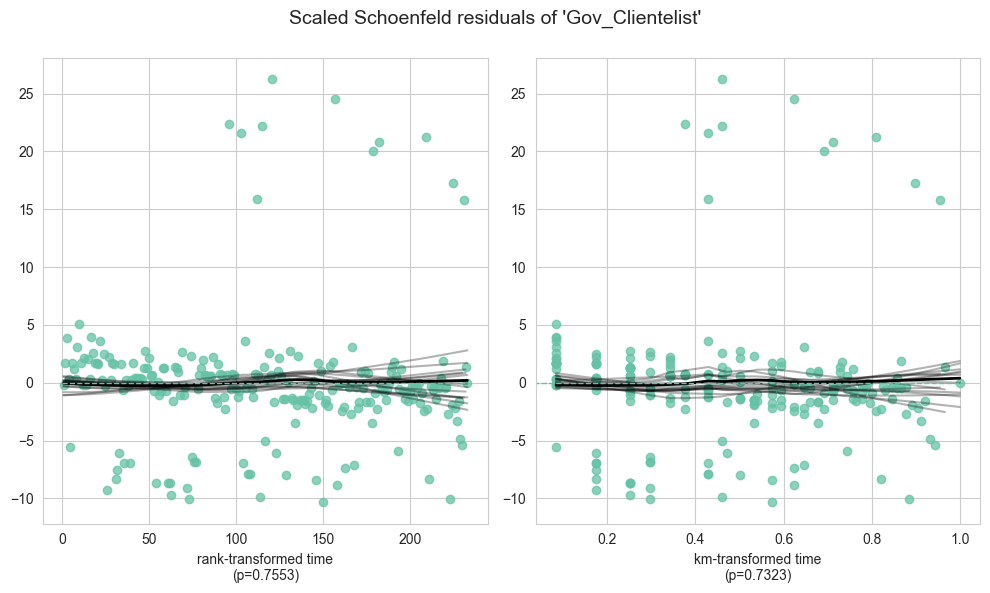

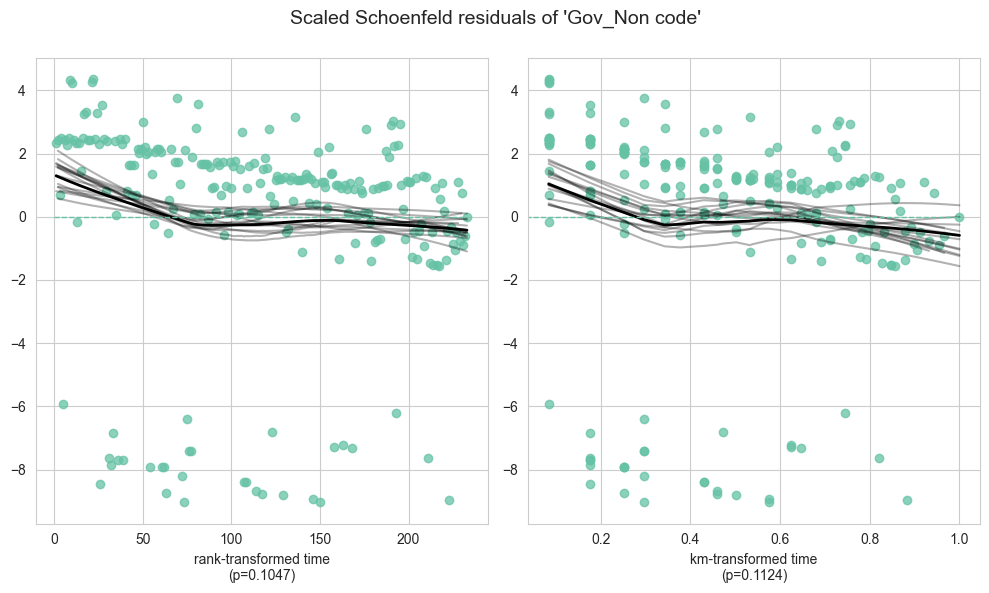

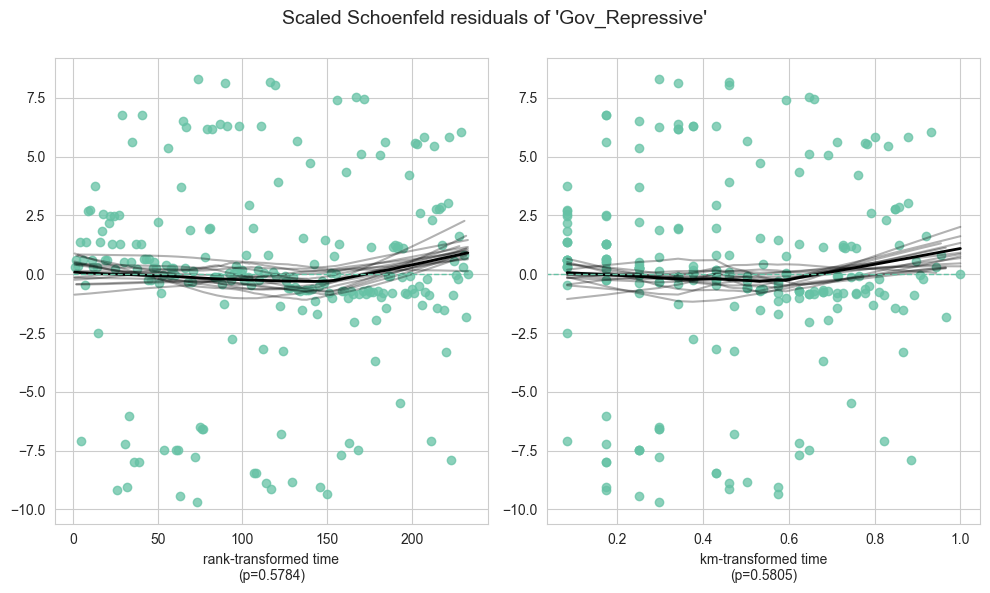

In [40]:
# ============================================================
# 9.1 Test de Schoenfeld (Risques Proportionnels)
# ============================================================
print("=" * 60)
print("TEST DE PROPORTIONNALITÉ DES RISQUES (Schoenfeld)")
print("=" * 60)
print("H0 : Les risques sont proportionnels (hypothèse valide)")
print(f"Un p < {ALPHA} indique une violation de la proportionnalité.\n")

import inspect
import lifelines
from lifelines import statistics as lifelines_statistics

# Vérification, dans la version installée, du point expliqué dans la note ci-dessus
ph_source = inspect.getsource(lifelines_statistics.proportional_hazard_test)
assert "standard_errors_" in ph_source, "la statistique du test n'utilise plus standard_errors_ : revoir la note 8.1"
assert np.allclose(cph.variance_matrix_.values, cph_model_based.variance_matrix_.values), \
    "variance_matrix_ différente entre le modèle groupé et le modèle classique"
print(f"lifelines {lifelines.__version__} : la statistique du test utilise standard_errors_ (robustes si cluster_col).")

try:
    cph_model_based.check_assumptions(cox_data, p_value_threshold=ALPHA, show_plots=True)
    ph_test = proportional_hazard_test(cph_model_based, cox_data, time_transform="rank")
    ph_pvalues = ph_test.summary["p"].sort_values()
    ph_violations = ph_pvalues[ph_pvalues < ALPHA].index.tolist()
    print("Variables avec violation (p < alpha) :", ph_violations)
    # Comparaison avec le test (incorrect) calculé sur le modèle groupé
    ph_clustered = proportional_hazard_test(cph, cox_data_cl, time_transform="rank").summary["p"]
    ph_compare = pd.DataFrame({"p (variance classique, retenu)": ph_test.summary["p"],
                               "p (modèle groupé, non retenu)": ph_clustered}).sort_values("p (variance classique, retenu)")
    ph_compare["verdict modifié"] = ((ph_compare.iloc[:, 0] < ALPHA) != (ph_compare.iloc[:, 1] < ALPHA))
    display(ph_compare.round(4))
    ph_changed = ph_compare.index[ph_compare["verdict modifié"]].tolist()
    print("Verdict différent selon la variance utilisée :", ph_changed or "aucun")
except Exception as e:
    ph_violations = []
    print(f"Note : {e}")
    print("Le test de Schoenfeld n'a pas pu être calculé pour toutes les variables.")

display(
    Markdown(
        "**Hypothèses (Schoenfeld).**\n"
        "- $H_0$ : les résidus de Schoenfeld ne sont pas corrélés avec le temps (proportionnalité respectée).\n"
        "- $H_1$ : corrélation significative (violation de proportionnalité).\n"
        f"- Règle : on rejette $H_0$ si p-value < $\\alpha = {ALPHA}$.\n\n"
        f"**Interprétation.** Les variables identifiées comme non proportionnelles sont {ph_violations}. "
        f"""Si p < {ALPHA} pour une variable, l'hypothèse de proportionnalité est violée pour cette variable. """
        "Les solutions sont : (1) stratifier le modèle de Cox sur cette variable, "
        "(2) ajouter une interaction terme x log(t), (3) passer à un modèle AFT paramétrique "
        "(voir Section 10)."
    )
)

### 9.2 Résidus de Martingale

Nous analysons les résidus de Martingale pour détecter des non-linéarités et des observations atypiques. L'objectif est de vérifier si les covariables continues sont correctement spécifiées.

Les résidus de martingale, de déviance et de score (8.2 et 8.3) ne dépendent que des coefficients estimés, identiques avec ou sans regroupement par pays : ils sont calculés sur le modèle groupé sans que cela modifie le diagnostic.

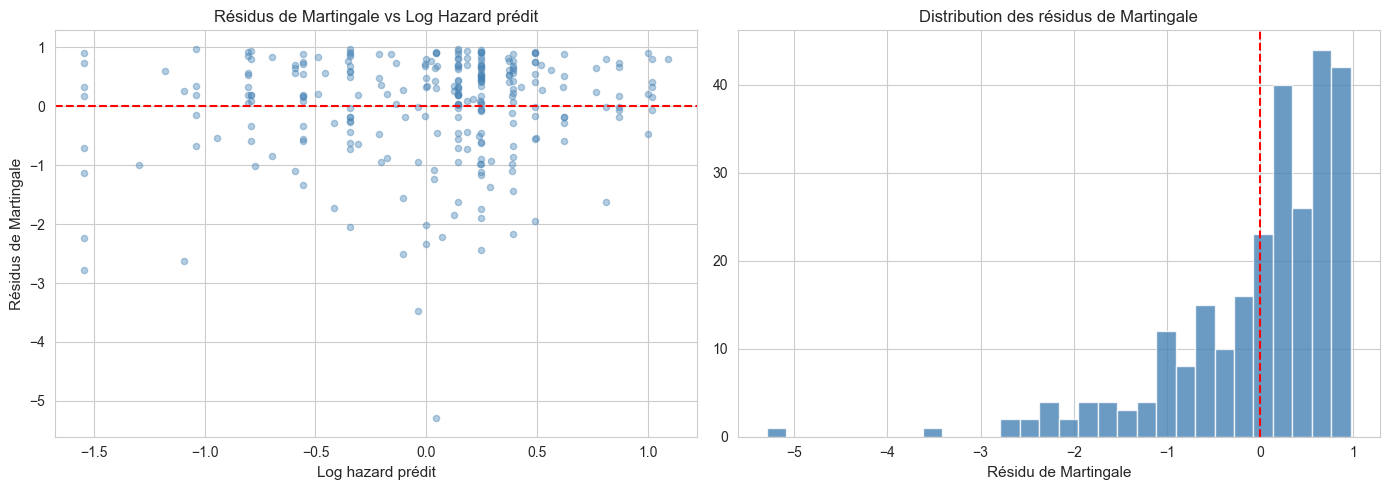

  Moyenne des résidus de Martingale : -0.0000 (attendu ≈ 0)


**Interprétation.** Le diagnostic de Martingale est conçu pour détecter les non-linéarités dans les covariables continues. Dans notre cas, les covariables étant majoritairement binaires, ce diagnostic est moins critique mais reste informatif pour identifier les observations atypiques proches des bornes de la distribution des résidus.

In [41]:
# ============================================================
# 9.2 Résidus de Martingale
# ============================================================
try:
    martingale_residuals = cph.compute_residuals(cox_data_cl, kind='martingale')['martingale']

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # vs prédictions
    log_hazard = cph.predict_log_partial_hazard(cox_data)
    axes[0].scatter(log_hazard, martingale_residuals, alpha=0.4, color='steelblue', s=20)
    axes[0].axhline(0, color='red', linestyle='--')
    axes[0].set_xlabel('Log hazard prédit', fontsize=11)
    axes[0].set_ylabel('Résidus de Martingale', fontsize=11)
    axes[0].set_title('Résidus de Martingale vs Log Hazard prédit', fontsize=12)

    # Histogramme
    axes[1].hist(martingale_residuals, bins=30, color='steelblue', edgecolor='white', alpha=0.8)
    axes[1].axvline(0, color='red', linestyle='--')
    axes[1].set_xlabel('Résidu de Martingale', fontsize=11)
    axes[1].set_title('Distribution des résidus de Martingale', fontsize=12)

    plt.tight_layout()
    plt.show()
    print(f"  Moyenne des résidus de Martingale : {martingale_residuals.mean():.4f} (attendu ≈ 0)")
except Exception as e:
    print(f"⚠ Résidus de Martingale : {e}")

display(
    Markdown(
        "**Interprétation.** Le diagnostic de Martingale est conçu pour détecter les non-linéarités "
        "dans les covariables continues. Dans notre cas, les covariables étant majoritairement "
        "binaires, ce diagnostic est moins critique mais reste informatif pour identifier les "
        "observations atypiques proches des bornes de la distribution des résidus."
    )
)

### 9.3 Résidus de Déviance et observations influentes

Nous analysons les résidus de déviance pour détecter des outliers et calculons aussi les résidus de score (dfbeta) pour identifier les observations influentes.

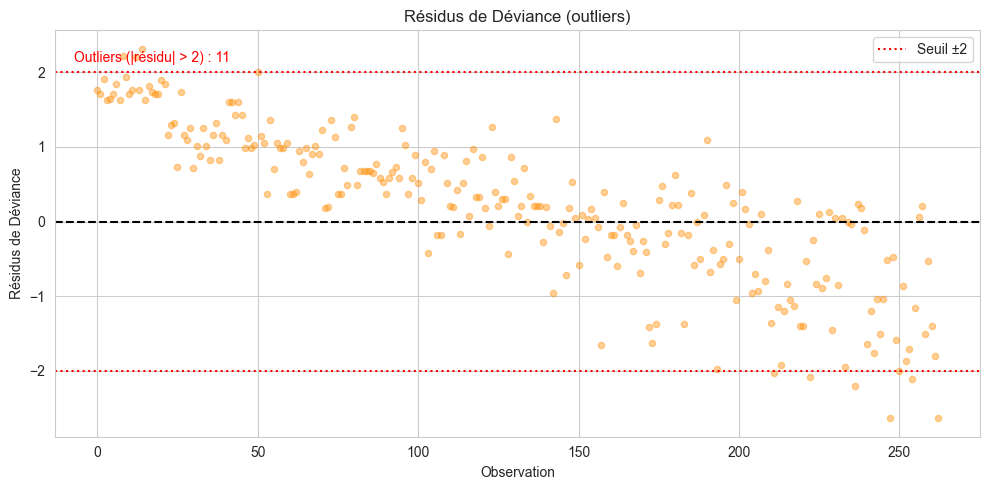

299    23.473697
268    20.917208
246    13.140893
81      9.270100
97      9.026783
dtype: float64

**Interprétation.** Les résidus de déviance identifient 11 observation(s) atypique(s) (|résidu| > 2). Les résidus de score (dfbeta) mettent en évidence les observations les plus influentes, listées dans `top_influential`.

In [42]:
# ============================================================
# 9.3 Residus de Deviance + Score (dfbeta)
# ============================================================
n_outliers = np.nan
try:
    deviance_residuals = cph.compute_residuals(cox_data_cl, kind="deviance")["deviance"]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.scatter(range(len(deviance_residuals)), deviance_residuals, alpha=0.4, color="darkorange", s=20)
    ax.axhline(0, color="black", linestyle="--")
    ax.axhline(RESID_OUTLIER_THRESHOLD, color="red", linestyle=":", label=f"Seuil ±{RESID_OUTLIER_THRESHOLD}")
    ax.axhline(-RESID_OUTLIER_THRESHOLD, color="red", linestyle=":")
    ax.set_xlabel("Observation")
    ax.set_ylabel("Résidus de Déviance")
    ax.set_title("Résidus de Déviance (outliers)")
    ax.legend()

    n_outliers = int((deviance_residuals.abs() > RESID_OUTLIER_THRESHOLD).sum())
    ax.text(0.02, 0.95, f"Outliers (|résidu| > {RESID_OUTLIER_THRESHOLD}) : {n_outliers}",
            transform=ax.transAxes, fontsize=10, color="red",
            verticalalignment="top")

    plt.tight_layout()
    plt.show()

    # Residus de score (dfbeta)
    score_resids = cph.compute_residuals(cox_data_cl, kind="score")
    score_norm = (score_resids ** 2).sum(axis=1)
    top_influential = score_norm.sort_values(ascending=False).head(5)
    display(top_influential)

except Exception as e:
    print(f"Résidus de Déviance / score : {e}")

display(
    Markdown(
        f"""**Interprétation.** Les résidus de déviance identifient {n_outliers} observation(s) atypique(s) """
        f"""(|résidu| > {RESID_OUTLIER_THRESHOLD}). Les résidus de score (dfbeta) mettent en évidence """
        "les observations les plus influentes, listées dans `top_influential`."
    )
)

### 9.4 VIF (multicolinéarité)

Nous calculons les facteurs d'inflation de variance (VIF) pour évaluer la redondance entre covariables. L'objectif est de détecter des effets de multicolinéarité potentiellement problématiques.

FACTEURS D'INFLATION DE LA VARIANCE (VIF)
VIF > 10 indique une multicolinéarité problématique



,Variable,VIF,Interpretation
10,Mode_Military (non-violent),6.77,🟡 Modéré
5,Origin_Military,6.65,🟡 Modéré
1,Origin_Communist,2.86,🟢 Faible
11,Mode_Revolution,2.63,🟢 Faible
6,Origin_Revolution,2.35,🟢 Faible
8,Mode_Electoral,2.33,🟢 Faible
13,Gov_Non code,2.32,🟢 Faible
14,Gov_Repressive,2.16,🟢 Faible
9,Mode_Imposed,2.09,🟢 Faible
2,Origin_Elite Coalition,1.88,🟢 Faible


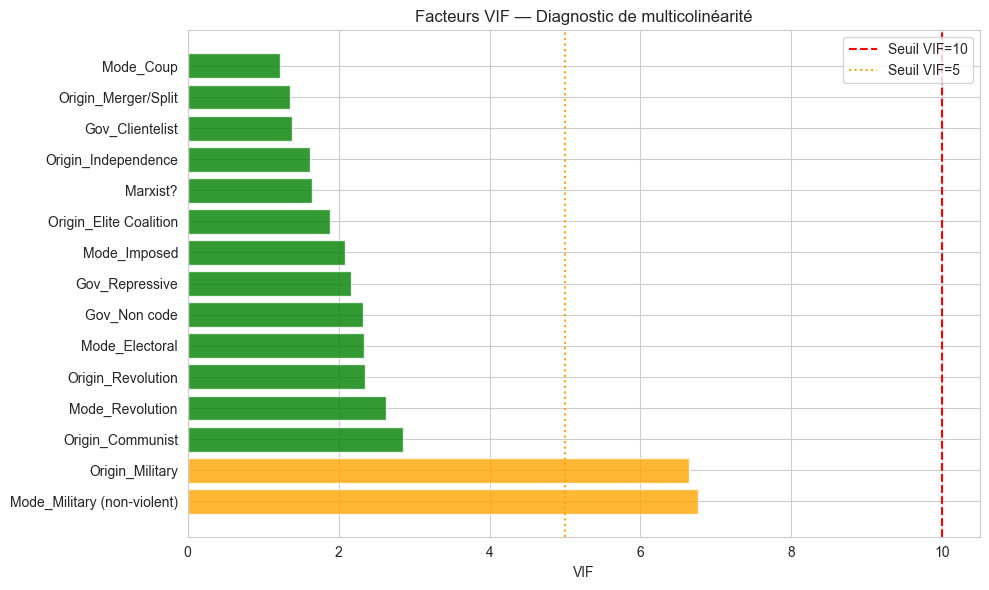

**Interprétation.** Les VIF élevés signalent des redondances entre covariables. Pour des variables binaires (dummies), un VIF > 10 signale souvent une redondance entre catégories encodées, pas nécessairement une multicolinéarité substantielle.

**Bilan :**
- Hypothèse de proportionnalité testée (Schoenfeld).
- Résidus de Martingale et de déviance examinés.
- Observations influentes repérées via résidus de score.
- Multicolinéarité évaluée par VIF.
- Prochaine section : comparaison de modèles (Section 10).

In [43]:
# ============================================================
# 9.4 Facteurs d'Inflation de la Variance (VIF)
# ============================================================
print("=" * 50)
print("FACTEURS D'INFLATION DE LA VARIANCE (VIF)")
print("=" * 50)
print(f"VIF > {VIF_HIGH} indique une multicolinéarité problématique\n")

try:
    X_vif = df_model[covariates].astype(float).copy()
    X_vif = X_vif.assign(const=1)  # Ajouter constante

    vif_data = pd.DataFrame()
    vif_data["Variable"] = X_vif.columns[:-1]  # exclure const
    vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i)
                        for i in range(len(X_vif.columns)-1)]
    vif_data = vif_data.sort_values("VIF", ascending=False)
    vif_data["Interpretation"] = vif_data["VIF"].apply(
        lambda v: "🔴 Élevé" if v > VIF_HIGH else ("🟡 Modéré" if v > VIF_MODERATE else "🟢 Faible"))
    display(vif_data.round(2))

    fig, ax = plt.subplots(figsize=(10, max(4, len(vif_data) * 0.4)))
    colors_vif = ["red" if v > VIF_HIGH else ("orange" if v > VIF_MODERATE else "green") for v in vif_data["VIF"]]
    ax.barh(vif_data["Variable"], vif_data["VIF"], color=colors_vif, alpha=0.8)
    ax.axvline(VIF_HIGH, color="red", linestyle="--", label=f"Seuil VIF={VIF_HIGH}")
    ax.axvline(VIF_MODERATE, color="orange", linestyle=":", label=f"Seuil VIF={VIF_MODERATE}")
    ax.set_xlabel("VIF")
    ax.set_title("Facteurs VIF — Diagnostic de multicolinéarité")
    ax.legend()
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Calcul VIF : {e}")

display(
    Markdown(
        f"""**Interprétation.** Les VIF élevés signalent des redondances entre covariables. """
        f"""Pour des variables binaires (dummies), un VIF > {VIF_HIGH} signale souvent une redondance """
        "entre catégories encodées, pas nécessairement une multicolinéarité substantielle.\n\n"
        "**Bilan :**\n"
        "- Hypothèse de proportionnalité testée (Schoenfeld).\n"
        "- Résidus de Martingale et de déviance examinés.\n"
        "- Observations influentes repérées via résidus de score.\n"
        "- Multicolinéarité évaluée par VIF.\n"
        "- Prochaine section : comparaison de modèles (Section 10)."
    )
)

## 10. Comparaison de modèles — du plus simple au plus complexe

Dans cette section, nous comparons plusieurs spécifications de modèles de survie. L'objectif est d'évaluer le compromis entre complexité et pouvoir prédictif en utilisant la log-vraisemblance, l'AIC et le C-index.

### 10.1 Modèle nul (baseline)

Nous estimons un modèle de Cox sans covariables. L'objectif est d'obtenir un point de référence (C-index de base par définition).

In [44]:
# ============================================================
# 10.1 Modele nul (sans covariables)
# ============================================================
cph_null = CoxPHFitter()
cph_null.fit(df_model[["duration", "event"]], duration_col="duration", event_col="event")
null_loglik = float(cph_null.log_likelihood_)
null_aic = float(cph_null.AIC_partial_) if hasattr(cph_null, "AIC_partial_") else np.nan
null_c_index = 0.5

print(f"Log-vraisemblance (nul) : {null_loglik:.4f}")
print(f"AIC (nul)               : {null_aic:.4f}")
print(f"C-index (nul)           : {null_c_index:.2f}")

display(
    Markdown(
        f"""**Interprétation.** Le modèle nul sert de baseline avec C-index = {null_c_index:.2f}. """
        "Il fournit un point de comparaison pour évaluer l'apport des covariables dans les modèles suivants."
    )
)

Log-vraisemblance (nul) : -1104.2335
AIC (nul)               : 2208.4670
C-index (nul)           : 0.50


**Interprétation.** Le modèle nul sert de baseline avec C-index = 0.50. Il fournit un point de comparaison pour évaluer l'apport des covariables dans les modèles suivants.

### 10.2 Modèle univarié (Origin uniquement)

Nous estimons un modèle de Cox avec uniquement les dummies de `Origin`. L'objectif est de mesurer l'effet brut de l'origine sur la survie.

In [45]:
# ============================================================
# 10.2 Cox univarie sur Origin
# ============================================================
origin_cols = [c for c in df_model.columns if c.startswith("Origin_")]
if not origin_cols:
    raise ValueError("Aucune dummy 'Origin_' disponible dans df_model.")

cox_origin = df_model[["duration", "event"] + origin_cols]
cph_origin = CoxPHFitter()
cph_origin.fit(cox_origin, duration_col="duration", event_col="event")

origin_loglik = float(cph_origin.log_likelihood_)
origin_aic = float(cph_origin.AIC_partial_) if hasattr(cph_origin, "AIC_partial_") else np.nan
origin_c_index = float(cph_origin.concordance_index_)
origin_k = len(origin_cols)

print(f"Log-vraisemblance (Origin) : {origin_loglik:.4f}")
print(f"AIC (Origin)               : {origin_aic:.4f}")
print(f"C-index (Origin)           : {origin_c_index:.4f}")

display(
    Markdown(
        f"""**Interprétation.** Le modèle univarié capture l'effet brut de l'origine, avec un C-index de {origin_c_index:.4f}. """
        "Il sert de référence intermédiaire entre le modèle nul et le modèle complet."
    )
)

Log-vraisemblance (Origin) : -1083.0885
AIC (Origin)               : 2178.1770
C-index (Origin)           : 0.6124


**Interprétation.** Le modèle univarié capture l'effet brut de l'origine, avec un C-index de 0.6124. Il sert de référence intermédiaire entre le modèle nul et le modèle complet.

### 10.3 Cox complet (modèle principal)

Nous réutilisons le modèle principal estimé en Section 7 pour récupérer ses métriques (log-vraisemblance, AIC, C-index).

In [46]:
# ============================================================
# 10.3 Metriques du Cox complet
# ============================================================
full_loglik = float(cph.log_likelihood_)
full_aic = float(cph.AIC_partial_) if hasattr(cph, "AIC_partial_") else np.nan
full_c_index = float(cph.concordance_index_)
full_k = len(covariates)

print(f"Log-vraisemblance (Cox complet) : {full_loglik:.4f}")
print(f"AIC (Cox complet)               : {full_aic:.4f}")
print(f"C-index (Cox complet)           : {full_c_index:.4f}")

display(
    Markdown(
        f"""**Interprétation.** Le modèle complet atteint un C-index de {full_c_index:.4f}, """
        "indiquant sa capacité discriminante par rapport aux modèles plus simples."
    )
)

Log-vraisemblance (Cox complet) : -1073.5271
AIC (Cox complet)               : 2177.0542
C-index (Cox complet)           : 0.6415


**Interprétation.** Le modèle complet atteint un C-index de 0.6415, indiquant sa capacité discriminante par rapport aux modèles plus simples.

### 10.3b Apport du mode d'accession (test du rapport de vraisemblance)

Nous testons si le mode d'accession au pouvoir (`Mode_*`, 5 indicatrices) apporte de l'information au-delà des autres covariables, en comparant le modèle complet au même modèle sans ces indicatrices. Les deux modèles sont estimés sans pénalisation, condition de validité du test.

- $H_0$ : les coefficients `Mode_*` sont tous nuls.
- Statistique : $LR = 2(\ell_{complet} - \ell_{sans\ mode}) \sim \chi^2(5)$ sous $H_0$.

In [47]:
# ============================================================
# 10.3b Test LR : apport du mode d'accession
# ============================================================
mode_cols = [c for c in covariates if c.startswith("Mode_")]
mode_lr_stat = mode_lr_p = np.nan
mode_lr_df = len(mode_cols)
if mode_cols:
    cph_with_mode = CoxPHFitter().fit(cox_data, "duration", "event")
    cph_without_mode = CoxPHFitter().fit(cox_data.drop(columns=mode_cols), "duration", "event")
    mode_lr_stat = float(2 * (cph_with_mode.log_likelihood_ - cph_without_mode.log_likelihood_))
    mode_lr_p = float(stats.chi2.sf(mode_lr_stat, mode_lr_df))
    print(f"LR = {mode_lr_stat:.2f}, ddl = {mode_lr_df}, p = {mode_lr_p:.4f}")

mode_verdict = ("apporte une information significative" if mode_lr_p < ALPHA
                else "n'apporte pas d'information significative")
display(Markdown(
    f"**Interprétation.** Le mode d'accession {mode_verdict} au-delà des autres covariables "
    f"($\\chi^2({mode_lr_df}) = {mode_lr_stat:.2f}$, p = {mode_lr_p:.4f}). "
    "Il est conservé dans le modèle pour ne perdre aucune information (il contient aussi `Violence`)."
))


LR = 6.74, ddl = 5, p = 0.2403

**Interprétation.** Le mode d'accession n'apporte pas d'information significative au-delà des autres covariables ($\chi^2(5) = 6.74$, p = 0.2403). Il est conservé dans le modèle pour ne perdre aucune information (il contient aussi `Violence`).

### 10.4 Cox stratifié

Nous estimons un Cox stratifié sur la première variable en violation de proportionnalité (Section 9.1), à l'exclusion de la modalité « Non codé » de la stratégie de gouvernance, qui n'est pas une stratégie. En l'absence de violation, le code stratifié sur la première covariable, à titre illustratif. L'objectif est de relaxer l'hypothèse de risques proportionnels pour cette variable.

In [48]:
# ============================================================
# 10.4 Cox stratifie
# ============================================================
# « Gov_Non code » n'est pas une stratégie : elle n'est jamais retenue comme variable de stratification
all_violations = ph_violations if "ph_violations" in globals() else []
strata_candidates = [v for v in all_violations if not v.endswith("Non code")]
strata_illustrative = not strata_candidates
if strata_candidates:
    strata_var = "Military" if "Military" in strata_candidates else strata_candidates[0]
else:
    strata_var = "Military" if "Military" in df_model.columns else covariates[0]

cox_strat_data = df_model[["duration", "event"] + covariates].assign(Country=country_of_spell.values)
cph_strat = CoxPHFitter()
cph_strat.fit(cox_strat_data, duration_col="duration", event_col="event", strata=strata_var, cluster_col="Country")

strat_loglik = float(cph_strat.log_likelihood_)
strat_aic = float(cph_strat.AIC_partial_) if hasattr(cph_strat, "AIC_partial_") else np.nan
strat_c_index = float(cph_strat.concordance_index_)
strat_k = len(covariates)

print(f"Strates: {strata_var}")
print(f"Log-vraisemblance (stratifié) : {strat_loglik:.4f}")
print(f"AIC (stratifié)               : {strat_aic:.4f}")
print(f"C-index (stratifié)           : {strat_c_index:.4f}")

display(
    Markdown(
        f"""**Interprétation.** Le modèle stratifié sur {strata_var} permet d'autoriser un hazard de base distinct par strate, """
        f"""ce qui peut corriger une violation de proportionnalité. Son C-index est {strat_c_index:.4f}. """
        + (f"Aucune covariable substantielle ne viole l'hypothèse de proportionnalité (Section 9.1) : la "
           f"stratification sur {strata_var} est **illustrative**." if strata_illustrative else
           f"{strata_var} viole l'hypothèse de proportionnalité (Section 9.1).")
        + (" La modalité « Non codé », signalée par le test, n'est pas retenue." if
           any(v.endswith("Non code") for v in all_violations) else "")
    )
)

Strates: Marxist?
Log-vraisemblance (stratifié) : -956.1331
AIC (stratifié)               : 1940.2663
C-index (stratifié)           : 0.6137


**Interprétation.** Le modèle stratifié sur Marxist? permet d'autoriser un hazard de base distinct par strate, ce qui peut corriger une violation de proportionnalité. Son C-index est 0.6137. Aucune covariable substantielle ne viole l'hypothèse de proportionnalité (Section 9.1) : la stratification sur Marxist? est **illustrative**.

### 10.5 Cox pénalisé ridge

Nous re-estimons le modèle avec le pénaliseur qui maximise le C-index en validation croisée (Section 7.2). L'objectif est d'évaluer ce que la régularisation apporte en prédiction, par comparaison avec le modèle principal légèrement pénalisé. Ses hazard ratios, réduits vers 1, ne servent pas à l'inférence.

In [49]:
# ============================================================
# 10.5 Cox penalise ridge (penaliseur choisi par validation croisee)
# ============================================================
cph_pen = CoxPHFitter(penalizer=penalizer_cv)
cph_pen.fit(cox_data, duration_col="duration", event_col="event")

pen_loglik = float(cph_pen.log_likelihood_)
pen_aic = float(cph_pen.AIC_partial_) if hasattr(cph_pen, "AIC_partial_") else np.nan
pen_c_index = float(cph_pen.concordance_index_)
pen_k = len(covariates)

print(f"Log-vraisemblance (pénalisé) : {pen_loglik:.4f}")
print(f"AIC (pénalisé)               : {pen_aic:.4f}")
print(f"C-index (pénalisé)           : {pen_c_index:.4f}")

display(
    Markdown(
        f"""**Interprétation.** Avec penalizer = {penalizer_cv}, la pénalisation ridge produit un C-index de """
        f"""{pen_c_index:.4f} sur les données d'estimation. Elle réduit les coefficients vers 0 sans supprimer de """
        "variables ; son intérêt se juge en validation croisée (Section 10.8)."
    )
)

Log-vraisemblance (pénalisé) : -1088.5087
AIC (pénalisé)               : 2207.0175
C-index (pénalisé)           : 0.6396


**Interprétation.** Avec penalizer = 1.0, la pénalisation ridge produit un C-index de 0.6396 sur les données d'estimation. Elle réduit les coefficients vers 0 sans supprimer de variables ; son intérêt se juge en validation croisée (Section 10.8).

### 10.6 Cox avec interaction Origin x Marxist?

Nous ajoutons un terme d'interaction pour tester si l'effet de l'origine est modifié par l'idéologie marxiste. L'objectif est d'évaluer un effet conditionnel.

In [50]:
# ============================================================
# 10.6 Interaction Origin x Marxist?
# ============================================================
int_loglik = np.nan
int_aic = np.nan
int_c_index = np.nan
int_k = np.nan

origin_rev_col = "Origin_Revolution"
marxist_col = "Marxist?"

has_origin_rev = origin_rev_col in df_model.columns
has_marxist = marxist_col in df_model.columns

if has_origin_rev and has_marxist:
    cox_interact = cox_data_cl.copy()
    cox_interact["Origin_x_Marxist"] = cox_interact[origin_rev_col] * cox_interact[marxist_col]
    # Verifier qu'on ne cree pas une colonne constante
    if cox_interact["Origin_x_Marxist"].nunique() < 2:
        print("Interaction constante (variance nulle) -> ignorée.")
    else:
        try:
            cph_int = CoxPHFitter(penalizer=penalizer_used)
            cph_int.fit(cox_interact, duration_col="duration", event_col="event", cluster_col="Country")
            int_loglik = float(cph_int.log_likelihood_)
            int_aic = float(cph_int.AIC_partial_) if hasattr(cph_int, "AIC_partial_") else np.nan
            int_c_index = float(cph_int.concordance_index_)
            int_k = len(cox_interact.columns) - 3   # sans duration, event, Country
            if "Origin_x_Marxist" in cph_int.summary.index:
                p_int = cph_int.summary.loc["Origin_x_Marxist", "p"]
                print(f"Interaction p-value : {p_int:.4f}")
        except Exception as e:
            print(f"Échec de l'estimation avec interaction : {e}")
else:
    missing = [c for c, ok in [(origin_rev_col, has_origin_rev), (marxist_col, has_marxist)] if not ok]
    print(f"Interaction non disponible (colonnes manquantes : {missing}).")

display(
    Markdown(
        f"**Interprétation.** Le modèle avec interaction fournit un C-index de {int_c_index}. "
        "Une p-value faible pour l'interaction indiquerait que l'effet de l'origine dépend du statut marxiste."
    )
)


Interaction p-value : 0.0512

**Interprétation.** Le modèle avec interaction fournit un C-index de 0.6445749266037853. Une p-value faible pour l'interaction indiquerait que l'effet de l'origine dépend du statut marxiste.

### 10.7 Modèle Weibull AFT

Nous estimons un modèle paramétrique Weibull AFT et récupérons ses métriques. L'objectif est de comparer la discrimination via le C-index.

> **⚠️ Attention :** L'AIC du modèle de Cox est calculée à partir de la **vraisemblance partielle**, tandis que l'AIC du Weibull est basée sur la **vraisemblance complète**. Ces AIC ne sont **pas directement comparables**. La comparaison se fait via le C-index et l'analyse des résidus.

> **📌 Remarque :** `lifelines` ne propose pas de regroupement par pays (`cluster_col`) pour les modèles AFT. Seules les métriques globales du Weibull (log-vraisemblance, AIC, C-index), qui ne dépendent pas des erreurs standards, sont utilisées ici.

In [51]:
# ============================================================
# 10.7 Weibull AFT
# ============================================================
waf = WeibullAFTFitter()
waf.fit(cox_data, duration_col="duration", event_col="event")

weib_loglik = float(waf.log_likelihood_)
weib_aic = float(waf.AIC_) if hasattr(waf, "AIC_") else np.nan
weib_c_index = float(waf.concordance_index_)
weib_k = len(waf.params_)

print(f"Log-vraisemblance (Weibull) : {weib_loglik:.4f}")
print(f"AIC (Weibull)               : {weib_aic:.4f}")
print(f"C-index (Weibull)           : {weib_c_index:.4f}")

display(
    Markdown(
        f"""**Interprétation.** Le modèle Weibull AFT atteint un C-index de {weib_c_index:.4f}. """
        "La comparaison avec Cox doit privilégier le C-index et les résidus plutôt que l'AIC."
    )
)

Log-vraisemblance (Weibull) : -881.1932
AIC (Weibull)               : 1796.3865
C-index (Weibull)           : 0.6402


**Interprétation.** Le modèle Weibull AFT atteint un C-index de 0.6402. La comparaison avec Cox doit privilégier le C-index et les résidus plutôt que l'AIC.

### 10.8 Tableau récapitulatif des modèles

Nous consolidons les métriques des modèles comparés et identifions le meilleur compromis entre complexité et pouvoir prédictif.

In [52]:
# ============================================================
# 10.8 Tableau recapitulatif
# ============================================================
# C-index en validation croisee pour les modeles Cox non stratifies
# (le Cox stratifie et le Weibull AFT ne sont pas evalues de cette facon).
cv_origin = cv_c_index(cox_origin, 0.0)[0]
cv_pen = cv_c_index(cox_data, penalizer_cv)[0]
cv_int = cv_c_index(cox_interact.drop(columns="Country"), penalizer_used)[0]   # Country : regroupement, pas covariable if not np.isnan(int_c_index) else np.nan

comparison_df = pd.DataFrame({
    "Modele": [
        "Nul",
        "Univarié (Origin)",
        "Cox complet",
        "Cox stratifié",
        "Cox pénalisé (ridge)",
        "Cox + interaction",
        "Weibull AFT",
    ],
    "Log-vraisemblance": [
        null_loglik,
        origin_loglik,
        full_loglik,
        strat_loglik,
        pen_loglik,
        int_loglik,
        weib_loglik,
    ],
    "AIC": [
        null_aic,
        origin_aic,
        full_aic,
        strat_aic,
        pen_aic,
        int_aic,
        weib_aic,
    ],
    "C-index": [
        null_c_index,
        origin_c_index,
        full_c_index,
        strat_c_index,
        pen_c_index,
        int_c_index,
        weib_c_index,
    ],
    "C-index (validation croisée)": [
        0.5,
        cv_origin,
        cv_c_index_main,
        np.nan,
        cv_pen,
        cv_int,
        np.nan,
    ],
    "Nb paramètres": [
        0,
        origin_k,
        full_k,
        strat_k,
        pen_k,
        int_k,
        weib_k,
    ],
})

# L'AIC n'est comparable qu'entre modeles Cox non stratifies estimes sur les memes donnees :
# le Weibull AFT utilise la vraisemblance complete et le Cox stratifie une vraisemblance par strate.
aic_comparable = ~comparison_df["Modele"].isin(["Weibull AFT", "Cox stratifié"])

display(
    comparison_df.style
    .highlight_max(subset=["C-index (validation croisée)"], color="lightgreen")
    .highlight_min(subset=pd.IndexSlice[comparison_df.index[aic_comparable], ["AIC"]], color="lightblue")
)

# Meilleur modele : C-index hors echantillon (le C-index d'estimation favorise toujours le modele le plus complexe)
best_c_index_model = comparison_df.loc[comparison_df["C-index (validation croisée)"].idxmax(), "Modele"]
best_c_index_value = float(comparison_df["C-index (validation croisée)"].max())
best_in_sample_model = comparison_df.loc[comparison_df["C-index"].idxmax(), "Modele"]
best_aic_model = comparison_df.loc[comparison_df.loc[aic_comparable, "AIC"].idxmin(), "Modele"]
best_aic_value = float(comparison_df.loc[aic_comparable, "AIC"].min())

display(
    Markdown(
        f"""**Interprétation.** Le meilleur C-index en validation croisée est obtenu par {best_c_index_model} """
        f"""({best_c_index_value:.3f}) ; sur les données d'estimation, c'est {best_in_sample_model}, """
        f"""tandis que l'AIC minimal parmi les modèles Cox non stratifiés (seuls comparables entre eux) correspond à {best_aic_model}. """
        "Le choix final privilégie un compromis entre performance et parcimonie.\n\n"
        "**Bilan :**\n"
        "- Les modèles sont comparés sur C-index et AIC.\n"
        "- L'interaction et la pénalisation sont évaluées explicitement.\n"
        "- La comparaison paramétrique vs semi-paramétrique se fait via C-index.\n"
        "- Prochaine section : connexion aux cours théoriques (Section 12)."
    )
)

,Modele,Log-vraisemblance,AIC,C-index,C-index (validation croisée),Nb paramètres
0,Nul,-1104.233506,2208.467012,0.500000,0.500000,0
1,Univarié (Origin),-1083.088521,2178.177042,0.612374,0.582776,6
2,Cox complet,-1073.527114,2177.054228,0.641452,0.587305,15
3,Cox stratifié,-956.133130,1940.266261,0.613749,nan,15
4,Cox pénalisé (ridge),-1088.508730,2207.017461,0.639593,0.599687,15
5,Cox + interaction,-1072.364091,2176.728181,0.644575,0.590992,16
6,Weibull AFT,-881.193244,1796.386489,0.640202,nan,17


**Interprétation.** Le meilleur C-index en validation croisée est obtenu par Cox pénalisé (ridge) (0.600) ; sur les données d'estimation, c'est Cox + interaction, tandis que l'AIC minimal parmi les modèles Cox non stratifiés (seuls comparables entre eux) correspond à Cox + interaction. Le choix final privilégie un compromis entre performance et parcimonie.

**Bilan :**
- Les modèles sont comparés sur C-index et AIC.
- L'interaction et la pénalisation sont évaluées explicitement.
- La comparaison paramétrique vs semi-paramétrique se fait via C-index.
- Prochaine section : connexion aux cours théoriques (Section 12).

## 11. Bonus d'excellence — Bootstrap & Comparaison AFT

### 11.1 Bootstrap (1 000 répétitions) — IC robustes sur les Hazard Ratios

Le bootstrap permet d'obtenir des intervalles de confiance sur les HR **sans hypothèse de normalité asymptotique**. On ré-estime le modèle sur 1 000 échantillons et on calcule les percentiles 2.5 % et 97.5 %. Pour rester cohérent avec les erreurs standards groupées, on tire avec remise des **pays entiers** (avec tous leurs spells), et non des spells isolés : c'est le *bootstrap par grappes*.

> **Justification :** La taille de l'échantillon est modérée (~260 partis) et les covariables sont déséquilibrées (classes rares) — les IC asymptotiques peuvent être inexacts. Le bootstrap garantit une couverture plus fidèle.


Répétitions convergentes : 1000 / 1000

Comparaison IC asymptotique vs Bootstrap (HR) :


,HR_point,HR_boot_025,HR_boot_975,HR_asy_025,HR_asy_975
covariate,,,,,
Marxist?,0.780,0.546,1.106,0.563,1.080
Origin_Communist,0.336,0.108,0.731,0.155,0.730
Origin_Elite Coalition,0.777,0.474,1.256,0.503,1.202
Origin_Independence,0.479,0.243,0.802,0.277,0.831
Origin_Merger/Split,0.811,0.371,1.916,0.386,1.705
Origin_Military,0.484,0.206,1.129,0.263,0.893
Origin_Revolution,0.705,0.370,1.188,0.424,1.172
Mode_Coup,0.967,0.489,3.738,0.455,2.054
Mode_Electoral,1.158,0.770,1.795,0.785,1.710


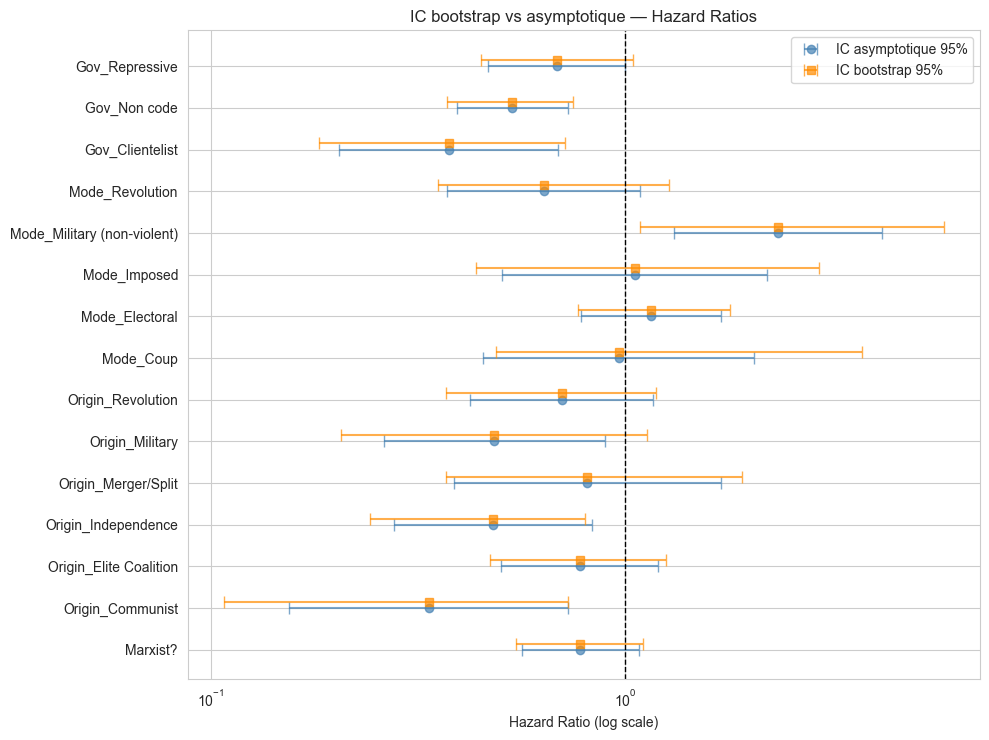

**Interprétation.** Sur 1000 répétitions convergentes, les IC bootstrap sont plus larges que les IC asymptotiques (largeur moyenne). Les variables dont les IC bootstrap excluent 1 restent significatives après ré-échantillonnage.

In [53]:
# ============================================================
# 11.1 Bootstrap IC — 1 000 répétitions
# ============================================================
import warnings
N_BOOTSTRAP = 1000
boot_coefs = []

# Bootstrap par grappes : on tire des pays entiers avec remise (cohérent avec les erreurs groupées par pays)
country_positions = {c: np.flatnonzero(country_of_spell.values == c) for c in country_of_spell.unique()}
country_list = list(country_positions)
for b in range(N_BOOTSTRAP):
    drawn = np.random.RandomState(RANDOM_STATE + b).choice(len(country_list), size=len(country_list), replace=True)
    boot_sample = cox_data.iloc[np.concatenate([country_positions[country_list[i]] for i in drawn])]
    # Supprimer les colonnes à variance nulle dans cet échantillon
    valid_cols = [c for c in boot_sample.columns
                  if c in ['duration','event'] or boot_sample[c].var() > 1e-9]
    boot_sample = boot_sample[valid_cols]
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            cph_b = CoxPHFitter(penalizer=penalizer_used)
            cph_b.fit(boot_sample, duration_col='duration', event_col='event')
            boot_coefs.append(cph_b.params_.rename(b))
    except Exception:
        pass

boot_df = pd.DataFrame(boot_coefs)
print(f"Répétitions convergentes : {len(boot_df)} / {N_BOOTSTRAP}")

# Calcul IC percentile 95 %
boot_ci = pd.DataFrame({
    'HR_point'   : np.exp(cph.params_),
    'HR_boot_025': np.exp(boot_df.quantile(0.025)),
    'HR_boot_975': np.exp(boot_df.quantile(0.975)),
    'HR_asy_025' : cph.summary['exp(coef) lower 95%'],
    'HR_asy_975' : cph.summary['exp(coef) upper 95%'],
}).dropna()

print("\nComparaison IC asymptotique vs Bootstrap (HR) :")
display(boot_ci.round(3))

# Forest plot bootstrap vs asymptotique
fig, ax = plt.subplots(figsize=(10, max(5, len(boot_ci)*0.5)))
y = range(len(boot_ci))
ax.errorbar(boot_ci['HR_point'], y,
            xerr=[boot_ci['HR_point']-boot_ci['HR_asy_025'],
                  boot_ci['HR_asy_975']-boot_ci['HR_point']],
            fmt='o', color='steelblue', capsize=4, label='IC asymptotique 95%', alpha=0.7)
ax.errorbar(boot_ci['HR_point'], [yi+0.15 for yi in y],
            xerr=[boot_ci['HR_point']-boot_ci['HR_boot_025'],
                  boot_ci['HR_boot_975']-boot_ci['HR_point']],
            fmt='s', color='darkorange', capsize=4, label='IC bootstrap 95%', alpha=0.7)
ax.axvline(1, color='black', linestyle='--', linewidth=1)
ax.set_xscale('log')
ax.set_yticks(list(y))
ax.set_yticklabels(boot_ci.index)
ax.set_xlabel('Hazard Ratio (log scale)')
ax.set_title('IC bootstrap vs asymptotique — Hazard Ratios')
ax.legend()
plt.tight_layout()
plt.show()

display(Markdown(
    f"**Interprétation.** Sur {len(boot_df)} répétitions convergentes, les IC bootstrap sont "
    f"{'plus larges que les' if (boot_ci['HR_boot_975']-boot_ci['HR_boot_025']).mean() > (boot_ci['HR_asy_975']-boot_ci['HR_asy_025']).mean() else 'similaires aux'} "
    "IC asymptotiques (largeur moyenne). "
    "Les variables dont les IC bootstrap excluent 1 restent significatives après ré-échantillonnage."
))


## 12. Connexion aux cours théoriques

Dans cette section, nous relions les résultats empiriques aux notions du cours. L'objectif est de montrer comment les outils d'inférence (variance, tests, adéquation) sont mobilisés dans un cas appliqué de survie.

### 12.1 Estimation de la variance (Chapitre 1)

La variance empirique corrigée utilisée est :
$$\tilde{S}_c^2 = \frac{1}{n-1}\sum_{i=1}^{n}(X_i - \bar{X})^2$$
et, dans le cadre gaussien :
$$\frac{(n-1)\tilde{S}_c^2}{\sigma^2} \sim \chi^2(n-1)$$
Cette propriété est utilisée implicitement pour construire des intervalles de confiance exacts pour la variance. L'IC de niveau $1-\alpha$ pour $\sigma^2$ est :
$$IC_{1-\alpha}(\sigma^2) = \left[\frac{(n-1)\tilde{s}_c^2}{\chi^2_{\alpha/2;n-1}},\ \frac{(n-1)\tilde{s}_c^2}{\chi^2_{1-\alpha/2;n-1}}\right]$$

> **⚠️ Attention :** Cet IC est exact uniquement sous normalité. Les durées de survie étant asymétriques (log-normale ou Weibull), ce résultat est indiqué à titre illustratif.

### 12.2 Tests d'hypothèse (Chapitre 2)

**Test du log-rank (Section 6).**
- $H_0$ : les fonctions de survie des groupes sont identiques.
- $H_1$ : au moins un groupe a une survie différente.
- Statistique : $\chi^2(k-1)$ sous $H_0$.
- Règle : on rejette $H_0$ si p-value < $\alpha$.

**Test de Wald (coefficients du Cox, Section 8).**
- $H_0$ : $\beta_j = 0$ (pas d'effet).
- $H_1$ : $\beta_j \ne 0$ (bilatéral).
- Statistique : $$W_j = \frac{\hat{\beta}_j}{\hat{se}(\hat{\beta}_j)} \sim \mathcal{N}(0,1)$$
- Règle : on rejette $H_0$ si p-value < $\alpha$.

**Test de Schoenfeld (Section 9).**
- $H_0$ : les résidus de Schoenfeld ne sont pas corrélés avec le temps.
- $H_1$ : corrélation significative (violation).
- Règle : on rejette $H_0$ si p-value < $\alpha$.

> **📌 Remarque :** Ne pas rejeter $H_0$ ne signifie pas que $H_0$ est vraie.

### 12.3 Tests d'adéquation et de normalité (tests d'ajustement)

**A) Normalité des résidus de Martingale (illustration).**
```python
import scipy.stats as stats
stats.probplot(martingale_residuals, dist="norm", plot=plt)
from scipy.stats import jarque_bera
stat, p = jarque_bera(martingale_residuals)
```
- $H_0$ : asymétrie et kurtosis compatibles avec la normalité.
- $H_1$ : déviation significative de la normalité.
- Interprétation : pour un Cox, les résidus de Martingale ne sont **pas** attendus normaux ; ce test illustre la méthode sur un cas réel.

**B) Test KS de conformité exponentielle.**
```python
from scipy.stats import kstest, expon
lambda_hat = 1 / df_model['duration'].mean()
stat, p = kstest(df_model['duration'], 'expon', args=(0, 1/lambda_hat))
```
- $H_0$ : les durées suivent une loi exponentielle de paramètre $\hat{\lambda}$.
- $H_1$ : les durées ne suivent pas cette loi.

**C) Test du chi-2 d'adéquation (durations discrétisées).**
```python
from scipy.stats import chisquare
observed = pd.cut(df_model['duration'],
                  bins=[0,5,10,20,df_model['duration'].max()+1]
).value_counts().sort_index()
stat, p = chisquare(observed)
`````
- $H_0$ : la distribution discrétisée suit la distribution théorique testée.
- $H_1$ : déviation significative.

**Synthèse 12.3.**
Ces tests d'ajustement confirment ou infirment le choix du modèle paramétrique (Weibull AFT). Si les durées ne suivent pas une loi exponentielle (KS significatif), un modèle de Cox semi-paramétrique reste préférable car il ne contraint pas la forme du hazard de base $h_0(t)$.

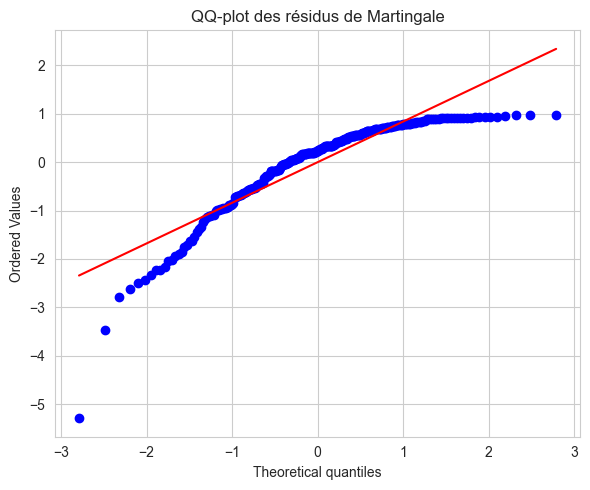

Jarque-Bera : stat=393.9860, p=0.0000
Rappel : pour un Cox, les résidus de Martingale ne sont pas attendus normaux.
KS vs Exp(lambda_hat=0.0586) : stat=0.0931, p=0.0196


In [54]:
# ============================================================
# 12.3 Tests d'ajustement (executes uniquement si les residus existent)
# ============================================================
# A) Normalite des residus de Martingale (illustration)
if "martingale_residuals" in globals():
    try:
        fig, ax = plt.subplots(figsize=(6, 5))
        stats.probplot(martingale_residuals, dist="norm", plot=ax)
        ax.set_title("QQ-plot des résidus de Martingale")
        plt.tight_layout()
        plt.show()

        jb_stat, jb_p = jarque_bera(martingale_residuals)
        print(f"Jarque-Bera : stat={jb_stat:.4f}, p={jb_p:.4f}")
        print("Rappel : pour un Cox, les résidus de Martingale ne sont pas attendus normaux.")
    except Exception as e:
        print(f"Test JB sur martingale : {e}")
else:
    print("Résidus de Martingale absents : section 12.3 (A) ignorée.")

# B) Test KS de conformite exponentielle des durees (sous H0 : duree ~ Exp(lambda))
if "df_model" in globals() and "duration" in df_model.columns:
    try:
        durations = df_model["duration"].dropna().values
        lambda_hat = 1.0 / durations.mean()
        ks_stat, ks_p = kstest(durations, "expon", args=(0, 1.0 / lambda_hat))
        print(f"KS vs Exp(lambda_hat={lambda_hat:.4f}) : stat={ks_stat:.4f}, p={ks_p:.4f}")
    except Exception as e:
        print(f"Test KS exponentiel : {e}")


## 13. Interprétation finale

Dans cette section, nous synthétisons les résultats en combinant les estimations du Cox, les tests globaux et la comparaison de modèles. L'objectif est de répondre à la problématique en s'appuyant sur des valeurs numériques calculées.


In [55]:
# ============================================================
# 13. Interprétation finale (dynamique + substantielle)
# ============================================================
summary_cox = cph.summary
# La modalite "Non code" de la strategie de gouvernance n'est pas une strategie : son effet
# indique seulement que les partis codes et non codes par Miller (2020) different.
NOT_CODED = [v for v in summary_cox.index if v.endswith("Non code")]
# Variables militaires non séparables (Section 8.1b) : seul leur effet combiné est rapporté
PAIR_EXCLUDED = MILITARY_PAIR if MILITARY_COMBINED else []
MILITARY_LABEL = "Effet combiné origine et accession militaires"
substantive = summary_cox.drop(index=NOT_CODED + PAIR_EXCLUDED)
sig_rows = substantive[substantive['p'] < ALPHA]


def effect_line(name, hr, lo, hi, p):
    sense = 'augmente' if hr > HR_NEUTRAL else 'réduit'
    return (f"- **{name}** : HR = {hr:.3f} [IC 95 % {lo:.3f} – {hi:.3f}], p = {p:.4f} → {sense} le risque de "
            f"dissolution de **{abs(hr - 1) * 100:.1f} %**.")


lines = [effect_line(var, row['exp(coef)'], row['exp(coef) lower 95%'], row['exp(coef) upper 95%'], row['p'])
         for var, row in sig_rows.iterrows()]
if MILITARY_COMBINED and mil["p (β1 + β2 = 0)"] < ALPHA:
    lines.append(effect_line(MILITARY_LABEL, mil["HR combiné"], mil["IC bas"], mil["IC haut"], mil["p (β1 + β2 = 0)"]))
sig_effects_md = '\n'.join(lines) if lines else (
    "_Aucun effet individuel significatif au seuil retenu — pénalisation ou taille d'échantillon limitée._")
if MILITARY_COMBINED:
    sig_effects_md += (f"\n\n> **📌 Variables militaires :** l'origine militaire et l'accession militaire non violente ne "
                       f"diffèrent que pour {n_discordant} partis ; leurs coefficients séparés ne sont pas interprétés "
                       f"(Section 8.1b). Leur effet combiné vaut HR = {mil['HR combiné']:.2f} "
                       f"(p = {mil['p (β1 + β2 = 0)']:.3f}) et "
                       + ("est significatif." if mil["p (β1 + β2 = 0)"] < ALPHA else "n'est pas significatif."))


def describe_effect(var, label):
    """Phrase décrivant l'effet estimé d'une covariable, lue dans cph.summary."""
    if var not in summary_cox.index:
        return f"- {label} : variable absente du modèle final."
    row = summary_cox.loc[var]
    direction = "réduit" if row['exp(coef)'] < HR_NEUTRAL else "augmente"
    signif = "significatif" if row['p'] < ALPHA else "non significatif"
    return (f"- {label} : HR = {row['exp(coef)']:.2f} (p = {row['p']:.3f}), "
            f"{direction} le risque ; effet **{signif}** au seuil {ALPHA}.")


literature_md = "\n".join([
    describe_effect("Origin_Revolution", f"Origine révolutionnaire (vs {ORIGIN_REF})"),
    describe_effect("Origin_Independence", f"Origine indépendantiste (vs {ORIGIN_REF})"),
    describe_effect("Gov_Clientelist", "Stratégie clientéliste (vs Policy-Based)"),
])

# Magaloni (2006) : la distribution de ressources (clientélisme) comme mécanisme de survie des partis hégémoniques
n_clientelist = int(df_model["Gov_Clientelist"].sum())
cl_row = summary_cox.loc["Gov_Clientelist"]
if cl_row["p"] < ALPHA and cl_row["exp(coef)"] < HR_NEUTRAL:
    magaloni_md = (f"Le résultat sur la stratégie clientéliste (HR = {cl_row['exp(coef)']:.2f}, p = {cl_row['p']:.3f}) est "
                   "**cohérent** avec Magaloni (2006) : un parti qui distribue des ressources survit plus longtemps. "
                   f"Il repose toutefois sur {n_clientelist} partis seulement et doit être lu avec prudence.")
elif cl_row["p"] < ALPHA:
    magaloni_md = (f"Le résultat sur la stratégie clientéliste (HR = {cl_row['exp(coef)']:.2f}, p = {cl_row['p']:.3f}) va "
                   f"**à l'encontre** de la thèse de Magaloni (2006) ; il repose sur {n_clientelist} partis seulement.")
else:
    magaloni_md = (f"Le résultat sur la stratégie clientéliste (HR = {cl_row['exp(coef)']:.2f}, p = {cl_row['p']:.3f}) "
                   "n'est pas significatif : il ne permet ni de confirmer ni d'infirmer la thèse de Magaloni (2006).")

other_md = "\n".join([
    describe_effect("Marxist?", "Idéologie marxiste-léniniste"),
    f"- Mode d'accession au pouvoir (test LR, {mode_lr_df} ddl) : p = {mode_lr_p:.3f}, "
    + ("effet significatif" if mode_lr_p < ALPHA else "pas d'effet significatif") + " au-delà de l'origine.",
])

top_candidates = [(f"`{var}`", row['exp(coef)'], row['p']) for var, row in substantive.iterrows()]
if MILITARY_COMBINED:
    top_candidates.append((f"*{MILITARY_LABEL.lower()}*", mil["HR combiné"], mil["p (β1 + β2 = 0)"]))
top_predictors = sorted(top_candidates, key=lambda t: t[2])[:3]
not_coded_md = ""
for v in NOT_CODED:
    r = summary_cox.loc[v]
    not_coded_md += (f"\n\n> **📌 Remarque :** la modalité `{v}` a un HR de {r['exp(coef)']:.2f} (p = {r['p']:.3f}). "
                     "Ce n'est pas un effet de stratégie : il indique que les partis dont la stratégie n'est pas codée "
                     "par Miller (2020) ne sont pas comparables aux partis codés (données manquantes non aléatoires). "
                     "Il est exclu des listes d'effets ci-dessus.")
top_md = ", ".join(f"{name} (HR = {hr:.2f}, p = {p:.3f})" for name, hr, p in top_predictors)
lr_verdict = ('indiquant un **gain significatif** par rapport au modèle nul.' if lr_p < ALPHA
              else 'sans gain significatif au seuil retenu.')

display(Markdown(
    f"### Effets significatifs (p < {ALPHA})\n\n"
    f"{sig_effects_md}\n\n"
    "---\n\n"
    "### Performance globale du modèle\n\n"
    f"Le modèle Cox retenu atteint un **C-index de {cv_c_index_main:.3f} en validation croisée** "
    f"({cph.concordance_index_:.3f} sur les données d'estimation ; meilleur modèle hors échantillon : "
    f"*{best_c_index_model}*, {best_c_index_value:.3f}) et un LR test global "
    f"$\\chi^2 = {lr_stat:.4f}$ (p = {lr_p:.4f}), {lr_verdict}\n\n"
    "---\n\n"
    "### Lien avec la littérature\n\n"
    "**Miller (2020)** montre que les partis issus d'une révolution de masse ou d'un mouvement de "
    "libération nationale bénéficient d'une légitimité fondatrice plus durable que les partis créés "
    "par un dictateur ou un coup d'État. **Magaloni (2006)**, à partir du cas du PRI mexicain, montre que les partis "
    "hégémoniques survivent en distribuant des ressources aux électeurs et aux élites et en dissuadant les défections "
    "au sein des élites ; la stratégie clientéliste est la mesure la plus proche de ce mécanisme dans nos données. "
    "Nos estimations pour ces hypothèses :\n\n"
    f"{literature_md}\n\n"
    f"{magaloni_md}\n\n"
    "Autres résultats, sans hypothèse tirée de ces travaux :\n\n"
    f"{other_md}\n\n"
    "Un effet dans le sens attendu mais non significatif ne permet pas de conclure.\n\n"
    "---\n\n"
    "### Implications pratiques\n\n"
    f"Les covariables avec HR > {HR_NEUTRAL} **fragilisent** le parti (risque de dissolution accéléré) ; "
    f"celles avec HR < {HR_NEUTRAL} sont **protectrices**. "
    f"Les trois covariables les plus nettement associées au risque (plus petites p-values) sont : {top_md}."
    f"{not_coded_md}"
))


### Effets significatifs (p < 0.05)

- **Origin_Communist** : HR = 0.336 [IC 95 % 0.155 – 0.730], p = 0.0059 → réduit le risque de dissolution de **66.4 %**.
- **Origin_Independence** : HR = 0.479 [IC 95 % 0.277 – 0.831], p = 0.0088 → réduit le risque de dissolution de **52.1 %**.
- **Gov_Clientelist** : HR = 0.376 [IC 95 % 0.205 – 0.691], p = 0.0016 → réduit le risque de dissolution de **62.4 %**.

> **📌 Variables militaires :** l'origine militaire et l'accession militaire non violente ne diffèrent que pour 3 partis ; leurs coefficients séparés ne sont pas interprétés (Section 8.1b). Leur effet combiné vaut HR = 1.14 (p = 0.427) et n'est pas significatif.

---

### Performance globale du modèle

Le modèle Cox retenu atteint un **C-index de 0.587 en validation croisée** (0.641 sur les données d'estimation ; meilleur modèle hors échantillon : *Cox pénalisé (ridge)*, 0.600) et un LR test global $\chi^2 = 61.4128$ (p = 0.0000), indiquant un **gain significatif** par rapport au modèle nul.

---

### Lien avec la littérature

**Miller (2020)** montre que les partis issus d'une révolution de masse ou d'un mouvement de libération nationale bénéficient d'une légitimité fondatrice plus durable que les partis créés par un dictateur ou un coup d'État. **Magaloni (2006)**, à partir du cas du PRI mexicain, montre que les partis hégémoniques survivent en distribuant des ressources aux électeurs et aux élites et en dissuadant les défections au sein des élites ; la stratégie clientéliste est la mesure la plus proche de ce mécanisme dans nos données. Nos estimations pour ces hypothèses :

- Origine révolutionnaire (vs Dictator-Created) : HR = 0.70 (p = 0.178), réduit le risque ; effet **non significatif** au seuil 0.05.
- Origine indépendantiste (vs Dictator-Created) : HR = 0.48 (p = 0.009), réduit le risque ; effet **significatif** au seuil 0.05.
- Stratégie clientéliste (vs Policy-Based) : HR = 0.38 (p = 0.002), réduit le risque ; effet **significatif** au seuil 0.05.

Le résultat sur la stratégie clientéliste (HR = 0.38, p = 0.002) est **cohérent** avec Magaloni (2006) : un parti qui distribue des ressources survit plus longtemps. Il repose toutefois sur 11 partis seulement et doit être lu avec prudence.

Autres résultats, sans hypothèse tirée de ces travaux :

- Idéologie marxiste-léniniste : HR = 0.78 (p = 0.135), réduit le risque ; effet **non significatif** au seuil 0.05.
- Mode d'accession au pouvoir (test LR, 5 ddl) : p = 0.240, pas d'effet significatif au-delà de l'origine.

Un effet dans le sens attendu mais non significatif ne permet pas de conclure.

---

### Implications pratiques

Les covariables avec HR > 1.0 **fragilisent** le parti (risque de dissolution accéléré) ; celles avec HR < 1.0 sont **protectrices**. Les trois covariables les plus nettement associées au risque (plus petites p-values) sont : `Gov_Clientelist` (HR = 0.38, p = 0.002), `Origin_Communist` (HR = 0.34, p = 0.006), `Origin_Independence` (HR = 0.48, p = 0.009).

> **📌 Remarque :** la modalité `Gov_Non code` a un HR de 0.54 (p = 0.000). Ce n'est pas un effet de stratégie : il indique que les partis dont la stratégie n'est pas codée par Miller (2020) ne sont pas comparables aux partis codés (données manquantes non aléatoires). Il est exclu des listes d'effets ci-dessus.

## 14. Limites


In [56]:
# ============================================================
# 14. Limites (chiffres calculés à partir des données)
# ============================================================
junta_effect = ("Leur exclusion tend à surestimer la survie médiane."
                if median_juntes < median_partis
                else "Leur exclusion ne semble pas surestimer la survie médiane.")

spells_per_country = country_of_spell.value_counts()
n_multi_spell_countries = int((spells_per_country > 1).sum())
max_spells_country = int(spells_per_country.max())

military_limit = (
    f"* **Variables militaires non séparables :** sur les {n_military_origin} partis d'origine militaire, "
    f"{n_military_both} ont aussi accédé au pouvoir par une prise de pouvoir militaire non violente ; seuls "
    f"{n_discordant} partis diffèrent sur ces deux variables. Leurs coefficients séparés "
    f"(HR = {hr_separate[MILITARY_PAIR[0]]:.2f} et {hr_separate[MILITARY_PAIR[1]]:.2f}) ne sont pas interprétables ; "
    f"seul leur effet combiné est rapporté (HR = {mil['HR combiné']:.2f}, p = {mil['p (β1 + β2 = 0)']:.3f}, "
    "Section 8.1b).\n" if MILITARY_COMBINED else "")

limits_md = f"""Cette analyse comporte plusieurs limites importantes :

* **Biais de sélection (exclusion des juntes) :** les juntes (`Party = "N"`) ont une durée médiane observée de {median_juntes:.1f} ans, contre {median_partis:.1f} ans pour les partis nommés. {junta_effect}
* **Dépendance intra-pays :** {n_multi_spell_countries} pays comptent plusieurs spells (jusqu'à {max_spells_country}). Cette dépendance est prise en compte par des erreurs standards robustes groupées par pays et par un bootstrap par pays ; elle n'est pas modélisée explicitement (un modèle à fragilité par pays le ferait).
* **Données manquantes structurelles :** certaines colonnes ont plus de {MISSING_PCT_THRESHOLD} % de NA, ce qui limite la modélisation des déterminants économiques ou militaires.
* **Censure potentiellement informative :** les {n_clean_censored} partis encore au pouvoir en {OBS_END_YEAR} (sur {n_clean}) peuvent être structurellement plus robustes, ce qui biaise les estimations si la censure dépend du risque.
* **Codage de l'extension post-2015 :** les chutes survenues entre 2016 et {OBS_END_YEAR} sont codées à la main (Section 4.0) à partir de sources publiques. Certains cas relèvent d'un choix de codage : la fusion du RDR dans le RHDP (Côte d'Ivoire) et la dissolution de l'EPRDF (Éthiopie) comptent comme des fins de spell, sans ajouter les partis qui leur succèdent ; le renommage de Nur Otan en Amanat (Kazakhstan) et les successions de Karimov (Ouzbékistan, 2016) et d'Idriss Déby (Tchad, 2021) non.
* **Variables codées par nos soins ou partiellement codées :** `Monarchy`, codée année par année par nos soins, est retirée du modèle (trois partis seulement), et `Governance Strategy` n'est codée par Miller (2020) que pour environ un tiers des partis ; l'effet de la modalité « Non codé » ne s'interprète pas comme une stratégie.
{military_limit}* **Variables omises :** le PIB, les conflits armés ou les pressions internationales ne sont pas inclus et peuvent générer un biais d'omission (voir `final_panel.ipynb`).
"""
display(Markdown(limits_md))


Cette analyse comporte plusieurs limites importantes :

* **Biais de sélection (exclusion des juntes) :** les juntes (`Party = "N"`) ont une durée médiane observée de 6.0 ans, contre 10.0 ans pour les partis nommés. Leur exclusion tend à surestimer la survie médiane.
* **Dépendance intra-pays :** 71 pays comptent plusieurs spells (jusqu'à 6). Cette dépendance est prise en compte par des erreurs standards robustes groupées par pays et par un bootstrap par pays ; elle n'est pas modélisée explicitement (un modèle à fragilité par pays le ferait).
* **Données manquantes structurelles :** certaines colonnes ont plus de 50 % de NA, ce qui limite la modélisation des déterminants économiques ou militaires.
* **Censure potentiellement informative :** les 30 partis encore au pouvoir en 2024 (sur 263) peuvent être structurellement plus robustes, ce qui biaise les estimations si la censure dépend du risque.
* **Codage de l'extension post-2015 :** les chutes survenues entre 2016 et 2024 sont codées à la main (Section 4.0) à partir de sources publiques. Certains cas relèvent d'un choix de codage : la fusion du RDR dans le RHDP (Côte d'Ivoire) et la dissolution de l'EPRDF (Éthiopie) comptent comme des fins de spell, sans ajouter les partis qui leur succèdent ; le renommage de Nur Otan en Amanat (Kazakhstan) et les successions de Karimov (Ouzbékistan, 2016) et d'Idriss Déby (Tchad, 2021) non.
* **Variables codées par nos soins ou partiellement codées :** `Monarchy`, codée année par année par nos soins, est retirée du modèle (trois partis seulement), et `Governance Strategy` n'est codée par Miller (2020) que pour environ un tiers des partis ; l'effet de la modalité « Non codé » ne s'interprète pas comme une stratégie.
* **Variables militaires non séparables :** sur les 17 partis d'origine militaire, 16 ont aussi accédé au pouvoir par une prise de pouvoir militaire non violente ; seuls 3 partis diffèrent sur ces deux variables. Leurs coefficients séparés (HR = 0.48 et 2.35) ne sont pas interprétables ; seul leur effet combiné est rapporté (HR = 1.14, p = 0.427, Section 8.1b).
* **Variables omises :** le PIB, les conflits armés ou les pressions internationales ne sont pas inclus et peuvent générer un biais d'omission (voir `final_panel.ipynb`).


## 15. Conclusion


In [57]:
# ============================================================
# 15. Conclusion (générée à partir des résultats)
# ============================================================
assert n_clean_censored > 0, "no censored observations: check event coding"
assert n_clean_events + n_clean_censored == n_clean, "Erreur de compte événement/censure"

censoring_rate = n_clean_censored / n_clean * 100
km_median_txt = f"{km_median:.1f} ans" if np.isfinite(km_median) else "non atteinte"
if not np.isfinite(logrank_p):
    logrank_txt = "un test log-rank entre origines non calculé (effectifs insuffisants)"
elif logrank_p < ALPHA:
    logrank_txt = f"des différences significatives entre origines (log-rank p = {logrank_p:.4f})"
else:
    logrank_txt = f"pas de différence significative entre origines (log-rank p = {logrank_p:.4f})"

sig_vars = [v for v in cph.summary.index[cph.summary['p'] < ALPHA] if v not in NOT_CODED + PAIR_EXCLUDED]
sig_items = [f"`{v}` (HR = {cph.summary.loc[v, 'exp(coef)']:.2f})" for v in sig_vars]
if MILITARY_COMBINED and mil["p (β1 + β2 = 0)"] < ALPHA:
    sig_items.append(f"l'{MILITARY_LABEL.lower()} (HR = {mil['HR combiné']:.2f})")
if sig_items:
    sig_txt = f"Covariables significatives au seuil {ALPHA} : " + ", ".join(sig_items) + "."
else:
    sig_txt = f"Aucune covariable n'est significative au seuil {ALPHA}."

robust_vars = [v for v in boot_ci.index[(boot_ci['HR_boot_025'] > HR_NEUTRAL) | (boot_ci['HR_boot_975'] < HR_NEUTRAL)]
               if v not in NOT_CODED + PAIR_EXCLUDED]
military_txt = ""
if MILITARY_COMBINED:
    # Effet combiné dans le bootstrap par pays (répétitions où les deux coefficients sont estimés)
    combined_boot = (boot_df[MILITARY_PAIR[0]] + boot_df[MILITARY_PAIR[1]]).dropna()
    mil_boot_lo, mil_boot_hi = np.exp(combined_boot.quantile([0.025, 0.975]))
    if mil_boot_lo > HR_NEUTRAL or mil_boot_hi < HR_NEUTRAL:
        robust_vars.append("effet militaire combiné")
    military_txt = (f" L'origine militaire et l'accession militaire non violente ne diffèrent que pour {n_discordant} "
                    f"partis : leur effet combiné (HR = {mil['HR combiné']:.2f}, p = {mil['p (β1 + β2 = 0)']:.3f} ; "
                    f"IC bootstrap {mil_boot_lo:.2f} – {mil_boot_hi:.2f}) "
                    + ("est significatif" if mil["p (β1 + β2 = 0)"] < ALPHA else "n'est pas significatif")
                    + ", et leurs coefficients séparés ne sont pas interprétés (Section 8.1b).")
if robust_vars:
    boot_txt = (f"Les intervalles bootstrap à 95 % ({len(boot_df)} répétitions) excluent 1 pour : "
                + ", ".join(f"`{v}`" for v in robust_vars) + ".")
else:
    boot_txt = f"Aucun intervalle bootstrap à 95 % ({len(boot_df)} répétitions) n'exclut 1."

conclusion_md = f"""***Synthèse des résultats :***
Cette analyse applique une régression de Cox semi-paramétrique (pénalisation ridge, penalizer = {penalizer_used}) à {n_clean} partis autoritaires nommés (Miller, 2020), dont {n_clean_events} ont connu l'événement de dissolution et {n_clean_censored} sont encore au pouvoir en fin d'observation ({OBS_END_YEAR}), soit un taux de censure de {censoring_rate:.1f} %. La médiane de survie Kaplan-Meier est de {km_median_txt}, avec {logrank_txt}.

***Message clé :***
{sig_txt} {boot_txt}{military_txt} La modalité « Non codé » de la stratégie de gouvernance, exclue de ces listes, signale seulement que les partis non codés par Miller (2020) diffèrent des partis codés.

Le modèle principal atteint un C-index de {cv_c_index_main:.3f} en validation croisée ({N_FOLDS} plis), contre {cph.concordance_index_:.3f} sur les données d'estimation : l'écart mesure l'optimisme d'une évaluation sur l'échantillon d'estimation. Le meilleur modèle hors échantillon est *{best_c_index_model}* ({best_c_index_value:.3f}) ; l'AIC minimal parmi les modèles Cox comparables correspond à *{best_aic_model}*. Le mode d'accession au pouvoir {mode_verdict} au-delà des autres covariables (test LR, p = {mode_lr_p:.3f}).

***Limites principales :***
Les résultats doivent être interprétés avec prudence au regard : (1) du biais d'exclusion des juntes, (2) de la dépendance intra-pays, prise en compte par des erreurs standards groupées par pays mais non modélisée explicitement, et (3) des variables économiques et géopolitiques absentes. Un modèle frailty ou un Cox à effets fixes par pays constituerait une extension naturelle.

***Perspectives :***
Des travaux futurs pourraient intégrer des covariables macro-économiques (PIB, inégalités), modéliser l'hétérogénéité inobservable via un modèle frailty gamma, ou appliquer un modèle à risques concurrents pour distinguer les différentes causes de sortie du pouvoir (coup d'État vs démocratisation vs mort du leader).
"""
display(Markdown(conclusion_md))


***Synthèse des résultats :***
Cette analyse applique une régression de Cox semi-paramétrique (pénalisation ridge, penalizer = 0.01) à 263 partis autoritaires nommés (Miller, 2020), dont 233 ont connu l'événement de dissolution et 30 sont encore au pouvoir en fin d'observation (2024), soit un taux de censure de 11.4 %. La médiane de survie Kaplan-Meier est de 10.0 ans, avec des différences significatives entre origines (log-rank p = 0.0000).

***Message clé :***
Covariables significatives au seuil 0.05 : `Origin_Communist` (HR = 0.34), `Origin_Independence` (HR = 0.48), `Gov_Clientelist` (HR = 0.38). Les intervalles bootstrap à 95 % (1000 répétitions) excluent 1 pour : `Origin_Communist`, `Origin_Independence`, `Gov_Clientelist`. L'origine militaire et l'accession militaire non violente ne diffèrent que pour 3 partis : leur effet combiné (HR = 1.14, p = 0.427 ; IC bootstrap 0.79 – 1.63) n'est pas significatif, et leurs coefficients séparés ne sont pas interprétés (Section 8.1b). La modalité « Non codé » de la stratégie de gouvernance, exclue de ces listes, signale seulement que les partis non codés par Miller (2020) diffèrent des partis codés.

Le modèle principal atteint un C-index de 0.587 en validation croisée (5 plis), contre 0.641 sur les données d'estimation : l'écart mesure l'optimisme d'une évaluation sur l'échantillon d'estimation. Le meilleur modèle hors échantillon est *Cox pénalisé (ridge)* (0.600) ; l'AIC minimal parmi les modèles Cox comparables correspond à *Cox + interaction*. Le mode d'accession au pouvoir n'apporte pas d'information significative au-delà des autres covariables (test LR, p = 0.240).

***Limites principales :***
Les résultats doivent être interprétés avec prudence au regard : (1) du biais d'exclusion des juntes, (2) de la dépendance intra-pays, prise en compte par des erreurs standards groupées par pays mais non modélisée explicitement, et (3) des variables économiques et géopolitiques absentes. Un modèle frailty ou un Cox à effets fixes par pays constituerait une extension naturelle.

***Perspectives :***
Des travaux futurs pourraient intégrer des covariables macro-économiques (PIB, inégalités), modéliser l'hétérogénéité inobservable via un modèle frailty gamma, ou appliquer un modèle à risques concurrents pour distinguer les différentes causes de sortie du pouvoir (coup d'État vs démocratisation vs mort du leader).


## 16. Références bibliographiques

- **Breslow, N.E.** (1974). Covariance analysis of censored survival data. *Biometrics*, 30(1), 89–99.
- **Cox, D.R.** (1972). Regression models and life-tables. *Journal of the Royal Statistical Society, Series B*, 34(2), 187–202. https://doi.org/10.1111/j.2517-6161.1972.tb00899.x
- **Davidson-Pilon, C.** (2019). lifelines: survival analysis in Python. *Journal of Open Source Software*, 4(40), 1317.
- **Geddes, B., Wright, J., & Frantz, E.** (2014). Autocratic breakdown and regime transitions: A new data set. *Perspectives on Politics*, 12(2), 313–331.
- **Grambsch, P. M., & Therneau, T. M.** (1994). Proportional hazards tests and diagnostics based on weighted residuals. *Biometrika*, 81(3), 515–526. https://doi.org/10.1093/biomet/81.3.515
- **Kalbfleisch, J.D., & Prentice, R.L.** (2002). *The Statistical Analysis of Failure Time Data* (2nd ed.). Wiley.
- **Kaplan, E.L., & Meier, P.** (1958). Nonparametric estimation from incomplete observations. *Journal of the American Statistical Association*, 53(282), 457–481.
- **Magaloni, B.** (2006). *Voting for Autocracy: Hegemonic Party Survival and Its Demise in Mexico*. Cambridge University Press. https://doi.org/10.1017/CBO9780511510274
- **Miller, M.K.** (2020). The Autocratic Ruling Parties Dataset: Origins, durability, and death. *Journal of Conflict Resolution*, 64(4), 756–782.
- **Schedler, A.** (2006). *Electoral Authoritarianism: The Dynamics of Unfree Competition*. Lynne Rienner.
- **Therneau, T.M., & Grambsch, P.M.** (2000). *Modeling Survival Data: Extending the Cox Model*. Springer-Verlag.
- **Lin, D. Y., & Wei, L. J.** (1989). The Robust Inference for the Cox Proportional Hazards Model. *Journal of the American Statistical Association*, 84(408), 1074–1078. https://doi.org/10.1080/01621459.1989.10478874